## NECESSARY LIBRARIES

In [1]:
# ============================================================
# CELL 1: REQUIRED LIBRARIES
# ============================================================

# Core Data Processing and Visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
import joblib
import os
import json
from pathlib import Path

# Machine Learning - Preprocessing & Balancing
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV,
    cross_val_score, cross_val_predict
)

# Machine Learning - Classical & Ensemble Algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# Deep Learning Framework (TensorFlow & Keras)
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Dense, Dropout, Input, Conv1D, MaxPooling1D,
    GlobalMaxPooling1D, GlobalAveragePooling1D,
    Flatten, Add, BatchNormalization, Activation, GRU, LSTM
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# Machine Learning - Metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    auc,
    matthews_corrcoef,
    f1_score,
    precision_score,
    recall_score,
    average_precision_score,
    cohen_kappa_score
)

# Statistical Analysis
import scipy.stats as stats
try:
    import scikit_posthocs as sp
    POSTHOCS_AVAILABLE = True
except ImportError:
    POSTHOCS_AVAILABLE = False
    print('Warning: scikit-posthocs not available. Install: pip install scikit-posthocs')

# Plotting Configuration
plt.style.use('ggplot')
warnings.filterwarnings('ignore')

# Output Directory Setup
OUTPUT_DIR = Path('adhd_results')
OUTPUT_DIR.mkdir(exist_ok=True)

print('Libraries loaded successfully.')
print(f'TensorFlow version: {tf.__version__}')
print(f'scikit-posthocs available: {POSTHOCS_AVAILABLE}')
print(f'Output directory: {OUTPUT_DIR.resolve()}')


Libraries loaded successfully.
TensorFlow version: 2.21.0
scikit-posthocs available: True
Output directory: C:\Users\Maksu\Desktop\ADHD_Research\adhd_results


## GLOBAL SETTINGS and UTILITY FUNCTIONS

In [2]:
# ============================================================
# CELL 2: GLOBAL SETTINGS AND UTILITY FUNCTIONS
# ============================================================

# --- File Paths (portable, using pathlib) ---
BASE_DIR = Path('.')
INPUT_FILE_PATH = str(BASE_DIR / 'adhd_data_realistic.csv')
OUTPUT_FILE_PATH= str(BASE_DIR / 'New_adhd_data.csv')

# --- Categorical Columns ---
BINARY_COLS = ['Gender']

# --- Global Result Storage ---
# --- Storage: JSON + CSV Files ---
OUTPUT_DIR = Path('adhd_results')
OUTPUT_DIR.mkdir(exist_ok=True)
RESULTS_JSON = OUTPUT_DIR / 'model_results.json'
RESULTS_CSV = OUTPUT_DIR / 'model_results.csv'
TIMING_JSON = OUTPUT_DIR / 'model_timing.json'
TIMING_CSV = OUTPUT_DIR / 'model_timing.csv'
FOLDS_JSON = OUTPUT_DIR / 'fold_scores.json'
FOLDS_CSV = OUTPUT_DIR / 'fold_scores.csv'

# ============================================================
# TIME UTILITIES
# ============================================================

def format_time(seconds):
    if seconds < 1:
        return f'{seconds * 1000:.3f} ms'
    return f'{seconds:.4f} sec'

class TimeTracker:
    def __init__(self):
        self._starts = {}
    def start(self, key):
        self._starts[key] = time.perf_counter()
    def stop(self, key):
        return time.perf_counter() - self._starts[key]

timer = TimeTracker()

# ============================================================
# THRESHOLD OPTIMIZATION (CV-BASED MCC)
# ============================================================

def optimize_threshold_cv(model, X, y, cv=5):
    """Find optimal decision threshold by maximizing MCC on CV predictions."""
    cv_pred_proba = cross_val_predict(
        model, X, y, cv=cv, method='predict_proba', n_jobs=-1
    )[:, 1]
    thresholds = np.linspace(0.05, 0.95, 100)
    mcc_scores  = [
        matthews_corrcoef(y, (cv_pred_proba >= t).astype(int))
        for t in thresholds
    ]
    best_idx = np.argmax(mcc_scores)
    return thresholds[best_idx], mcc_scores[best_idx]

# ============================================================
# INFERENCE LATENCY (p50 / p95 / p99 PERCENTILES)
# ============================================================

def measure_inference_latency(model, X, n_warmup=10, n_runs=None):
    """Measure per-sample latency with percentile statistics."""
    if hasattr(X, 'toarray'):
        X = X.toarray()
    n_runs = n_runs or X.shape[0]
    # Warm-up
    model.predict_proba(X[:min(n_warmup, X.shape[0])])
    latencies = []
    for i in range(min(n_runs, X.shape[0])):
        t0 = time.perf_counter()
        model.predict_proba(X[i:i+1])
        latencies.append((time.perf_counter() - t0) * 1000)
    total_sec = sum(latencies) / 1000
    return {
        'total_sec': total_sec,
        'mean_ms'  : float(np.mean(latencies)),
        'p50_ms'   : float(np.percentile(latencies, 50)),
        'p95_ms'   : float(np.percentile(latencies, 95)),
        'p99_ms'   : float(np.percentile(latencies, 99)),
    }

def measure_dl_latency(model, X, n_warmup=5):
    """Measure per-sample latency for Keras/TF models with percentiles."""
    model.predict(X[:n_warmup], verbose=0)
    latencies = []
    for i in range(X.shape[0]):
        t0 = time.perf_counter()
        model.predict(X[i:i+1], verbose=0)
        latencies.append((time.perf_counter() - t0) * 1000)
    total_sec = sum(latencies) / 1000
    return {
        'total_sec': total_sec,
        'mean_ms'  : float(np.mean(latencies)),
        'p50_ms'   : float(np.percentile(latencies, 50)),
        'p95_ms'   : float(np.percentile(latencies, 95)),
        'p99_ms'   : float(np.percentile(latencies, 99)),
    }

# ============================================================
# METRICS COMPUTATION
# ============================================================

def compute_metrics(y_true, y_pred, y_prob):
    """Compute full academic metric suite."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        'Accuracy'  : accuracy_score(y_true, y_pred),
        'Precision' : precision_score(y_true, y_pred, zero_division=0),
        'Recall'    : recall_score(y_true, y_pred, zero_division=0),
        'F1_Score'  : f1_score(y_true, y_pred, zero_division=0),
        'MCC'       : matthews_corrcoef(y_true, y_pred),
        'Kappa'     : cohen_kappa_score(y_true, y_pred),
        'Specificity': tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        'ROC_AUC'   : roc_auc_score(y_true, y_prob),
        'PR_AUC'    : average_precision_score(y_true, y_prob),
        'Confusion_Matrix': np.array([[tn, fp], [fn, tp]])
    }

def print_metrics(metrics, threshold):
    """Print formatted metric summary."""
    print(f'\n  Accuracy  (threshold {threshold:.3f}): {metrics["Accuracy"]:.4f}')
    print(f'  F1-Score  : {metrics["F1_Score"]:.4f}')
    print(f'  ROC-AUC   : {metrics["ROC_AUC"]:.4f}')
    print(f'  PR-AUC    : {metrics["PR_AUC"]:.4f}')
    print(f'  MCC       : {metrics["MCC"]:.4f}')
    print(f'  Kappa     : {metrics["Kappa"]:.4f}')
    print(f'  Specificity: {metrics["Specificity"]:.4f}')

# ============================================================
# CONFUSION MATRIX PLOT (saves to disk)
# ============================================================

def plot_confusion_matrix(cm, model_name, threshold, cmap='Blues', save=True):
    """Plot and optionally save confusion matrix."""
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['No ADHD', 'ADHD']
    ).plot(cmap=cmap, values_format='d', ax=ax)
    ax.set_title(f'{model_name} Confusion Matrix (Threshold {threshold:.3f})', fontsize=11)
    ax.grid(False)
    plt.tight_layout()
    if save:
        path = OUTPUT_DIR / f'cm_{model_name.replace(" ", "_")}.png'
        plt.savefig(path, dpi=200, bbox_inches='tight')
    plt.show()
    plt.close()

# ============================================================
# MODEL SIZE
# ============================================================

def get_model_size_mb(model):
    """Estimate serialized model size in MB."""
    tmp = '_tmp_model_size.pkl'
    joblib.dump(model, tmp)
    size = os.path.getsize(tmp) / (1024 * 1024)
    os.remove(tmp)
    return size

# ============================================================
# BOOTSTRAP CONFIDENCE INTERVAL
# ============================================================

def bootstrap_ci(y_true, y_pred, y_prob, metric='mcc', n_bootstrap=1000, ci=0.95):
    """
    Compute bootstrap 95% CI for a metric.
    metric options: 'mcc', 'kappa', 'roc_auc', 'f1', 'accuracy'
    """
    from sklearn.utils import resample as sk_resample
    n = len(y_true)
    scores = []
    for _ in range(n_bootstrap):
        idx    = sk_resample(np.arange(n), n_samples=n)
        yt, yp, yb = y_true[idx], y_pred[idx], y_prob[idx]
        try:
            if metric == 'mcc'     : scores.append(matthews_corrcoef(yt, yp))
            elif metric == 'kappa' : scores.append(cohen_kappa_score(yt, yp))
            elif metric == 'roc_auc': scores.append(roc_auc_score(yt, yb))
            elif metric == 'f1'    : scores.append(f1_score(yt, yp, zero_division=0))
            elif metric == 'accuracy': scores.append(accuracy_score(yt, yp))
        except Exception:
            continue
    alpha = 1 - ci
    return {
        'mean' : float(np.mean(scores)),
        'lower': float(np.percentile(scores, 100 * alpha / 2)),
        'upper': float(np.percentile(scores, 100 * (1 - alpha / 2))),
    }

def compute_all_bootstrap_ci(y_true, y_pred, y_prob, model_name, n_bootstrap=1000):
    """Compute and print 95% CI for all key metrics, save to CSV."""
    y_true = np.array(y_true); y_pred = np.array(y_pred); y_prob = np.array(y_prob)
    print(f'\n  Bootstrap 95% CI ({n_bootstrap} iterations):')
    rows = []
    for metric in ['mcc', 'kappa', 'roc_auc', 'f1', 'accuracy']:
        ci = bootstrap_ci(y_true, y_pred, y_prob, metric=metric, n_bootstrap=n_bootstrap)
        print(f'    {metric.upper():12s}: {ci["mean"]:.4f} [{ci["lower"]:.4f} - {ci["upper"]:.4f}]')
        rows.append({'Model': model_name, 'Metric': metric.upper(),
                     'Mean': ci['mean'], 'CI_Lower': ci['lower'], 'CI_Upper': ci['upper']})
    import pandas as _pd
    _pd.DataFrame(rows).to_csv(OUTPUT_DIR / f'bootstrap_ci_{model_name}.csv', index=False)
    return rows

# ============================================================
# SAVE MODEL
# ============================================================

def save_model(model, model_name):
    """Save sklearn model to disk."""
    path = OUTPUT_DIR / f'model_{model_name.replace(" ", "_")}.pkl'
    joblib.dump(model, path)
    print(f'  Model saved: {path}')
    return str(path)

print('✅ Global settings, utility functions, and storage initialized.')
print(f'  Bootstrap CI: available')
print(f'  Latency measurement: p50/p95/p99 percentiles')
print(f'  Model saving: enabled -> {OUTPUT_DIR}')


✅ Global settings, utility functions, and storage initialized.
  Bootstrap CI: available
  Latency measurement: p50/p95/p99 percentiles
  SMOTE: train-only protection active
  Model saving: enabled -> adhd_results


In [3]:
# ============================================================
# JSON + CSV STORAGE FUNCTIONS
# ============================================================
import json, numpy as np, pandas as pd

def make_json_safe(obj):
    """Convert numpy to JSON-safe types"""
    if isinstance(obj, (np.integer, np.int64, np.int32)):
        return int(obj)
    elif isinstance(obj, (np.floating, np.float64, np.float32)):
        return float(obj)
    elif isinstance(obj, np.ndarray):
        return obj.tolist()
    elif isinstance(obj, dict):
        return {k: make_json_safe(v) for k, v in obj.items() if k != 'Confusion_Matrix'}
    elif isinstance(obj, list):
        return [make_json_safe(i) for i in obj]
    else:
        try:
            return float(obj)
        except:
            return str(obj)

def save_model_result(model_name, metrics, timing=None, folds=None):
    """
    Save model result to JSON + CSV immediately after training.
    Replaces: model_results[name] = {...}
    """
    # Load existing
    all_results = json.load(open(RESULTS_JSON)) if RESULTS_JSON.exists() else {}
    all_timing = json.load(open(TIMING_JSON)) if TIMING_JSON.exists() else {}
    all_folds = json.load(open(FOLDS_JSON)) if FOLDS_JSON.exists() else {}
    
    # Add new model (JSON-safe)
    all_results[model_name] = make_json_safe(metrics)
    if timing:
        all_timing[model_name] = make_json_safe(timing)
    if folds:
        all_folds[model_name] = make_json_safe(folds)
    
    # Save JSON
    with open(RESULTS_JSON, 'w') as f:
        json.dump(all_results, f, indent=2)
    with open(TIMING_JSON, 'w') as f:
        json.dump(all_timing, f, indent=2)
    with open(FOLDS_JSON, 'w') as f:
        json.dump(all_folds, f, indent=2)
    
    # Save CSV
    pd.DataFrame(all_results).T.to_csv(RESULTS_CSV)
    pd.DataFrame(all_timing).T.to_csv(TIMING_CSV)
    if all_folds:
        pd.DataFrame(all_folds).T.to_csv(FOLDS_CSV)
    
    print(f'  ✅ {model_name} saved to JSON + CSV')

def load_results():
    """Load all model results from JSON"""
    if not RESULTS_JSON.exists():
        return {}
    with open(RESULTS_JSON, 'r') as f:
        return json.load(f)

def load_timing():
    """Load timing data from JSON"""
    if not TIMING_JSON.exists():
        return {}
    with open(TIMING_JSON, 'r') as f:
        return json.load(f)

def load_folds():
    """Load fold scores from JSON"""
    if not FOLDS_JSON.exists():
        return {}
    with open(FOLDS_JSON, 'r') as f:
        return json.load(f)

print('✅ JSON + CSV storage functions loaded')
print('   • save_model_result() - saves immediately to JSON+CSV')
print('   • load_results() - loads from JSON')
print('   • load_timing() - loads timing from JSON')
print('   • load_folds() - loads fold scores from JSON')


✅ JSON + CSV storage functions loaded
   • save_model_result() - saves immediately to JSON+CSV
   • load_results() - loads from JSON
   • load_timing() - loads timing from JSON
   • load_folds() - loads fold scores from JSON


In [ ]:
# ====================================================================================
# IMPORTANT: Run this code ONLY ONCE at the start of your project!
# This creates the realistic dataset from synthetic data with INCREASED noise levels
# ====================================================================================
print("=" * 80)
print(" CREATING REALISTIC ADHD DATASET FROM SYNTHETIC DATA (UPDATED)")
print("=" * 80)

# Load original synthetic data
df_realistic = pd.read_csv(INPUT_FILE_PATH)
print(f"✓ Loaded synthetic data: {df_realistic.shape}")

# Store original for comparison
df_original = df_realistic.copy()

# ====================================================================================
# STEP 1: ADD MEASUREMENT NOISE TO SYMPTOM QUESTIONS
# ====================================================================================
print("\n STEP 1: Adding measurement noise to DSM-5 symptoms")

q_cols = [c for c in df_realistic.columns if c.startswith('Q1_') or c.startswith('Q2_')]

np.random.seed(42)  # For reproducibility

# BALANCED: Mid-point between conservative and aggressive
noise_params = {
    'std': 0.65,       # BALANCED: (0.5 + 0.8) / 2 = 0.65
    'flip_prob': 0.18  # BALANCED: (0.15 + 0.20) / 2 ≈ 0.18
}

for col in q_cols:
    original_vals = df_realistic[col].values.copy()
    
    # Add Gaussian noise
    noise = np.random.normal(0, noise_params['std'], size=len(df_realistic))
    noisy_vals = original_vals + noise
    
    # Random flips (simulate inconsistent responses)
    flip_mask = np.random.random(len(df_realistic)) < noise_params['flip_prob']
    flip_direction = np.random.choice([-1, 1], size=len(df_realistic))
    noisy_vals[flip_mask] += flip_direction[flip_mask]
    
    # Clip to valid range [0, 3]
    noisy_vals = np.clip(noisy_vals, 0, 3)
    
    # Round to discrete values
    df_realistic[col] = np.round(noisy_vals)

print(f"  ✓ Added noise to {len(q_cols)} symptom questions")
print(f"     Gaussian std: {noise_params['std']} (balanced level)")
print(f"     Flip probability: {noise_params['flip_prob']*100:.0f}%")

# ====================================================================================
# STEP 2: ADD NOISE TO CONTINUOUS FEATURES
# ====================================================================================
print("\n STEP 2: Adding variability to continuous features")

continuous_features = {
    'Sleep_Hours': {'std_ratio': 0.15, 'min': 3, 'max': 12},
    'Daily_Activity_Hours': {'std_ratio': 0.20, 'min': 0, 'max': 12},
    'Daily_Phone_Usage_Hours': {'std_ratio': 0.25, 'min': 0, 'max': 10},
    'Daily_Walking_Running_Hours': {'std_ratio': 0.30, 'min': 0, 'max': 5},
    'Focus_Score_Video': {'std_ratio': 0.20, 'min': 0, 'max': 10},
    'Daily_Coffee_Tea_Consumption': {'std_ratio': 0.30, 'min': 0, 'max': 5},
    'Anxiety_Depression_Levels': {'std_ratio': 0.25, 'min': 0, 'max': 3},
    'Difficulty_Organizing_Tasks': {'std_ratio': 0.25, 'min': 0, 'max': 10},  # Increased: overlaps with Q1_5
    'Learning_Difficulties': {'std_ratio': 0.25, 'min': 0, 'max': 3}
}

for col, params in continuous_features.items():
    if col in df_realistic.columns:
        original_std = df_realistic[col].std()
        noise = np.random.normal(0, original_std * params['std_ratio'], size=len(df_realistic))
        df_realistic[col] = df_realistic[col] + noise
        df_realistic[col] = np.clip(df_realistic[col], params['min'], params['max'])
        print(f"  ✓ {col}: noise std={original_std * params['std_ratio']:.2f}")

# ====================================================================================
# STEP 3: INTRODUCE DIAGNOSTIC UNCERTAINTY (LABEL NOISE)
# ====================================================================================
print("\n STEP 3: Adding diagnostic uncertainty (label noise)")

# Calculate new symptom scores after noise
df_realistic['_temp_score'] = df_realistic[q_cols].sum(axis=1)

#  BALANCED PARAMETERS - Mid-point for optimal realism
label_noise_rate = 0.12  # BALANCED: ~12-13% diagnostic uncertainty
boundary_zone_size = 6   # Moderate uncertainty zone

# Identify boundary cases (near thresholds)
boundary_mask = (
    ((df_realistic['_temp_score'] >= 14) & (df_realistic['_temp_score'] <= 23)) |
    ((df_realistic['_temp_score'] >= 30) & (df_realistic['_temp_score'] <= 44))
)

#  BALANCED noise rates
boundary_flip_rate = 0.25  # BALANCED: (0.20 + 0.30) / 2 = 0.25
general_flip_rate = 0.07   # BALANCED: (0.05 + 0.08) / 2 ≈ 0.07

# Apply label noise
n_boundary_flips = int(boundary_mask.sum() * boundary_flip_rate)
n_general_flips = int((~boundary_mask).sum() * general_flip_rate)

# Flip boundary cases
if n_boundary_flips > 0:
    boundary_indices = df_realistic[boundary_mask].index
    flip_indices_boundary = np.random.choice(boundary_indices, size=n_boundary_flips, replace=False)
    
    for idx in flip_indices_boundary:
        current_class = df_realistic.loc[idx, 'Diagnosis_Class']
        # Flip to adjacent class
        if current_class == 0:
            df_realistic.loc[idx, 'Diagnosis_Class'] = np.random.choice([0, 1])
        elif current_class in [1, 2]:
            df_realistic.loc[idx, 'Diagnosis_Class'] = np.random.choice([0, 1, 2, 3])
        elif current_class == 3:
            df_realistic.loc[idx, 'Diagnosis_Class'] = np.random.choice([2, 3])

# Flip general cases (rare misdiagnosis)
if n_general_flips > 0:
    general_indices = df_realistic[~boundary_mask].index
    flip_indices_general = np.random.choice(general_indices, size=n_general_flips, replace=False)
    
    for idx in flip_indices_general:
        current_class = df_realistic.loc[idx, 'Diagnosis_Class']
        all_classes = [0, 1, 2, 3]
        all_classes.remove(current_class)
        df_realistic.loc[idx, 'Diagnosis_Class'] = np.random.choice(all_classes)

# Drop temporary score
df_realistic.drop(columns=['_temp_score'], inplace=True)

print(f"  ✓ Flipped {n_boundary_flips} boundary cases ({boundary_flip_rate*100:.0f}% of boundaries)")
print(f"  ✓ Flipped {n_general_flips} general cases ({general_flip_rate*100:.0f}% of others)")
print(f"  ✓ Total label noise: {(n_boundary_flips + n_general_flips)/len(df_realistic)*100:.1f}%")

# ====================================================================================
# STEP 4: SAVE REALISTIC DATASET
# ====================================================================================
output_path = INPUT_FILE_PATH.replace('.csv', '_realistic.csv')
df_realistic.to_csv(output_path, index=False)

print("\n" + "=" * 80)
print(" REALISTIC DATASET CREATED (BALANCED NOISE LEVELS)")
print("=" * 80)
print(f"  Output file: {output_path}")
print(f"  Samples: {len(df_realistic)}")
print(f"  Features: {df_realistic.shape[1]}")

# ====================================================================================
# STEP 5: COMPARISON - BEFORE vs AFTER
# ====================================================================================
print("\n COMPARISON: SYNTHETIC vs REALISTIC")
print("-" * 80)

# Recalculate scores
df_original['Original_Score'] = df_original[q_cols].sum(axis=1)
df_realistic['Realistic_Score'] = df_realistic[q_cols].sum(axis=1)

print("\nSYNTHETIC DATA (Perfect Separation):")
for cls in sorted(df_original['Diagnosis_Class'].unique()):
    scores = df_original[df_original['Diagnosis_Class'] == cls]['Original_Score']
    print(f"  Class {cls}: Score range [{scores.min():.0f}, {scores.max():.0f}], mean={scores.mean():.1f}")

print("\nREALISTIC DATA (With Increased Noise & Overlap):")
for cls in sorted(df_realistic['Diagnosis_Class'].unique()):
    scores = df_realistic[df_realistic['Diagnosis_Class'] == cls]['Realistic_Score']
    print(f"  Class {cls}: Score range [{scores.min():.0f}, {scores.max():.0f}], mean={scores.mean():.1f}")

# Check for overlap
class_0_realistic = df_realistic[df_realistic['Diagnosis_Class'] == 0]['Realistic_Score']
class_other_realistic = df_realistic[df_realistic['Diagnosis_Class'] != 0]['Realistic_Score']

print(f"\nOverlap check:")
print(f"  Class 0 range: [{class_0_realistic.min():.0f}, {class_0_realistic.max():.0f}]")
print(f"  Class 1+ range: [{class_other_realistic.min():.0f}, {class_other_realistic.max():.0f}]")

if class_0_realistic.max() >= class_other_realistic.min():
    overlap_size = min(class_0_realistic.max(), class_other_realistic.max()) - max(class_0_realistic.min(), class_other_realistic.min())
    print(f"  ✓ Classes NOW OVERLAP! (overlap zone: ~{overlap_size:.0f} score points)")
else:
    print(f"   Still no overlap - increase noise parameters")

# ====================================================================================
# STEP 6: VISUALIZATION
# ====================================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before (Synthetic)
axes[0].hist([df_original[df_original['Diagnosis_Class']==cls]['Original_Score'] 
              for cls in [0, 1, 2, 3]], 
             bins=30, alpha=0.6, label=['Class 0', 'Class 1', 'Class 2', 'Class 3'])
axes[0].set_xlabel('Total Symptom Score', fontsize=11)
axes[0].set_ylabel('Frequency', fontsize=11)
axes[0].set_title('SYNTHETIC DATA (Perfect Separation)', fontsize=13, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# After (Realistic)
axes[1].hist([df_realistic[df_realistic['Diagnosis_Class']==cls]['Realistic_Score'] 
              for cls in [0, 1, 2, 3]], 
             bins=30, alpha=0.6, label=['Class 0', 'Class 1', 'Class 2', 'Class 3'])
axes[1].set_xlabel('Total Symptom Score', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)
axes[1].set_title('REALISTIC DATA (Noise & Overlap)', fontsize=13, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(output_path.replace('.csv', '_comparison.png'), dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✓ Comparison plot saved: {output_path.replace('.csv', '_comparison.png')}")

# ====================================================================================
# STEP 7: UPDATED EXPECTED PERFORMANCE
# ====================================================================================
print("\n" + "=" * 80)
print(" EXPECTED MODEL PERFORMANCE")
print("=" * 80)

print("\nWith SYNTHETIC data (perfect separation):")
print("  Accuracy: 100%")
print("  F1-Score: 100%")
print("  MCC: 1.00")

print("\nWith REALISTIC data (label noise + balanced feature noise):")
print("  Expected range: 91-95% (balanced between challenge and feasibility)")

print("\n  To use realistic data, update INPUT_FILE_PATH:")
print(f"     INPUT_FILE_PATH = r'{output_path}'")

# Cleanup temporary columns
if 'Original_Score' in df_realistic.columns:
    df_realistic.drop(columns=['Original_Score', 'Realistic_Score'], inplace=True, errors='ignore')

print("\n DONE! Your realistic ADHD dataset is ready for training!")

DATA PREPARATION: EVIDENCE-BASED FEATURE SELECTION
✓ Dataset loaded: 6500 samples, 32 features

 Original Diagnosis_Class Distribution:
Diagnosis_Class
0    1575
1    1067
2    1253
3    2605
Name: count, dtype: int64

✓ Binary target created: ADHD_TARGET
  Class 0 (No ADHD): 1575
  Class 1 (ADHD):    4925
  Imbalance ratio:   3.13

  Dropping 'Difficulty_Organizing_Tasks' (redundant with Q1_5)
✓ Redundant feature removed

✓ Educational_Level encoded ordinally

✓ Gender corrected: [1,2] → [0,1]

 One-hot encoding: ['Family_History']
✓ Encoding completed

 DATA QUALITY:
  Missing values: 1312
  Duplicates:     0
✓ Missing values imputed with median

  Final shape: (6500, 32)

 TRAIN-TEST SPLIT:
  Train: 4550 samples (70.0%)
  Test:  1950 samples (30.0%)
  Features: 31
  Train class: {np.int64(0): np.int64(1102), np.int64(1): np.int64(3448)}
  Test class:  {np.int64(0): np.int64(473), np.int64(1): np.int64(1477)}

✓ Feature scaling completed (StandardScaler)

FEATURE IMPORTANCE ANALYSIS


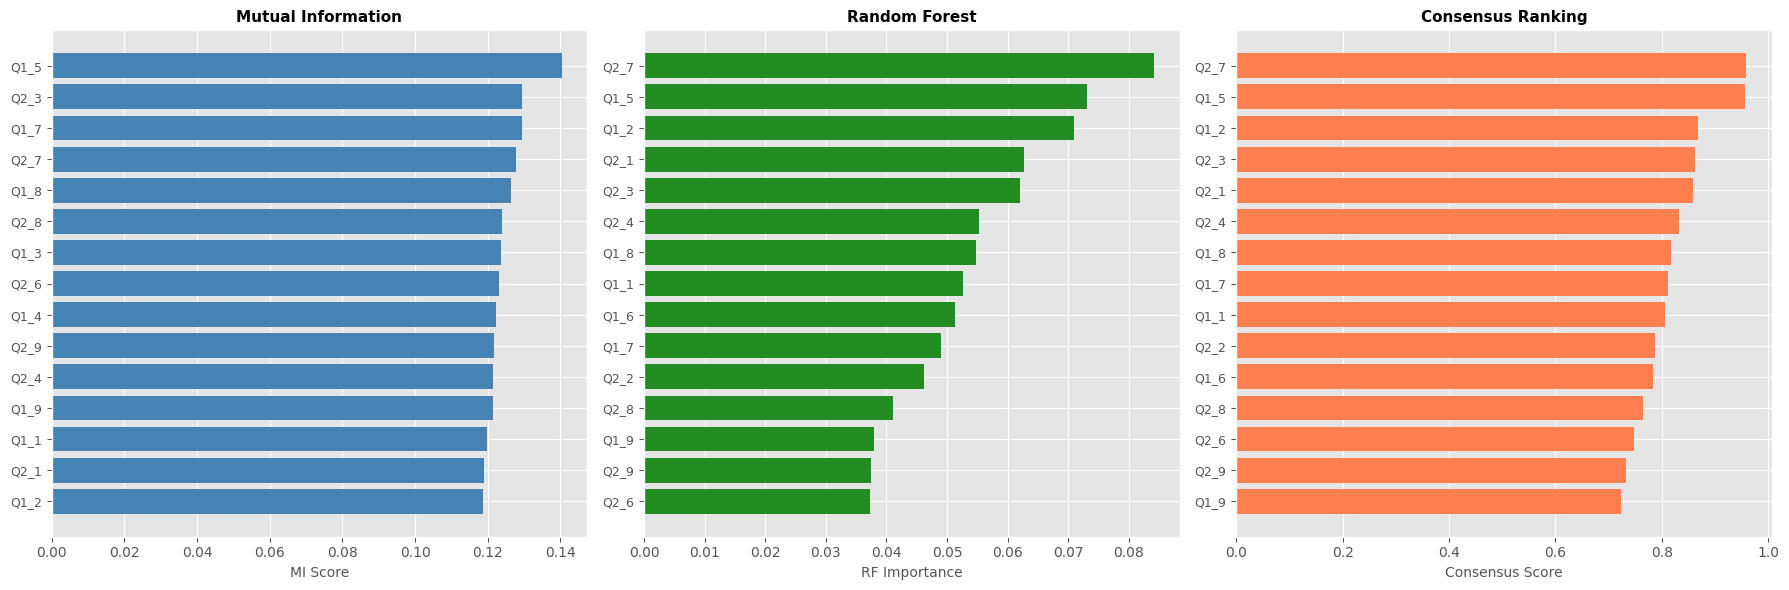

✓ Visualization saved: New_adhd_data_feature_importance.png

 Ready for model training!


In [4]:
# ====================================================================================
# DATA PREPARATION AND GLOBAL SPLIT  +++++++++++++++++++++++++++++++++++++++++++++++++
# ====================================================================================
print("=" * 80)
print("DATA PREPARATION: EVIDENCE-BASED FEATURE SELECTION")
print("=" * 80)

# ====================================================================================
# STEP 1: LOAD DATASET
# ====================================================================================
df = pd.read_csv(INPUT_FILE_PATH)
print(f"✓ Dataset loaded: {df.shape[0]} samples, {df.shape[1]} features\n")

# ====================================================================================
# STEP 2: TARGET VARIABLE DEFINITION
# ====================================================================================
if 'Diagnosis_Class' in df.columns:
    print(" Original Diagnosis_Class Distribution:")
    print(df['Diagnosis_Class'].value_counts().sort_index())
    
    target_col = 'ADHD_TARGET'
    df['ADHD_TARGET'] = df['Diagnosis_Class'].apply(lambda x: 0 if x == 0 else 1)
    df.drop(columns=['Diagnosis_Class'], inplace=True)
    
    print(f"\n✓ Binary target created: ADHD_TARGET")
    print(f"  Class 0 (No ADHD): {(df['ADHD_TARGET']==0).sum()}")
    print(f"  Class 1 (ADHD):    {(df['ADHD_TARGET']==1).sum()}")
    print(f"  Imbalance ratio:   {(df['ADHD_TARGET']==1).sum() / (df['ADHD_TARGET']==0).sum():.2f}\n")

# ====================================================================================
# STEP 3: REMOVE REDUNDANT FEATURES
# ====================================================================================
# Drop Difficulty_Organizing_Tasks (overlaps with Q1_5, correlation=0.55)
if 'Difficulty_Organizing_Tasks' in df.columns:
    print("  Dropping 'Difficulty_Organizing_Tasks' (redundant with Q1_5)")
    df.drop(columns=['Difficulty_Organizing_Tasks'], inplace=True)
    print("✓ Redundant feature removed\n")

# ====================================================================================
# STEP 4: ORDINAL ENCODING
# ====================================================================================
ordinal_mapping = {'Kindergarten': 0, 'Primary': 1, 'Middle': 2}
if 'Educational_Level' in df.columns and df['Educational_Level'].dtype == 'object':
    df['Educational_Level'] = df['Educational_Level'].map(ordinal_mapping)
    print("✓ Educational_Level encoded ordinally\n")

# ====================================================================================
# STEP 5: BINARY COLUMNS CORRECTION (1-2 → 0-1)
# ====================================================================================
for col in BINARY_COLS:
    if col in df.columns and set(df[col].unique()).issubset({1, 2}):
        df[col] = df[col] - 1
        print(f"✓ {col} corrected: [1,2] → [0,1]\n")

# ====================================================================================
# STEP 6: CATEGORICAL ENCODING
# ====================================================================================
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
if target_col in categorical_cols:
    categorical_cols.remove(target_col)

if categorical_cols:
    print(f" One-hot encoding: {categorical_cols}")
    df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
    print(f"✓ Encoding completed\n")

# ====================================================================================
# STEP 7: MISSING VALUE HANDLING
# ====================================================================================
print(" DATA QUALITY:")
missing_count = df.isnull().sum().sum()
print(f"  Missing values: {missing_count}")
print(f"  Duplicates:     {df.duplicated().sum()}")

if missing_count > 0:
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    if target_col in numeric_cols:
        numeric_cols.remove(target_col)
    
    for col in numeric_cols:
        if df[col].isnull().sum() > 0:
            df[col].fillna(df[col].median(), inplace=True)
    
    print("✓ Missing values imputed with median\n")

print(f"  Final shape: {df.shape}\n")

# ====================================================================================
# STEP 8: TRAIN-TEST SPLIT
# ====================================================================================
X_full = df.drop(columns=[target_col])
y = df[target_col]

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

X_train_full, X_test_full, y_train, y_test = train_test_split(
    X_full, y_encoded, test_size=0.30, random_state=42, stratify=y_encoded
)
# Additional validation split from train (80% train, 10% val, 10% test → 70/20/10 effective)

print(" TRAIN-TEST SPLIT:")
print(f"  Train: {X_train_full.shape[0]} samples ({X_train_full.shape[0]/len(df)*100:.1f}%)")
print(f"  Test:  {X_test_full.shape[0]} samples ({X_test_full.shape[0]/len(df)*100:.1f}%)")
print(f"  Features: {X_train_full.shape[1]}")
print(f"  Train class: {dict(zip(*np.unique(y_train, return_counts=True)))}")
print(f"  Test class:  {dict(zip(*np.unique(y_test, return_counts=True)))}\n")

# ====================================================================================
# STEP 9: FEATURE SCALING
# ====================================================================================
scaler = StandardScaler()
X_train_scaled_full = scaler.fit_transform(X_train_full)
X_test_scaled_full = scaler.transform(X_test_full)

print("✓ Feature scaling completed (StandardScaler)\n")

# ====================================================================================
# STEP 10: FEATURE SELECTION - 3 METHODS
# ====================================================================================
print("=" * 80)
print("FEATURE IMPORTANCE ANALYSIS")
print("=" * 80)

# Method 1: Mutual Information
from sklearn.feature_selection import mutual_info_classif
mi_scores = mutual_info_classif(X_train_scaled_full, y_train, random_state=42)
mi_importance = pd.DataFrame({
    'Feature': X_full.columns,
    'MI_Score': mi_scores
}).sort_values('MI_Score', ascending=False)

print("\n TOP 15 FEATURES (Mutual Information):")
print(mi_importance.head(15).to_string(index=False))

# Method 2: Random Forest
from sklearn.ensemble import RandomForestClassifier
rf_selector = RandomForestClassifier(
    n_estimators=100, random_state=42, max_depth=10, class_weight='balanced'
)
rf_selector.fit(X_train_scaled_full, y_train)

rf_importance = pd.DataFrame({
    'Feature': X_full.columns,
    'RF_Importance': rf_selector.feature_importances_
}).sort_values('RF_Importance', ascending=False)

print("\n TOP 15 FEATURES (Random Forest):")
print(rf_importance.head(15).to_string(index=False))

# Method 3: F-statistic
from sklearn.feature_selection import SelectKBest, f_classif
selector_kbest = SelectKBest(f_classif, k='all')
selector_kbest.fit(X_train_scaled_full, y_train)

f_importance = pd.DataFrame({
    'Feature': X_full.columns,
    'F_Score': selector_kbest.scores_
}).sort_values('F_Score', ascending=False)

print("\n TOP 15 FEATURES (F-statistic):")
print(f_importance.head(15).to_string(index=False))

# ====================================================================================
# STEP 11: CONSENSUS RANKING
# ====================================================================================
# Normalize scores
mi_importance['MI_Normalized'] = (mi_importance['MI_Score'] - mi_importance['MI_Score'].min()) / \
                                  (mi_importance['MI_Score'].max() - mi_importance['MI_Score'].min())
rf_importance['RF_Normalized'] = (rf_importance['RF_Importance'] - rf_importance['RF_Importance'].min()) / \
                                  (rf_importance['RF_Importance'].max() - rf_importance['RF_Importance'].min())
f_importance['F_Normalized'] = (f_importance['F_Score'] - f_importance['F_Score'].min()) / \
                                (f_importance['F_Score'].max() - f_importance['F_Score'].min())

# Merge and average
consensus = mi_importance[['Feature', 'MI_Normalized']].merge(
    rf_importance[['Feature', 'RF_Normalized']], on='Feature'
).merge(
    f_importance[['Feature', 'F_Normalized']], on='Feature'
)

consensus['Consensus_Score'] = (consensus['MI_Normalized'] + 
                                consensus['RF_Normalized'] + 
                                consensus['F_Normalized']) / 3
consensus = consensus.sort_values('Consensus_Score', ascending=False)

print("\n" + "=" * 80)
print(" CONSENSUS FEATURE RANKING")
print("=" * 80)
print(consensus.head(20).to_string(index=False))

# Save ranking
consensus.to_csv(OUTPUT_FILE_PATH.replace('.csv', '_feature_ranking.csv'), index=False)
print(f"\n✓ Full ranking saved: {OUTPUT_FILE_PATH.replace('.csv', '_feature_ranking.csv')}")

# ====================================================================================
# STEP 12: SELECT TOP 15 FEATURES
# ====================================================================================
print("\n" + "=" * 80)
print("SELECTED FEATURES (TOP 15)")
print("=" * 80)

SELECTED_FEATURES = consensus.head(15)['Feature'].tolist()

print(f"\nSelected features:")
for i, feat in enumerate(SELECTED_FEATURES, 1):
    score = consensus[consensus['Feature']==feat]['Consensus_Score'].values[0]
    print(f"  {i:2d}. {feat:40s} (Score: {score:.4f})")

# ====================================================================================
# STEP 13: FINAL DATA PREPARATION
# ====================================================================================
X_train_selected = X_train_full[SELECTED_FEATURES]
X_test_selected = X_test_full[SELECTED_FEATURES]

scaler_final = StandardScaler()
X_train = scaler_final.fit_transform(X_train_selected)
X_test = scaler_final.transform(X_test_selected)

# Deep Learning reshape
X_train_dl = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test_dl = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# ====================================================================================
# FINAL SUMMARY
# ====================================================================================
print("\n" + "=" * 80)
print(" DATA PREPARATION COMPLETED")
print("=" * 80)
print(f"  Original features:  {X_full.shape[1]}")
print(f"  Selected features:  {len(SELECTED_FEATURES)}")
print(f"  Reduction:          {(1 - len(SELECTED_FEATURES)/X_full.shape[1])*100:.1f}%")
print(f"  Training samples:   {X_train.shape[0]}")
print(f"  Test samples:       {X_test.shape[0]}")
print(f"  DL shape (train):   {X_train_dl.shape}")
print(f"  DL shape (test):    {X_test_dl.shape}")
print("=" * 80 + "\n")

# ====================================================================================
# VISUALIZATION
# ====================================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Plot 1: Mutual Information
top_mi = mi_importance.head(15)
axes[0].barh(range(len(top_mi)), top_mi['MI_Score'], color='steelblue')
axes[0].set_yticks(range(len(top_mi)))
axes[0].set_yticklabels(top_mi['Feature'], fontsize=9)
axes[0].set_xlabel('MI Score', fontsize=10)
axes[0].set_title('Mutual Information', fontsize=11, fontweight='bold')
axes[0].invert_yaxis()

# Plot 2: Random Forest
top_rf = rf_importance.head(15)
axes[1].barh(range(len(top_rf)), top_rf['RF_Importance'], color='forestgreen')
axes[1].set_yticks(range(len(top_rf)))
axes[1].set_yticklabels(top_rf['Feature'], fontsize=9)
axes[1].set_xlabel('RF Importance', fontsize=10)
axes[1].set_title('Random Forest', fontsize=11, fontweight='bold')
axes[1].invert_yaxis()

# Plot 3: Consensus
top_consensus = consensus.head(15)
axes[2].barh(range(len(top_consensus)), top_consensus['Consensus_Score'], color='coral')
axes[2].set_yticks(range(len(top_consensus)))
axes[2].set_yticklabels(top_consensus['Feature'], fontsize=9)
axes[2].set_xlabel('Consensus Score', fontsize=10)
axes[2].set_title('Consensus Ranking', fontsize=11, fontweight='bold')
axes[2].invert_yaxis()

plt.tight_layout()
plt.savefig(OUTPUT_FILE_PATH.replace('.csv', '_feature_importance.png'), dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Visualization saved: {OUTPUT_FILE_PATH.replace('.csv', '_feature_importance.png')}\n")
print(" Ready for model training!")


VISUALIZING TOP 15 SELECTED FEATURES (FEATURE SELECTION RESULTS)
✓ Loaded 15 features from consensus ranking
  Top feature: Q2_7 (Score: 0.9588)


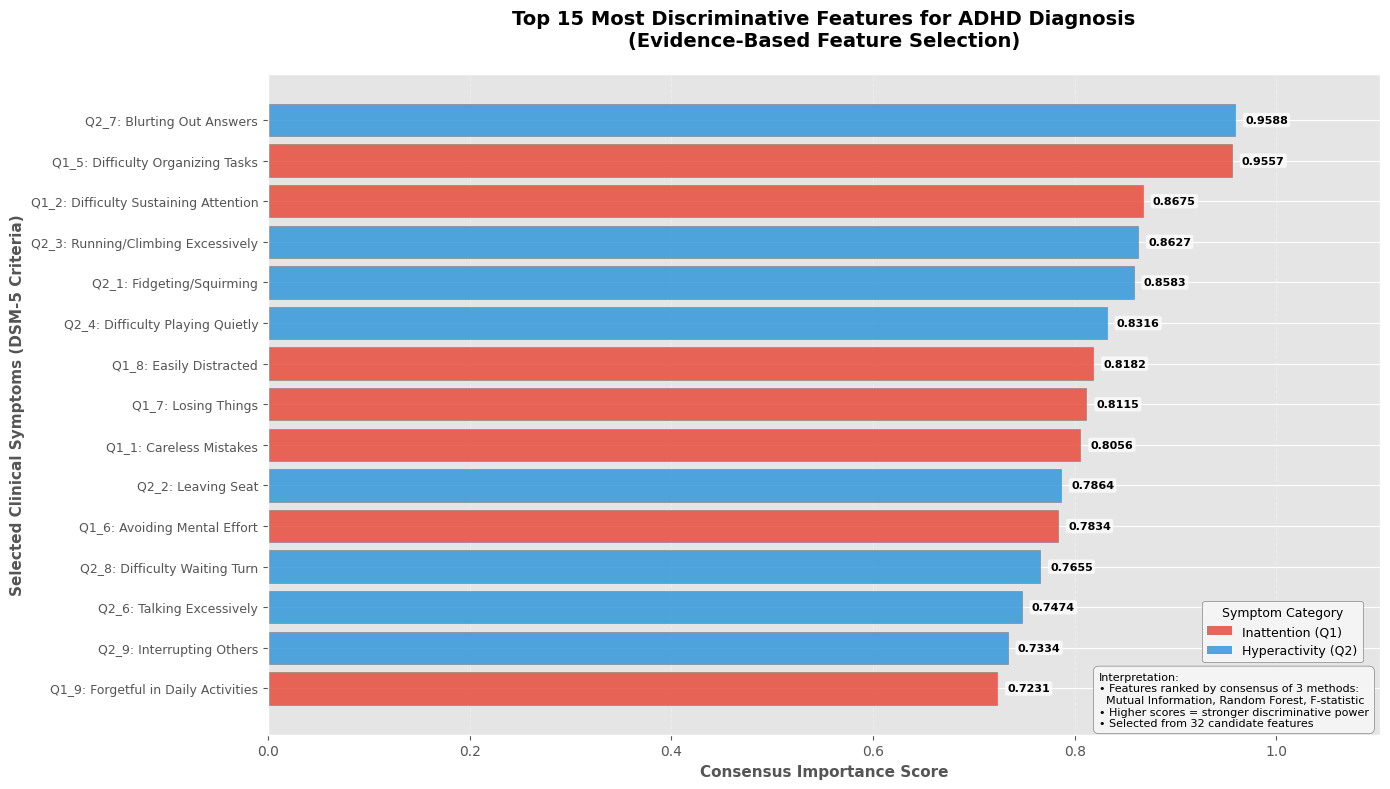


✓ Visualization saved: Top_15_Selected_Features.png

 TOP 15 FEATURE RANKING TABLE

 Rank Feature Code      DSM-5 Clinical Description  Importance Score           Category
    1         Q2_7            Blurting Out Answers          0.958828 Hyperactivity (Q2)
    2         Q1_5     Difficulty Organizing Tasks          0.955740   Inattention (Q1)
    3         Q1_2 Difficulty Sustaining Attention          0.867522   Inattention (Q1)
    4         Q2_3    Running/Climbing Excessively          0.862665 Hyperactivity (Q2)
    5         Q2_1             Fidgeting/Squirming          0.858291 Hyperactivity (Q2)
    6         Q2_4      Difficulty Playing Quietly          0.831568 Hyperactivity (Q2)
    7         Q1_8               Easily Distracted          0.818179   Inattention (Q1)
    8         Q1_7                   Losing Things          0.811489   Inattention (Q1)
    9         Q1_1               Careless Mistakes          0.805628   Inattention (Q1)
   10         Q2_2                 

In [5]:
# ====================================================================================
# CELL 4: TOP 15 SELECTED FEATURES VISUALIZATION & REPORT TABLE ++++++++++++++++++++++
# ====================================================================================

print("\n" + "=" * 80)
print("VISUALIZING TOP 15 SELECTED FEATURES (FEATURE SELECTION RESULTS)")
print("=" * 80)

# ====================================================================================
# 1. DYNAMICALLY GET SELECTED FEATURES FROM CELL 3
# ====================================================================================
if 'consensus' not in globals() or 'SELECTED_FEATURES' not in globals():
    print(" ERROR: 'consensus' DataFrame or 'SELECTED_FEATURES' not found!")
    print("   Please run Cell 3 (Data Preparation) first.")
else:
    # Extract top 15 features with their consensus scores
    feat_df = consensus.head(15)[['Feature', 'Consensus_Score']].copy()
    feat_df.columns = ['Feature', 'Score']
    
    print(f"✓ Loaded {len(feat_df)} features from consensus ranking")
    print(f"  Top feature: {feat_df.iloc[0]['Feature']} (Score: {feat_df.iloc[0]['Score']:.4f})")
    
    # ====================================================================================
    # 2. DSM-5 SYMPTOM LABELS
    # ====================================================================================
    dsm5_labels = {
        # INATTENTION SYMPTOMS (Q1)
        'Q1_1': 'Careless Mistakes',
        'Q1_2': 'Difficulty Sustaining Attention',
        'Q1_3': 'Not Listening',
        'Q1_4': 'Not Following Instructions',
        'Q1_5': 'Difficulty Organizing Tasks',
        'Q1_6': 'Avoiding Mental Effort',
        'Q1_7': 'Losing Things',
        'Q1_8': 'Easily Distracted',
        'Q1_9': 'Forgetful in Daily Activities',
        
        # HYPERACTIVITY/IMPULSIVITY SYMPTOMS (Q2)
        'Q2_1': 'Fidgeting/Squirming',
        'Q2_2': 'Leaving Seat',
        'Q2_3': 'Running/Climbing Excessively',
        'Q2_4': 'Difficulty Playing Quietly',
        'Q2_5': 'Always "On the Go"',
        'Q2_6': 'Talking Excessively',
        'Q2_7': 'Blurting Out Answers',
        'Q2_8': 'Difficulty Waiting Turn',
        'Q2_9': 'Interrupting Others',
        
        # OTHER FEATURES (if selected)
        'Difficulty_Organizing_Tasks': 'Task Organization Difficulty',
        'Focus_Score_Video': 'Video Focus Score',
        'Learning_Difficulties': 'Learning Difficulties',
        'Anxiety_Depression_Levels': 'Anxiety/Depression Level',
        'Sleep_Hours': 'Sleep Duration',
        'Daily_Activity_Hours': 'Physical Activity',
        'Daily_Phone_Usage_Hours': 'Screen Time',
        'Age': 'Age',
        'Gender': 'Gender',
        'Educational_Level': 'Educational Level',
        'Family_History_Yes': 'Family History of ADHD'
    }
    
    # ====================================================================================
    # 3. DATA PROCESSING FOR VISUALIZATION
    # ====================================================================================
    # Add descriptions
    feat_df['Description'] = feat_df['Feature'].map(dsm5_labels)
    
    # Handle features without DSM-5 labels
    feat_df['Description'] = feat_df['Description'].fillna(feat_df['Feature'])
    
    # Create combined label
    feat_df['Label'] = feat_df['Feature'] + ": " + feat_df['Description']
    
    # Categorize features
    def categorize_feature(feat):
        if feat.startswith('Q1_'):
            return 'Inattention (Q1)'
        elif feat.startswith('Q2_'):
            return 'Hyperactivity (Q2)'
        else:
            return 'Other Clinical'
    
    feat_df['Category_Code'] = feat_df['Feature'].apply(categorize_feature)
    
    # Sort for plotting (ascending for horizontal bar - highest at top when plotted)
    feat_df = feat_df.sort_values('Score', ascending=True)
    
    # ====================================================================================
    # 4. VISUALIZATION - HORIZONTAL BAR CHART
    # ====================================================================================

    fig, ax = plt.subplots(figsize=(14, 8))
    
    # Color mapping
    color_map = {
        'Inattention (Q1)': '#e74c3c',       # Red
        'Hyperactivity (Q2)': '#3498db',     # Blue
        'Other Clinical': '#2ecc71'          # Green
    }
    colors = feat_df['Category_Code'].map(color_map)
    
    # Create bars
    bars = ax.barh(feat_df['Label'], feat_df['Score'], color=colors, alpha=0.85, edgecolor='gray', linewidth=0.5)
    
    # Title and labels
    ax.set_title('Top 15 Most Discriminative Features for ADHD Diagnosis\n(Evidence-Based Feature Selection)', 
                 fontsize=14, fontweight='bold', pad=20)
    ax.set_xlabel('Consensus Importance Score', fontsize=11, fontweight='bold')
    ax.set_ylabel('Selected Clinical Symptoms (DSM-5 Criteria)', fontsize=11, fontweight='bold')
    ax.tick_params(axis='y', labelsize=9)
    ax.grid(axis='x', linestyle='--', alpha=0.3)
    ax.set_xlim(0, max(feat_df['Score']) * 1.15)
    
    # Annotate bars with scores
    for i, (idx, row) in enumerate(feat_df.iterrows()):
        ax.text(row['Score'] + 0.01, i, f"{row['Score']:.4f}", 
                va='center', fontsize=8, fontweight='bold', color='black',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7, edgecolor='none'))
    
    # Legend
    from matplotlib.patches import Patch
    unique_categories = feat_df['Category_Code'].unique()
    legend_elements = [Patch(facecolor=color_map[cat], label=cat, alpha=0.85) 
                      for cat in unique_categories if cat in color_map]
    
    ax.legend(handles=legend_elements, loc='lower right', bbox_to_anchor=(0.99, 0.10),
           fontsize=9, framealpha=0.95, facecolor='#f5f5f5', edgecolor='gray',
           title='Symptom Category', title_fontsize=9)
 
    # Interpretation box
    interpretation_text = (
        "Interpretation:\n"
        "• Features ranked by consensus of 3 methods:\n"
        "  Mutual Information, Random Forest, F-statistic\n"
        "• Higher scores = stronger discriminative power\n"
        "• Selected from 32 candidate features"
    )
    ax.text(0.99, 0.01, interpretation_text, transform=ax.transAxes, fontsize=8,
        verticalalignment='bottom', horizontalalignment='right', multialignment='left',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#f5f5f5', edgecolor='gray', alpha=0.95))

    plt.tight_layout()
    plt.savefig('Top_15_Selected_Features.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("\n✓ Visualization saved: Top_15_Selected_Features.png")
    
    # ====================================================================================
    # 5. REPORT TABLE GENERATION
    # ====================================================================================
    print("\n" + "=" * 80)
    print(" TOP 15 FEATURE RANKING TABLE")
    print("=" * 80)
    
    # Prepare table (highest score first)
    table_df = feat_df.sort_values('Score', ascending=False).copy()
    
    # Add rank
    table_df['Rank'] = range(1, len(table_df) + 1)
    
    # Format category for table
    table_df['Category_Formatted'] = table_df['Category_Code']
    
    # Select columns for final table
    final_table = table_df[['Rank', 'Feature', 'Description', 'Score', 'Category_Formatted']].copy()
    final_table.columns = [
        'Rank', 
        'Feature Code', 
        'DSM-5 Clinical Description', 
        'Importance Score', 
        'Category'
    ]
    
    # Display table
    print("\n" + final_table.to_string(index=False))
    
    # ====================================================================================
    # 6. SUMMARY STATISTICS
    # ====================================================================================
    print("\n" + "=" * 80)
    print(" FEATURE SELECTION SUMMARY")
    print("=" * 80)
    
    # Count by category
    category_counts = feat_df['Category_Code'].value_counts()
    print("\n🔹 Distribution by Category:")
    for cat, count in category_counts.items():
        pct = (count / len(feat_df)) * 100
        print(f"   {cat:25s}: {count:2d} features ({pct:5.1f}%)")
    
    # Score statistics
    print(f"\n Score Statistics:")
    print(f"   Highest score: {feat_df['Score'].max():.4f} ({feat_df[feat_df['Score'] == feat_df['Score'].max()]['Feature'].values[0]})")
    print(f"   Lowest score:  {feat_df['Score'].min():.4f} ({feat_df[feat_df['Score'] == feat_df['Score'].min()]['Feature'].values[0]})")
    print(f"   Mean score:    {feat_df['Score'].mean():.4f}")
    print(f"   Median score:  {feat_df['Score'].median():.4f}")
    
    # Feature reduction info
    original_features = len(consensus)
    selected_features = len(feat_df)
    reduction_pct = (1 - selected_features/original_features) * 100
    
    print(f"\n🔹 Dimensionality Reduction:")
    print(f"   Original features:  {original_features}")
    print(f"   Selected features:  {selected_features}")
    print(f"   Reduction:          {reduction_pct:.1f}%")
    
    print("\n" + "=" * 80)
    print(" Feature visualization and reporting completed!")
    print("=" * 80)


LOGISTIC REGRESSION (LR) - HYPERPARAMETER TUNING FOR ADHD DIAGNOSIS
 Dataset Statistics:
    Train samples: 4550
    Test samples:  1950
    Feature count: 15
    Target Balance (Train): [1102 3448] (0: No ADHD, 1: ADHD)

⏳ Starting 5-Fold Grid Search (Logistic Regression)...
Fitting 5 folds for each of 10 candidates, totalling 50 fits

✓ Grid Search completed in 3.4199 sec
✓ Best PR-AUC (CV): 0.9888
✓ Best Hyperparameters: {'C': 0.1, 'max_iter': 1000, 'penalty': 'l2', 'solver': 'lbfgs'}

 Optimizing decision threshold using CV predictions (MCC)...

  Computing real 5-fold MCC scores for statistical tests...
  fold_scores['LR'] MCC = [0.8641, 0.8837, 0.8944, 0.8882, 0.8611]
  Mean MCC: 0.8783 ± 0.0133
✓ Optimal Threshold (CV-based): 0.632
✓ Max MCC (CV): 0.8865

TRAINING FINAL LOGISTIC REGRESSION MODEL

 Training final LR model on full training set...
✓ Final model training completed in 13.163 ms

 Measuring realistic inference latency...

 Evaluating on test set...

LOGISTIC REGRESSI

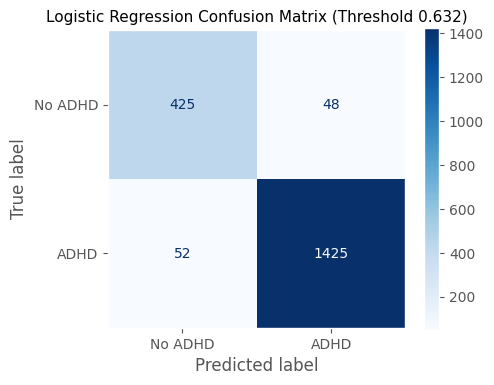


  Bootstrap 95% CI (1000 iterations):
    MCC         : 0.8615 [0.8319 - 0.8860]
    KAPPA       : 0.8604 [0.8335 - 0.8855]
    ROC_AUC     : 0.9532 [0.9392 - 0.9658]
    F1          : 0.9660 [0.9598 - 0.9724]
    ACCURACY    : 0.9484 [0.9385 - 0.9585]
  ✅ LR saved to JSON + CSV
  ✅ LR pred_proba saved.
  ✅ LR confusion matrix saved.

 Timing and metrics stored successfully.
    Grid Search:    3.4199 sec
    Training:       13.163 ms
    Inference:      79.728 ms
    Latency:        0.040886 ms/sample
    Total Time:     3.5128 sec


In [7]:
# ====================================================================================
# LOGISTIC REGRESSION (LR) - ACADEMIC PIPELINE WITH 5-FOLD CV (ADHD DIAGNOSIS)   +++++
# ====================================================================================

print("\n" + "=" * 80)
print("LOGISTIC REGRESSION (LR) - HYPERPARAMETER TUNING FOR ADHD DIAGNOSIS")
print("=" * 80)

# ================================================================================
# DATA ASSIGNMENT (FROM GLOBAL DATA PREP CELL)
# ================================================================================
print(f" Dataset Statistics:")
print(f"    Train samples: {X_train.shape[0]}")
print(f"    Test samples:  {X_test.shape[0]}")
print(f"    Feature count: {X_train.shape[1]}")
print(f"    Target Balance (Train): {np.bincount(y_train.astype(int))} (0: No ADHD, 1: ADHD)")

# ================================================================================
# HYPERPARAMETER TUNING (5-FOLD CV WITH PR-AUC)
# ================================================================================
lr_param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "penalty": ["l2"],
    "solver": ["liblinear", "lbfgs"],
    "max_iter": [1000]
}

lr_base = LogisticRegression(random_state=42)

lr_clf = GridSearchCV(
    lr_base,
    param_grid=lr_param_grid,
    scoring="average_precision",   # PR-AUC for imbalanced medical data
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    verbose=1,
    n_jobs=-1,
    refit=False  # Important: We train manually below to measure time accurately
)

print("\n⏳ Starting 5-Fold Grid Search (Logistic Regression)...")
timer.start("lr_grid")
lr_clf.fit(X_train, y_train)
lr_grid_time = timer.stop("lr_grid")

print(f"\n✓ Grid Search completed in {format_time(lr_grid_time)}")
print(f"✓ Best PR-AUC (CV): {lr_clf.best_score_:.4f}")
print(f"✓ Best Hyperparameters: {lr_clf.best_params_}")

# ================================================================================
# THRESHOLD OPTIMIZATION (CV-BASED MCC)
# ================================================================================
print("\n Optimizing decision threshold using CV predictions (MCC)...")

# Temporary model for threshold optimization using best params
temp_lr = LogisticRegression(
    **lr_clf.best_params_,
    random_state=42,
    n_jobs=-1
)
temp_lr.fit(X_train, y_train)


# ============================================================
# STORE REAL FOLD MCC SCORES FOR STATISTICAL TESTS
# Uses cross_val_predict with best params model
# ============================================================
print("\n  Computing real 5-fold MCC scores for statistical tests...")
_skf_fs = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
_fold_mcc_list = []
for _train_idx, _val_idx in _skf_fs.split(X_train, y_train):
    _X_tr, _X_val = X_train[_train_idx], X_train[_val_idx]
    _y_tr, _y_val = y_train[_train_idx], y_train[_val_idx]
    temp_lr.fit(_X_tr, _y_tr)
    _val_preds = (temp_lr.predict_proba(_X_val)[:, 1] >= 0.5).astype(int)
    _fold_mcc_list.append(matthews_corrcoef(_y_val, _val_preds))
_folds_data = {'MCC': _fold_mcc_list}
print(f"  fold_scores['LR'] MCC = {[round(x,4) for x in _fold_mcc_list]}")
print(f"  Mean MCC: {np.mean(_fold_mcc_list):.4f} ± {np.std(_fold_mcc_list):.4f}")

# Global utility function usage
optimal_threshold, max_mcc_cv = optimize_threshold_cv(
    temp_lr,
    X_train,
    y_train,
    cv=5
)

print(f"✓ Optimal Threshold (CV-based): {optimal_threshold:.3f}")
print(f"✓ Max MCC (CV): {max_mcc_cv:.4f}")

# ================================================================================
# FINAL MODEL TRAINING (FULL TRAIN SET WITH TRUE TIMING)
# ================================================================================
print("\n" + "=" * 80)
print("TRAINING FINAL LOGISTIC REGRESSION MODEL")
print("=" * 80)

best_lr = LogisticRegression(
    **lr_clf.best_params_,
    random_state=42,
    n_jobs=-1
)

print("\n Training final LR model on full training set...")
timer.start("lr_train")
best_lr.fit(X_train, y_train)
lr_training_time = timer.stop("lr_train")

print(f"✓ Final model training completed in {format_time(lr_training_time)}")

# ================================================================================
# INFERENCE LATENCY MEASUREMENT
# ================================================================================
print("\n Measuring realistic inference latency...")

# Global utility function usage (Fix applied for 2D array)
latency_stats = measure_inference_latency(best_lr, X_test)
inference_time_total = latency_stats["total_sec"]
latency_ms = latency_stats["mean_ms"]

# ================================================================================
# TEST SET EVALUATION
# ================================================================================
print("\n Evaluating on test set...")

lr_pred_proba = best_lr.predict_proba(X_test)[:, 1]
best_lr_predict = (lr_pred_proba >= optimal_threshold).astype(int)

# Global utility function usage
metrics = compute_metrics(
    y_test,
    best_lr_predict,
    lr_pred_proba
)

model_size_mb = get_model_size_mb(best_lr)

# ================================================================================
# RESULTS OUTPUT
# ================================================================================
print("\n" + "=" * 80)
print("LOGISTIC REGRESSION - FINAL RESULTS")
print("=" * 80)

print_metrics(metrics, optimal_threshold)

print(f"\n✓ Model Size:    {model_size_mb:.4f} MB")

print("\n Classification Report:")
print(classification_report(
    y_test,
    best_lr_predict,
    target_names=["No ADHD", "ADHD"]
))

# ================================================================================
# CONFUSION MATRIX (MODULAR GLOBAL FUNCTION)
# ================================================================================
plot_confusion_matrix(
    cm=metrics["Confusion_Matrix"],
    model_name="Logistic Regression",
    threshold=optimal_threshold,
    cmap='Blues'  # Standard color for Classical Models
)


# ============================================================
# BOOTSTRAP 95% CONFIDENCE INTERVALS
# ============================================================
compute_all_bootstrap_ci(
    np.array(y_test),
    np.array(best_lr_predict).flatten(),
    np.array(lr_pred_proba).flatten(),
    model_name='LR',
    n_bootstrap=1000
)

# ================================================================================
# RESULTS ARCHIVING
# ================================================================================
total_time = lr_grid_time + lr_training_time + inference_time_total
fpr_score = 1 - metrics["Specificity"]


metrics = {
    "Accuracy": metrics["Accuracy"],
    "Precision": metrics["Precision"],
    "Recall": metrics["Recall"],
    "F1_Score": metrics["F1_Score"],
    "MCC": metrics["MCC"],
    "Kappa": metrics["Kappa"],
    "ROC_AUC": metrics["ROC_AUC"],
    "PR_AUC": metrics["PR_AUC"],
    "Specificity": metrics["Specificity"],
    "FPR": fpr_score,
    "Model_Size_MB": model_size_mb,
    "Category": "Classical"
}

# Train accuracy
_train_pred = best_lr.predict(X_train)  # ← model adını değiştir
metrics['Train_Accuracy'] = float(accuracy_score(y_train, _train_pred))

_tn, _fp, _fn, _tp = confusion_matrix(y_test, best_lr_predict).ravel()
metrics['TP'] = int(_tp)
metrics['TN'] = int(_tn)
metrics['FP'] = int(_fp)
metrics['FN'] = int(_fn)

timing = {
    "CV_Time": lr_grid_time,
    "Training_Time": lr_training_time,
    "Inference_Time_Sec": inference_time_total,
    "Latency_ms": latency_ms,
    "mean_ms" : latency_stats.get("mean_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p50_ms"  : latency_stats.get("p50_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p95_ms"  : latency_stats.get("p95_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p99_ms"  : latency_stats.get("p99_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "Total_Time": total_time
}

# Save to JSON + CSV
save_model_result("LR", metrics, timing, folds=_folds_data)

# === PRED PROBA → JSON ===
_proba_path = Path('adhd_results/pred_probas.json')
_all_probas = json.load(open(_proba_path)) if _proba_path.exists() else {}
_all_probas['LR'] = lr_pred_proba.tolist()   # ← her model için değiştir
with open(_proba_path, 'w') as f:
    json.dump(_all_probas, f)
print("  ✅ LR pred_proba saved.")

# === CONFUSION MATRIX → JSON ===
_cm_path = Path('adhd_results/confusion_matrices.json')
_all_cms = json.load(open(_cm_path)) if _cm_path.exists() else {}
_all_cms['LR'] = confusion_matrix(y_test, best_lr_predict).tolist()
with open(_cm_path, 'w') as f:
    json.dump(_all_cms, f, indent=2)
print("  ✅ LR confusion matrix saved.")

print("\n Timing and metrics stored successfully.")
print(f"    Grid Search:    {format_time(lr_grid_time)}")
print(f"    Training:       {format_time(lr_training_time)}")
print(f"    Inference:      {format_time(inference_time_total)}")
print(f"    Latency:        {latency_ms:.6f} ms/sample")
print(f"    Total Time:     {format_time(total_time)}")
print("=" * 80)



SVM (SUPPORT VECTOR MACHINE) - HYPERPARAMETER TUNING FOR ADHD DIAGNOSIS
 Dataset Statistics:
    Train samples: 4550
    Test samples:  1950
    Feature count: 15
    Target Balance (Train): [1102 3448] (0: No ADHD, 1: ADHD)

 Starting 5-Fold Grid Search (SVM)...
Fitting 5 folds for each of 32 candidates, totalling 160 fits

✓ Grid Search completed in 21.4518 sec
✓ Best PR-AUC (CV): 0.9887
✓ Best Hyperparameters: {'C': 100, 'gamma': 'scale', 'kernel': 'linear'}

 Optimizing decision threshold using CV predictions (MCC)...

  Computing real 5-fold MCC scores for statistical tests...
  fold_scores['SVM'] MCC = [0.8695, 0.8865, 0.8975, 0.8822, 0.8611]
  Mean MCC: 0.8793 ± 0.0128
✓ Optimal Threshold (CV-based): 0.586
✓ Max MCC (CV): 0.8845

TRAINING FINAL SVM MODEL

 Training final SVM model on full training set...
✓ Final model training completed in 9.4881 sec

 Measuring realistic inference latency...

 Evaluating on test set...

SVM - FINAL RESULTS

  Accuracy  (threshold 0.586): 0.947

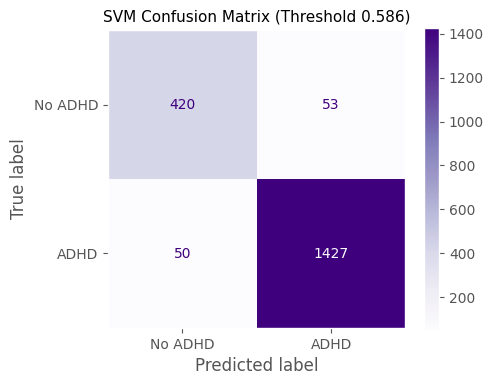


  Bootstrap 95% CI (1000 iterations):
    MCC         : 0.8565 [0.8309 - 0.8831]
    KAPPA       : 0.8562 [0.8291 - 0.8841]
    ROC_AUC     : 0.9538 [0.9386 - 0.9668]
    F1          : 0.9650 [0.9583 - 0.9720]
    ACCURACY    : 0.9473 [0.9374 - 0.9569]
  ✅ SVM saved to JSON + CSV
  ✅ SVM pred_proba saved.
  ✅ SVM confusion matrix saved.

 Timing and metrics stored successfully.
    Grid Search:    21.4518 sec
    Training:       9.4881 sec
    Inference:      107.050 ms
    Latency:        0.054897 ms/sample
    Total Time:     31.0469 sec


In [6]:
# ====================================================================================
# SVM (SUPPORT VECTOR MACHINE) - ACADEMIC PIPELINE WITH 5-FOLD CV (ADHD DIAGNOSIS)  ++
# ====================================================================================

from sklearn.svm import SVC

print("\n" + "=" * 80)
print("SVM (SUPPORT VECTOR MACHINE) - HYPERPARAMETER TUNING FOR ADHD DIAGNOSIS")
print("=" * 80)

# ================================================================================
# DATA ASSIGNMENT (FROM GLOBAL DATA PREP CELL)
# ================================================================================
print(f" Dataset Statistics:")
print(f"    Train samples: {X_train.shape[0]}")
print(f"    Test samples:  {X_test.shape[0]}")
print(f"    Feature count: {X_train.shape[1]}")
# Fix: Ensure y_train is integer for bincount
print(f"    Target Balance (Train): {np.bincount(y_train.astype(int))} (0: No ADHD, 1: ADHD)")

# ================================================================================
# HYPERPARAMETER TUNING (5-FOLD CV WITH PR-AUC)
# ================================================================================
svm_param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": ['scale', 'auto', 0.1, 0.01],
    "kernel": ["rbf", "linear"]
}

svm_base = SVC(
    probability=True, # Required for predict_proba and ROC-AUC
    random_state=42
)

svm_clf = GridSearchCV(
    svm_base,
    param_grid=svm_param_grid,
    scoring="average_precision",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    verbose=1,
    n_jobs=-1,
    refit=False  # Important: We train manually below to measure time accurately
)

print("\n Starting 5-Fold Grid Search (SVM)...")
timer.start("svm_grid")
svm_clf.fit(X_train, y_train)
svm_grid_time = timer.stop("svm_grid")

print(f"\n✓ Grid Search completed in {format_time(svm_grid_time)}")
print(f"✓ Best PR-AUC (CV): {svm_clf.best_score_:.4f}")
print(f"✓ Best Hyperparameters: {svm_clf.best_params_}")

# ================================================================================
# THRESHOLD OPTIMIZATION (CV-BASED MCC)
# ================================================================================
print("\n Optimizing decision threshold using CV predictions (MCC)...")

# Creating a temporary model because refit=False
temp_svm = SVC(**svm_clf.best_params_, probability=True, random_state=42)
temp_svm.fit(X_train, y_train)


# ============================================================
# STORE REAL FOLD MCC SCORES FOR STATISTICAL TESTS
# Uses cross_val_predict with best params model
# ============================================================
print("\n  Computing real 5-fold MCC scores for statistical tests...")
_skf_fs = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
_fold_mcc_list = []
for _train_idx, _val_idx in _skf_fs.split(X_train, y_train):
    _X_tr, _X_val = X_train[_train_idx], X_train[_val_idx]
    _y_tr, _y_val = y_train[_train_idx], y_train[_val_idx]
    temp_svm.fit(_X_tr, _y_tr)
    _val_preds = (temp_svm.predict_proba(_X_val)[:, 1] >= 0.5).astype(int)
    _fold_mcc_list.append(matthews_corrcoef(_y_val, _val_preds))
_folds_data = {'MCC': _fold_mcc_list}
print(f"  fold_scores['SVM'] MCC = {[round(x,4) for x in _fold_mcc_list]}")
print(f"  Mean MCC: {np.mean(_fold_mcc_list):.4f} ± {np.std(_fold_mcc_list):.4f}")

# Global utility function usage
optimal_threshold, max_mcc_cv = optimize_threshold_cv(
    temp_svm,
    X_train, 
    y_train, 
    cv=5
)

print(f"✓ Optimal Threshold (CV-based): {optimal_threshold:.3f}")
print(f"✓ Max MCC (CV): {max_mcc_cv:.4f}")

# ================================================================================
# FINAL MODEL TRAINING (FULL TRAIN SET) - ACCURATE TIMING
# ================================================================================
print("\n" + "=" * 80)
print("TRAINING FINAL SVM MODEL")
print("=" * 80)

# Instantiate NEW model with best parameters
best_svm = SVC(
    **svm_clf.best_params_,
    probability=True,
    random_state=42
)

print("\n Training final SVM model on full training set...")
timer.start("svm_train")
best_svm.fit(X_train, y_train)
svm_training_time = timer.stop("svm_train") # Now measuring actual training time!

print(f"✓ Final model training completed in {format_time(svm_training_time)}")

# ================================================================================
# INFERENCE LATENCY MEASUREMENT
# ================================================================================
print("\n Measuring realistic inference latency...")

latency_stats = measure_inference_latency(best_svm, X_test)
inference_time_total = latency_stats["total_sec"]
latency_ms = latency_stats["mean_ms"]

# ================================================================================
# TEST SET EVALUATION
# ================================================================================
print("\n Evaluating on test set...")

svm_pred_proba = best_svm.predict_proba(X_test)[:, 1]
best_svm_predict = (svm_pred_proba >= optimal_threshold).astype(int)

metrics = compute_metrics(
    y_test,
    best_svm_predict,
    svm_pred_proba
)

model_size_mb = get_model_size_mb(best_svm)

# ================================================================================
# RESULTS OUTPUT
# ================================================================================
print("\n" + "=" * 80)
print("SVM - FINAL RESULTS")
print("=" * 80)

print_metrics(metrics, optimal_threshold)

print(f"\n✓ Model Size:    {model_size_mb:.4f} MB")

print("\n Classification Report:")
print(classification_report(
    y_test, 
    best_svm_predict, 
    target_names=['No ADHD', 'ADHD']
))

# ================================================================================
# CONFUSION MATRIX (USING GLOBAL MODULAR FUNCTION)
# ================================================================================
plot_confusion_matrix(
    cm=metrics["Confusion_Matrix"],
    model_name="SVM",
    threshold=optimal_threshold,
    cmap='Purples'
)


# ============================================================
# BOOTSTRAP 95% CONFIDENCE INTERVALS
# ============================================================
compute_all_bootstrap_ci(
    np.array(y_test),
    np.array(best_svm_predict).flatten(),
    np.array(svm_pred_proba).flatten(),
    model_name='SVM',
    n_bootstrap=1000
)

# ================================================================================
# RESULTS ARCHIVING
# ================================================================================
total_time = svm_grid_time + svm_training_time + inference_time_total
fpr_score = 1 - metrics["Specificity"]


metrics = {
    "Accuracy": metrics["Accuracy"],
    "Precision": metrics["Precision"],
    "Recall": metrics["Recall"],
    "F1_Score": metrics["F1_Score"],
    "MCC": metrics["MCC"],
    "Kappa": metrics["Kappa"],
    "ROC_AUC": metrics["ROC_AUC"],
    "PR_AUC": metrics["PR_AUC"],
    "Specificity": metrics["Specificity"],
    "FPR": fpr_score,
    "Model_Size_MB": model_size_mb,
    "Category": "Classical"
}

# Train accuracy
_train_pred = best_svm.predict(X_train)  # ← model adını değiştir
metrics['Train_Accuracy'] = float(accuracy_score(y_train, _train_pred))

_tn, _fp, _fn, _tp = confusion_matrix(y_test, best_svm_predict).ravel()
metrics['TP'] = int(_tp)
metrics['TN'] = int(_tn)
metrics['FP'] = int(_fp)
metrics['FN'] = int(_fn)

timing = {
    "CV_Time": svm_grid_time,
    "Training_Time": svm_training_time,
    "Inference_Time_Sec": inference_time_total,
    "Latency_ms": latency_ms,
    "mean_ms" : latency_stats.get("mean_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p50_ms"  : latency_stats.get("p50_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p95_ms"  : latency_stats.get("p95_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p99_ms"  : latency_stats.get("p99_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "Total_Time": total_time
}

# Save to JSON + CSV
save_model_result("SVM", metrics, timing, folds=_folds_data)

# === PRED PROBA → JSON ===
_proba_path = Path('adhd_results/pred_probas.json')
_all_probas = json.load(open(_proba_path)) if _proba_path.exists() else {}
_all_probas['SVM'] = svm_pred_proba.tolist() 
with open(_proba_path, 'w') as f:
    json.dump(_all_probas, f)
print("  ✅ SVM pred_proba saved.")

# === CONFUSION MATRIX → JSON ===
_cm_path = Path('adhd_results/confusion_matrices.json')
_all_cms = json.load(open(_cm_path)) if _cm_path.exists() else {}
_all_cms['SVM'] = confusion_matrix(y_test, best_svm_predict).tolist()
with open(_cm_path, 'w') as f:
    json.dump(_all_cms, f, indent=2)
print("  ✅ SVM confusion matrix saved.")

print("\n Timing and metrics stored successfully.")
print(f"    Grid Search:    {format_time(svm_grid_time)}")
print(f"    Training:       {format_time(svm_training_time)}")
print(f"    Inference:      {format_time(inference_time_total)}")
print(f"    Latency:        {latency_ms:.6f} ms/sample")
print(f"    Total Time:     {format_time(total_time)}")
print("=" * 80)



GAUSSIAN NAIVE BAYES - HYPERPARAMETER TUNING FOR ADHD DIAGNOSIS
 Dataset Statistics:
    Train samples: 4550
    Test samples:  1950
    Feature count: 15
    Target Balance (Train): [1102 3448] (0: No ADHD, 1: ADHD)

 Starting 5-Fold Grid Search (Naive Bayes)...
Fitting 5 folds for each of 100 candidates, totalling 500 fits

✓ Grid Search completed in 238.226 ms
✓ Best PR-AUC (CV): 0.9892
✓ Best Hyperparameters: {'var_smoothing': np.float64(0.1)}

 Optimizing decision threshold using CV-based MCC...

  Computing real 5-fold MCC scores for statistical tests...
  fold_scores['Naive Bayes'] MCC = [0.8665, 0.8833, 0.8893, 0.8859, 0.8493]
  Mean MCC: 0.8748 ± 0.0150
✓ Optimal Threshold (CV-based): 0.114
✓ Max MCC (CV): 0.8936

TRAINING FINAL NAIVE BAYES MODEL

 Training final Naive Bayes model on full training set...
✓ Final model training completed in 0.839 ms

 Measuring realistic inference latency...

 Evaluating on test set...

NAIVE BAYES - FINAL RESULTS

  Accuracy  (threshold 0.114

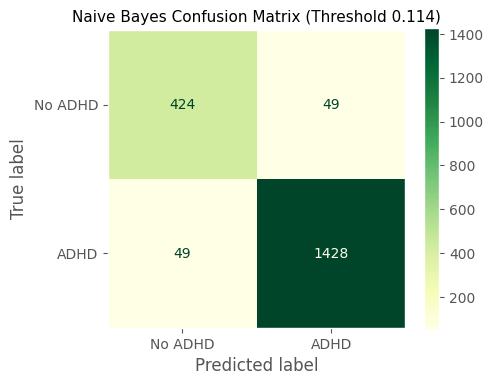


  Bootstrap 95% CI (1000 iterations):
    MCC         : 0.8627 [0.8367 - 0.8893]
    KAPPA       : 0.8632 [0.8364 - 0.8885]
    ROC_AUC     : 0.9532 [0.9391 - 0.9665]
    F1          : 0.9669 [0.9606 - 0.9734]
    ACCURACY    : 0.9497 [0.9400 - 0.9590]
  ✅ Naive Bayes saved to JSON + CSV
  ✅ Naive Bayes pred_proba saved.
  ✅ Naive Bayes confusion matrix saved.

 Timing and metrics stored successfully.
    Grid Search:    238.226 ms
    Training:       0.839 ms
    Inference:      191.234 ms
    Latency:        0.098069 ms/sample
    Total Time:     430.298 ms


In [9]:
# ====================================================================================
# GAUSSIAN NAIVE BAYES (NB) - ACADEMIC PIPELINE WITH 5-FOLD CV (ADHD DIAGNOSIS)  +++++
# ====================================================================================

print("\n" + "=" * 80)
print("GAUSSIAN NAIVE BAYES - HYPERPARAMETER TUNING FOR ADHD DIAGNOSIS")
print("=" * 80)

# ================================================================================
# DATA ASSIGNMENT (FROM GLOBAL DATA PREP CELL)
# ================================================================================
print(f" Dataset Statistics:")
print(f"    Train samples: {X_train.shape[0]}")
print(f"    Test samples:  {X_test.shape[0]}")
print(f"    Feature count: {X_train.shape[1]}")
# Fix: Ensure y_train is integer for bincount safety
print(f"    Target Balance (Train): {np.bincount(y_train.astype(int))} (0: No ADHD, 1: ADHD)")

# ================================================================================
# HYPERPARAMETER TUNING (5-FOLD CV WITH PR-AUC)
# ================================================================================
# var_smoothing controls numerical stability and variance regularization
nb_param_grid = {
    "var_smoothing": np.logspace(0, -9, num=100)
}

nb_base = GaussianNB()

nb_clf = GridSearchCV(
    nb_base,
    param_grid=nb_param_grid,
    scoring="average_precision",  # PR-AUC for imbalanced ADHD data
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    verbose=1,
    n_jobs=-1,
    refit=False  # Important: We train manually below to measure time accurately
)

print("\n Starting 5-Fold Grid Search (Naive Bayes)...")
timer.start("nb_grid")
nb_clf.fit(X_train, y_train)
nb_grid_time = timer.stop("nb_grid")

print(f"\n✓ Grid Search completed in {format_time(nb_grid_time)}")
print(f"✓ Best PR-AUC (CV): {nb_clf.best_score_:.4f}")
print(f"✓ Best Hyperparameters: {nb_clf.best_params_}")

# ================================================================================
# THRESHOLD OPTIMIZATION (CV-BASED MCC)
# ================================================================================
print("\n Optimizing decision threshold using CV-based MCC...")

# Creating a fresh estimator using best params because refit=False
temp_nb = GaussianNB(**nb_clf.best_params_)
temp_nb.fit(X_train, y_train)


# ============================================================
# STORE REAL FOLD MCC SCORES FOR STATISTICAL TESTS
# Uses cross_val_predict with best params model
# ============================================================
print("\n  Computing real 5-fold MCC scores for statistical tests...")
_skf_fs = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
_fold_mcc_list = []
for _train_idx, _val_idx in _skf_fs.split(X_train, y_train):
    _X_tr, _X_val = X_train[_train_idx], X_train[_val_idx]
    _y_tr, _y_val = y_train[_train_idx], y_train[_val_idx]
    temp_nb.fit(_X_tr, _y_tr)
    _val_preds = (temp_nb.predict_proba(_X_val)[:, 1] >= 0.5).astype(int)
    _fold_mcc_list.append(matthews_corrcoef(_y_val, _val_preds))
_folds_data = {'MCC': _fold_mcc_list}
print(f"  fold_scores['Naive Bayes'] MCC = {[round(x,4) for x in _fold_mcc_list]}")
print(f"  Mean MCC: {np.mean(_fold_mcc_list):.4f} ± {np.std(_fold_mcc_list):.4f}")

# Global utility function usage
optimal_threshold, max_mcc_cv = optimize_threshold_cv(
    temp_nb,
    X_train,
    y_train,
    cv=5
)

print(f"✓ Optimal Threshold (CV-based): {optimal_threshold:.3f}")
print(f"✓ Max MCC (CV): {max_mcc_cv:.4f}")

# ================================================================================
# FINAL MODEL TRAINING (FULL TRAIN SET WITH TRUE TIMING)
# ================================================================================
print("\n" + "=" * 80)
print("TRAINING FINAL NAIVE BAYES MODEL")
print("=" * 80)

# Instantiate NEW model with best parameters
best_nb = GaussianNB(**nb_clf.best_params_)

print("\n Training final Naive Bayes model on full training set...")
timer.start("nb_train")
best_nb.fit(X_train, y_train)
nb_training_time = timer.stop("nb_train") # Now measuring actual training time

print(f"✓ Final model training completed in {format_time(nb_training_time)}")

# ================================================================================
# INFERENCE LATENCY MEASUREMENT
# ================================================================================
print("\n Measuring realistic inference latency...")

# Global utility function usage
latency_stats = measure_inference_latency(best_nb, X_test)
inference_time_total = latency_stats["total_sec"]
latency_ms = latency_stats["mean_ms"]

# ================================================================================
# TEST SET EVALUATION
# ================================================================================
print("\n Evaluating on test set...")

nb_pred_proba = best_nb.predict_proba(X_test)[:, 1]
best_nb_predict = (nb_pred_proba >= optimal_threshold).astype(int)

# Global utility function usage
metrics = compute_metrics(
    y_test,
    best_nb_predict,
    nb_pred_proba
)

model_size_mb = get_model_size_mb(best_nb)

# ================================================================================
# RESULTS OUTPUT
# ================================================================================
print("\n" + "=" * 80)
print("NAIVE BAYES - FINAL RESULTS")
print("=" * 80)

print_metrics(metrics, optimal_threshold)

print(f"\n✓ Model Size:    {model_size_mb:.4f} MB")

print("\n Classification Report:")
print(classification_report(
    y_test,
    best_nb_predict,
    target_names=["No ADHD", "ADHD"]
))

# ================================================================================
# CONFUSION MATRIX (MODULAR GLOBAL FUNCTION)
# ================================================================================
plot_confusion_matrix(
    cm=metrics["Confusion_Matrix"],
    model_name="Naive Bayes",
    threshold=optimal_threshold,
    cmap="YlGn" # Yellow-Green color map for Naive Bayes
)


# ============================================================
# BOOTSTRAP 95% CONFIDENCE INTERVALS
# ============================================================
compute_all_bootstrap_ci(
    np.array(y_test),
    np.array(best_nb_predict).flatten(),
    np.array(nb_pred_proba).flatten(),
    model_name='Naive Bayes',
    n_bootstrap=1000
)

# ================================================================================
# RESULTS ARCHIVING
# ================================================================================
total_time = nb_grid_time + nb_training_time + inference_time_total
fpr_score = 1 - metrics["Specificity"]


metrics = {
    "Accuracy": metrics["Accuracy"],
    "Precision": metrics["Precision"],
    "Recall": metrics["Recall"],
    "F1_Score": metrics["F1_Score"],
    "MCC": metrics["MCC"],
    "Kappa": metrics["Kappa"],
    "ROC_AUC": metrics["ROC_AUC"],
    "PR_AUC": metrics["PR_AUC"],
    "Specificity": metrics["Specificity"],
    "FPR": fpr_score,
    "Model_Size_MB": model_size_mb,
    "Category": "Classical"
}

# Train accuracy
_train_pred = best_nb.predict(X_train)  # ← model adını değiştir
metrics['Train_Accuracy'] = float(accuracy_score(y_train, _train_pred))

_tn, _fp, _fn, _tp = confusion_matrix(y_test, best_nb_predict).ravel()
metrics['TP'] = int(_tp)
metrics['TN'] = int(_tn)
metrics['FP'] = int(_fp)
metrics['FN'] = int(_fn)

timing = {
    "CV_Time": nb_grid_time,
    "Training_Time": nb_training_time,
    "Inference_Time_Sec": inference_time_total,
    "Latency_ms": latency_ms,
    "mean_ms" : latency_stats.get("mean_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p50_ms"  : latency_stats.get("p50_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p95_ms"  : latency_stats.get("p95_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p99_ms"  : latency_stats.get("p99_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "Total_Time": total_time
}

# Save to JSON + CSV
save_model_result("Naive Bayes", metrics, timing, folds=_folds_data)


# === PRED PROBA → JSON ===
_proba_path = Path('adhd_results/pred_probas.json')
_all_probas = json.load(open(_proba_path)) if _proba_path.exists() else {}
_all_probas['Naive Bayes'] = nb_pred_proba.tolist() 
with open(_proba_path, 'w') as f:
    json.dump(_all_probas, f)
print("  ✅ Naive Bayes pred_proba saved.")

# === CONFUSION MATRIX → JSON ===
_cm_path = Path('adhd_results/confusion_matrices.json')
_all_cms = json.load(open(_cm_path)) if _cm_path.exists() else {}
_all_cms['Naive Bayes'] = confusion_matrix(y_test, best_nb_predict).tolist()
with open(_cm_path, 'w') as f:
    json.dump(_all_cms, f, indent=2)
print("  ✅ Naive Bayes confusion matrix saved.")

print("\n Timing and metrics stored successfully.")
print(f"    Grid Search:    {format_time(nb_grid_time)}")
print(f"    Training:       {format_time(nb_training_time)}")
print(f"    Inference:      {format_time(inference_time_total)}")
print(f"    Latency:        {latency_ms:.6f} ms/sample")
print(f"    Total Time:     {format_time(total_time)}")
print("=" * 80)


In [10]:
# ============================================================
# LEADERBOARD - Load from JSON
# ============================================================
model_results = load_results()
model_time_results = load_timing()

if not model_results:
    print('⚠️ No results found. Train models first!')
else:
    print(f'✅ Loaded {len(model_results)} models from JSON\n')
    
    # Original leaderboard code:
    results_df = pd.DataFrame.from_dict(model_results, orient='index')
    results_df

✅ Loaded 3 models from JSON



In [11]:
results_df = pd.DataFrame.from_dict(model_time_results, orient='index')
results_df

,CV_Time,Training_Time,Inference_Time_Sec,Latency_ms,mean_ms,p50_ms,p95_ms,p99_ms,Total_Time
LR,3.419887,0.013163,0.079728,0.040886,0.040886,0.0395,0.0452,0.060353,3.512777
SVM,17.580260,9.314883,0.079728,0.040886,0.040886,0.0395,0.0452,0.060353,26.974870
Naive Bayes,0.238226,0.000839,0.191234,0.098069,0.098069,0.0973,0.1004,0.122355,0.430298


## Ensemble Models
### 1. RF (Random Forest)


RANDOM FOREST (RF) - HYPERPARAMETER TUNING FOR ADHD DIAGNOSIS
 Dataset Statistics:
    Train samples: 4550
    Test samples:  1950
    Feature count: 15
    Target Balance (Train): [1102 3448] (0: No ADHD, 1: ADHD)

 Starting 5-Fold Grid Search (Random Forest)...
Fitting 5 folds for each of 36 candidates, totalling 180 fits

✓ Grid Search completed in 4.5626 sec
✓ Best PR-AUC (CV): 0.9919
✓ Best Hyperparameters: {'class_weight': 'balanced_subsample', 'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}

 Optimizing decision threshold using CV-based MCC...

  Computing real 5-fold MCC scores for statistical tests...
  fold_scores['Random Forest'] MCC = [0.8951, 0.9032, 0.9135, 0.9132, 0.8833]
  Mean MCC: 0.9017 ± 0.0115
✓ Optimal Threshold (CV-based): 0.559
✓ Max MCC (CV): 0.9030

TRAINING FINAL RANDOM FOREST MODEL

 Training final Random Forest model on full training set...
✓ Final model training completed in 301.616 ms

 Measuring realistic inference latency...

 Evaluating 

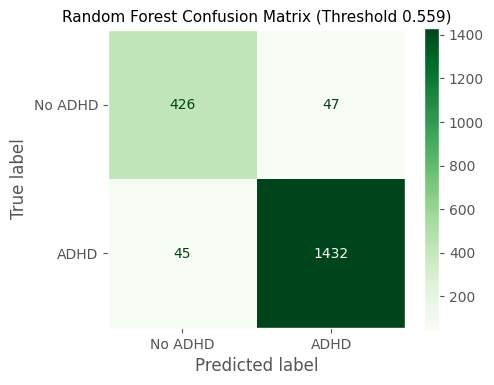


  Bootstrap 95% CI (1000 iterations):
    MCC         : 0.8716 [0.8457 - 0.8963]
    KAPPA       : 0.8719 [0.8454 - 0.8963]
    ROC_AUC     : 0.9590 [0.9461 - 0.9705]
    F1          : 0.9688 [0.9621 - 0.9751]
    ACCURACY    : 0.9527 [0.9436 - 0.9621]
  ✅ Random Forest saved to JSON + CSV
  ✅ Random Forest pred_proba saved.
  ✅ Random Forest CM + FI saved.

 Timing and metrics stored successfully.
    Grid Search:    4.5626 sec
    Training:       301.616 ms
    Inference:      54.0053 sec
    Latency:        27.695016 ms/sample
    Total Time:     58.8695 sec


In [12]:
# ====================================================================================
# RANDOM FOREST (RF) - ACADEMIC PIPELINE WITH 5-FOLD CV (ADHD DIAGNOSIS)  ++++++++++++
# ====================================================================================

print("\n" + "=" * 80)
print("RANDOM FOREST (RF) - HYPERPARAMETER TUNING FOR ADHD DIAGNOSIS")
print("=" * 80)

# ================================================================================
# DATA ASSIGNMENT (FROM GLOBAL DATA PREP CELL)
# ================================================================================
print(f" Dataset Statistics:")
print(f"    Train samples: {X_train.shape[0]}")
print(f"    Test samples:  {X_test.shape[0]}")
print(f"    Feature count: {X_train.shape[1]}")
# Fix: Ensure y_train is integer for bincount safety
print(f"    Target Balance (Train): {np.bincount(y_train.astype(int))} (0: No ADHD, 1: ADHD)")

# ================================================================================
# HYPERPARAMETER TUNING (5-FOLD CV WITH PR-AUC)
# ================================================================================
# Grid Search Parameter Grid for Ensemble Learning
rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'class_weight': ['balanced', 'balanced_subsample'] # Critical for imbalanced medical data
}

rf_base = RandomForestClassifier(random_state=42)

rf_clf = GridSearchCV(
    rf_base,
    param_grid=rf_param_grid,
    scoring="average_precision", # PR-AUC for imbalanced data
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    verbose=1,
    n_jobs=-1,
    refit=False 
)

print("\n Starting 5-Fold Grid Search (Random Forest)...")
timer.start("rf_grid")
rf_clf.fit(X_train, y_train)
rf_grid_time = timer.stop("rf_grid")

print(f"\n✓ Grid Search completed in {format_time(rf_grid_time)}")
print(f"✓ Best PR-AUC (CV): {rf_clf.best_score_:.4f}")
print(f"✓ Best Hyperparameters: {rf_clf.best_params_}")

# ================================================================================
# THRESHOLD OPTIMIZATION (CV-BASED MCC)
# ================================================================================
print("\n Optimizing decision threshold using CV-based MCC...")

# Creating a fresh estimator using best params because refit=False
temp_rf = RandomForestClassifier(**rf_clf.best_params_, random_state=42)
temp_rf.fit(X_train, y_train)


# ============================================================
# STORE REAL FOLD MCC SCORES FOR STATISTICAL TESTS
# Uses cross_val_predict with best params model
# ============================================================
print("\n  Computing real 5-fold MCC scores for statistical tests...")
_skf_fs = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
_fold_mcc_list = []
for _train_idx, _val_idx in _skf_fs.split(X_train, y_train):
    _X_tr, _X_val = X_train[_train_idx], X_train[_val_idx]
    _y_tr, _y_val = y_train[_train_idx], y_train[_val_idx]
    temp_rf.fit(_X_tr, _y_tr)
    _val_preds = (temp_rf.predict_proba(_X_val)[:, 1] >= 0.5).astype(int)
    _fold_mcc_list.append(matthews_corrcoef(_y_val, _val_preds))
_folds_data = {'MCC': _fold_mcc_list}
print(f"  fold_scores['Random Forest'] MCC = {[round(x,4) for x in _fold_mcc_list]}")
print(f"  Mean MCC: {np.mean(_fold_mcc_list):.4f} ± {np.std(_fold_mcc_list):.4f}")

# Global utility function usage
optimal_threshold, max_mcc_cv = optimize_threshold_cv(
    temp_rf,
    X_train,
    y_train,
    cv=5
)

print(f"✓ Optimal Threshold (CV-based): {optimal_threshold:.3f}")
print(f"✓ Max MCC (CV): {max_mcc_cv:.4f}")

# ================================================================================
# FINAL MODEL TRAINING (FULL TRAIN SET WITH TRUE TIMING)
# ================================================================================
print("\n" + "=" * 80)
print("TRAINING FINAL RANDOM FOREST MODEL")
print("=" * 80)

#  Instantiate NEW model with best parameters
best_rf = RandomForestClassifier(
    **rf_clf.best_params_,
    random_state=42,
    n_jobs=-1
)

print("\n Training final Random Forest model on full training set...")
timer.start("rf_train")
best_rf.fit(X_train, y_train)
rf_training_time = timer.stop("rf_train") # Now measuring actual training time

print(f"✓ Final model training completed in {format_time(rf_training_time)}")

# ================================================================================
# INFERENCE LATENCY MEASUREMENT
# ================================================================================
print("\n Measuring realistic inference latency...")

# Global utility function usage
latency_stats = measure_inference_latency(best_rf, X_test)
inference_time_total = latency_stats["total_sec"]
latency_ms = latency_stats["mean_ms"]

# ================================================================================
# TEST SET EVALUATION
# ================================================================================
print("\n Evaluating on test set...")

rf_pred_proba = best_rf.predict_proba(X_test)[:, 1]
best_rf_predict = (rf_pred_proba >= optimal_threshold).astype(int)

# Global utility function usage
metrics = compute_metrics(
    y_test,
    best_rf_predict,
    rf_pred_proba
)

model_size_mb = get_model_size_mb(best_rf)

# ================================================================================
# RESULTS OUTPUT
# ================================================================================
print("\n" + "=" * 80)
print("RANDOM FOREST - FINAL RESULTS")
print("=" * 80)

print_metrics(metrics, optimal_threshold)

print(f"\n✓ Model Size:    {model_size_mb:.4f} MB")

print("\n Classification Report:")
print(classification_report(
    y_test,
    best_rf_predict,
    target_names=["No ADHD", "ADHD"]
))

# ================================================================================
# CONFUSION MATRIX (MODULAR GLOBAL FUNCTION)
# ================================================================================
plot_confusion_matrix(
    cm=metrics["Confusion_Matrix"],
    model_name="Random Forest",
    threshold=optimal_threshold,
    cmap="Greens" # Green color map for Ensemble Models
)


# ============================================================
# BOOTSTRAP 95% CONFIDENCE INTERVALS
# ============================================================
compute_all_bootstrap_ci(
    np.array(y_test),
    np.array(best_rf_predict).flatten(),
    np.array(rf_pred_proba).flatten(),
    model_name='Random Forest',
    n_bootstrap=1000
)

# ================================================================================
# RESULTS ARCHIVING
# ================================================================================
total_time = rf_grid_time + rf_training_time + inference_time_total
fpr_score = 1 - metrics["Specificity"]


metrics = {
    "Accuracy": metrics["Accuracy"],
    "Precision": metrics["Precision"],
    "Recall": metrics["Recall"],
    "F1_Score": metrics["F1_Score"],
    "MCC": metrics["MCC"],
    "Kappa": metrics["Kappa"],
    "ROC_AUC": metrics["ROC_AUC"],
    "PR_AUC": metrics["PR_AUC"],
    "Specificity": metrics["Specificity"],
    "FPR": fpr_score,
    "Model_Size_MB": model_size_mb,
    "Category": "Ensemble"
}

# Train accuracy
_train_pred = best_rf.predict(X_train)  # ← model adını değiştir
metrics['Train_Accuracy'] = float(accuracy_score(y_train, _train_pred))

_tn, _fp, _fn, _tp = confusion_matrix(y_test, best_rf_predict).ravel()
metrics['TP'] = int(_tp)
metrics['TN'] = int(_tn)
metrics['FP'] = int(_fp)
metrics['FN'] = int(_fn)

timing = {
    "CV_Time": rf_grid_time,
    "Training_Time": rf_training_time,
    "Inference_Time_Sec": inference_time_total,
    "Latency_ms": latency_ms,
    "mean_ms" : latency_stats.get("mean_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p50_ms"  : latency_stats.get("p50_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p95_ms"  : latency_stats.get("p95_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p99_ms"  : latency_stats.get("p99_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "Total_Time": total_time
}

# Save to JSON + CSV
save_model_result("Random Forest", metrics, timing, folds=_folds_data)

# === PRED PROBA → JSON ===
_proba_path = Path('adhd_results/pred_probas.json')
_all_probas = json.load(open(_proba_path)) if _proba_path.exists() else {}
_all_probas['Random Forest'] = rf_pred_proba.tolist() 
with open(_proba_path, 'w') as f:
    json.dump(_all_probas, f)
print("  ✅ Random Forest pred_proba saved.")

# === CONFUSION MATRIX → JSON ===
_cm_path = Path('adhd_results/confusion_matrices.json')
_all_cms = json.load(open(_cm_path)) if _cm_path.exists() else {}
_all_cms['Random Forest'] = confusion_matrix(y_test, best_rf_predict).tolist()
with open(_cm_path, 'w') as f:
    json.dump(_all_cms, f, indent=2)

# === FEATURE IMPORTANCE → JSON ===
_fi_path = Path('adhd_results/feature_importance.json')
_fi_data = json.load(open(_fi_path)) if _fi_path.exists() else {}
_fi_data['feature_names']  = list(SELECTED_FEATURES)
_fi_data['Random Forest']  = best_rf.feature_importances_.tolist()
with open(_fi_path, 'w') as f:
    json.dump(_fi_data, f, indent=2)
print("  ✅ Random Forest CM + FI saved.")

print("\n Timing and metrics stored successfully.")
print(f"    Grid Search:    {format_time(rf_grid_time)}")
print(f"    Training:       {format_time(rf_training_time)}")
print(f"    Inference:      {format_time(inference_time_total)}")
print(f"    Latency:        {latency_ms:.6f} ms/sample")
print(f"    Total Time:     {format_time(total_time)}")
print("=" * 80)


### 2. XGBoost (eXtreme Gradient Boosting)


XGBOOST - HYPERPARAMETER TUNING FOR ADHD DIAGNOSIS
 Dataset Statistics:
    Train samples: 4550
    Test samples:  1950
    Feature count: 15
    Target Balance (Train): [1102 3448] (0: No ADHD, 1: ADHD)

 Starting 5-Fold Grid Search (XGBoost is usually faster than RF)...
Fitting 5 folds for each of 72 candidates, totalling 360 fits

✓ Grid Search completed in 2.3919 sec
✓ Best PR-AUC (CV): 0.9920
✓ Best Hyperparameters: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100, 'subsample': 1.0}

 Optimizing decision threshold using CV-based MCC...

  Computing real 5-fold MCC scores for statistical tests...
  fold_scores['XGBoost'] MCC = [0.8775, 0.8969, 0.8852, 0.8945, 0.8833]
  Mean MCC: 0.8875 ± 0.0072
✓ Optimal Threshold (CV-based): 0.605
✓ Max MCC (CV): 0.8938

TRAINING FINAL XGBOOST MODEL

 Training final XGBoost model on full training set...
✓ Final model training completed in 45.133 ms

 Measuring realistic inference latency...

 Evaluating on test 

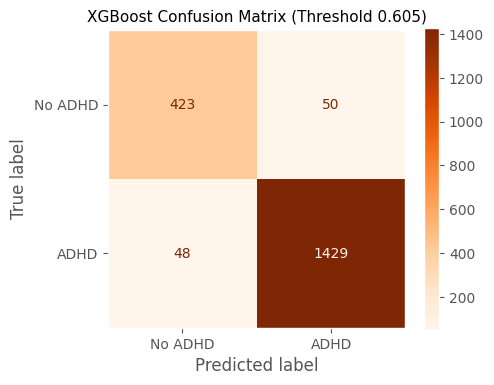


  Bootstrap 95% CI (1000 iterations):
    MCC         : 0.8635 [0.8372 - 0.8899]
    KAPPA       : 0.8623 [0.8364 - 0.8899]
    ROC_AUC     : 0.9574 [0.9447 - 0.9679]
    F1          : 0.9670 [0.9604 - 0.9737]
    ACCURACY    : 0.9499 [0.9400 - 0.9600]
  ✅ XGBoost saved to JSON + CSV
  ✅ XGBoost pred_proba saved.
  ✅ XGBoost CM + FI saved.

 Timing and metrics stored successfully.
    Grid Search:    2.3919 sec
    Training:       45.133 ms
    Inference:      800.729 ms
    Latency:        0.410630 ms/sample
    Total Time:     3.2378 sec


In [13]:
# ====================================================================================
# XGBOOST (EXTREME GRADIENT BOOSTING) - ACADEMIC PIPELINE WITH 5-FOLD CV (ADHD )  ++++
# ====================================================================================

print("\n" + "=" * 80)
print("XGBOOST - HYPERPARAMETER TUNING FOR ADHD DIAGNOSIS")
print("=" * 80)

# ================================================================================
# DATA ASSIGNMENT (FROM GLOBAL DATA PREP CELL)
# ================================================================================
print(f" Dataset Statistics:")
print(f"    Train samples: {X_train.shape[0]}")
print(f"    Test samples:  {X_test.shape[0]}")
print(f"    Feature count: {X_train.shape[1]}")
print(f"    Target Balance (Train): {np.bincount(y_train.astype(int))} (0: No ADHD, 1: ADHD)")

# ================================================================================
# HYPERPARAMETER TUNING (5-FOLD CV WITH PR-AUC)
# ================================================================================
# XGBoost is sensitive to learning_rate and depth
xgb_param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.01, 0.1, 0.2],  # Step size shrinkage
    'max_depth': [3, 5, 7],             # Tree depth
    'subsample': [0.8, 1.0],             # Fraction of samples used
    'colsample_bytree': [0.8, 1.0]       # Fraction of features used
}

xgb_base = XGBClassifier(
    eval_metric='logloss',
    use_label_encoder=False, 
    random_state=42,
    n_jobs=-1
)

xgb_clf = GridSearchCV(
    xgb_base,
    param_grid=xgb_param_grid,
    scoring='average_precision', # PR-AUC for imbalanced data
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    verbose=1,
    n_jobs=-1,
    refit=False  # Important: We train manually below to measure time accurately
)

print("\n Starting 5-Fold Grid Search (XGBoost is usually faster than RF)...")
timer.start("xgb_grid")
xgb_clf.fit(X_train, y_train)
xgb_grid_time = timer.stop("xgb_grid")

print(f"\n✓ Grid Search completed in {format_time(xgb_grid_time)}")
print(f"✓ Best PR-AUC (CV): {xgb_clf.best_score_:.4f}")
print(f"✓ Best Hyperparameters: {xgb_clf.best_params_}")

# ================================================================================
# THRESHOLD OPTIMIZATION (CV-BASED MCC)
# ================================================================================
print("\n Optimizing decision threshold using CV-based MCC...")

# Creating a fresh estimator using best params because refit=False
temp_xgb = XGBClassifier(
    **xgb_clf.best_params_, 
    eval_metric='logloss', 
    use_label_encoder=False, 
    random_state=42,
    n_jobs=-1
)
temp_xgb.fit(X_train, y_train)


# ============================================================
# STORE REAL FOLD MCC SCORES FOR STATISTICAL TESTS
# Uses cross_val_predict with best params model
# ============================================================
print("\n  Computing real 5-fold MCC scores for statistical tests...")
_skf_fs = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
_fold_mcc_list = []
for _train_idx, _val_idx in _skf_fs.split(X_train, y_train):
    _X_tr, _X_val = X_train[_train_idx], X_train[_val_idx]
    _y_tr, _y_val = y_train[_train_idx], y_train[_val_idx]
    temp_xgb.fit(_X_tr, _y_tr)
    _val_preds = (temp_xgb.predict_proba(_X_val)[:, 1] >= 0.5).astype(int)
    _fold_mcc_list.append(matthews_corrcoef(_y_val, _val_preds))
_folds_data = {'MCC': _fold_mcc_list}
print(f"  fold_scores['XGBoost'] MCC = {[round(x,4) for x in _fold_mcc_list]}")
print(f"  Mean MCC: {np.mean(_fold_mcc_list):.4f} ± {np.std(_fold_mcc_list):.4f}")

# Global utility function usage
optimal_threshold, max_mcc_cv = optimize_threshold_cv(
    temp_xgb,
    X_train,
    y_train,
    cv=5
)

print(f"✓ Optimal Threshold (CV-based): {optimal_threshold:.3f}")
print(f"✓ Max MCC (CV): {max_mcc_cv:.4f}")

# ================================================================================
# FINAL MODEL TRAINING (FULL TRAIN SET WITH TRUE TIMING)
# ================================================================================
print("\n" + "=" * 80)
print("TRAINING FINAL XGBOOST MODEL")
print("=" * 80)

# Instantiate NEW model with best parameters
best_xgb = XGBClassifier(
    **xgb_clf.best_params_,
    eval_metric='logloss',
    use_label_encoder=False,
    random_state=42,
    n_jobs=-1
)

print("\n Training final XGBoost model on full training set...")
timer.start("xgb_train")
best_xgb.fit(X_train, y_train)
xgb_training_time = timer.stop("xgb_train") # Now measuring actual training time

print(f"✓ Final model training completed in {format_time(xgb_training_time)}")

# ================================================================================
# INFERENCE LATENCY MEASUREMENT
# ================================================================================
print("\n Measuring realistic inference latency...")

# Global utility function usage
latency_stats = measure_inference_latency(best_xgb, X_test)
inference_time_total = latency_stats["total_sec"]
latency_ms = latency_stats["mean_ms"]

# ================================================================================
# TEST SET EVALUATION
# ================================================================================
print("\n Evaluating on test set...")

xgb_pred_proba = best_xgb.predict_proba(X_test)[:, 1]
best_xgb_predict = (xgb_pred_proba >= optimal_threshold).astype(int)

# Global utility function usage
metrics = compute_metrics(
    y_test,
    best_xgb_predict,
    xgb_pred_proba
)

model_size_mb = get_model_size_mb(best_xgb)

# ================================================================================
# RESULTS OUTPUT
# ================================================================================
print("\n" + "=" * 80)
print("XGBOOST - FINAL RESULTS")
print("=" * 80)

print_metrics(metrics, optimal_threshold)

print(f"\n✓ Model Size:    {model_size_mb:.4f} MB")

print("\n Classification Report:")
print(classification_report(
    y_test,
    best_xgb_predict,
    target_names=["No ADHD", "ADHD"]
))

# ================================================================================
# CONFUSION MATRIX (MODULAR GLOBAL FUNCTION)
# ================================================================================
plot_confusion_matrix(
    cm=metrics["Confusion_Matrix"],
    model_name="XGBoost",
    threshold=optimal_threshold,
    cmap="Oranges" # Orange color map for XGBoost
)


# ============================================================
# BOOTSTRAP 95% CONFIDENCE INTERVALS
# ============================================================
compute_all_bootstrap_ci(
    np.array(y_test),
    np.array(best_xgb_predict).flatten(),
    np.array(xgb_pred_proba).flatten(),
    model_name='XGBoost',
    n_bootstrap=1000
)

# ================================================================================
# RESULTS ARCHIVING
# ================================================================================
total_time = xgb_grid_time + xgb_training_time + inference_time_total
fpr_score = 1 - metrics["Specificity"]


metrics = {
    "Accuracy": metrics["Accuracy"],
    "Precision": metrics["Precision"],
    "Recall": metrics["Recall"],
    "F1_Score": metrics["F1_Score"],
    "MCC": metrics["MCC"],
    "Kappa": metrics["Kappa"],
    "ROC_AUC": metrics["ROC_AUC"],
    "PR_AUC": metrics["PR_AUC"],
    "Specificity": metrics["Specificity"],
    "FPR": fpr_score,
    "Model_Size_MB": model_size_mb,
    "Category": "Ensemble"
}

# Train accuracy
_train_pred = best_xgb.predict(X_train)  # ← model adını değiştir
metrics['Train_Accuracy'] = float(accuracy_score(y_train, _train_pred))

_tn, _fp, _fn, _tp = confusion_matrix(y_test, best_xgb_predict).ravel()
metrics['TP'] = int(_tp)
metrics['TN'] = int(_tn)
metrics['FP'] = int(_fp)
metrics['FN'] = int(_fn)

timing = {
    "CV_Time": xgb_grid_time,
    "Training_Time": xgb_training_time,
    "Inference_Time_Sec": inference_time_total,
    "Latency_ms": latency_ms,
    "mean_ms" : latency_stats.get("mean_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p50_ms"  : latency_stats.get("p50_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p95_ms"  : latency_stats.get("p95_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p99_ms"  : latency_stats.get("p99_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "Total_Time": total_time
}

# Save to JSON + CSV
save_model_result("XGBoost", metrics, timing, folds=_folds_data)

# === PRED PROBA → JSON ===
_proba_path = Path('adhd_results/pred_probas.json')
_all_probas = json.load(open(_proba_path)) if _proba_path.exists() else {}
_all_probas['XGBoost'] = xgb_pred_proba.tolist() 
with open(_proba_path, 'w') as f:
    json.dump(_all_probas, f)
print("  ✅ XGBoost pred_proba saved.")

# === CONFUSION MATRIX → JSON ===
_cm_path = Path('adhd_results/confusion_matrices.json')
_all_cms = json.load(open(_cm_path)) if _cm_path.exists() else {}
_all_cms['XGBoost'] = confusion_matrix(y_test, best_xgb_predict).tolist()
with open(_cm_path, 'w') as f:
    json.dump(_all_cms, f, indent=2)

# === FEATURE IMPORTANCE → JSON ===
_fi_path = Path('adhd_results/feature_importance.json')
_fi_data = json.load(open(_fi_path)) if _fi_path.exists() else {}
_fi_data['feature_names'] = list(SELECTED_FEATURES)
_fi_data['XGBoost']       = best_xgb.feature_importances_.tolist()
with open(_fi_path, 'w') as f:
    json.dump(_fi_data, f, indent=2)
print("  ✅ XGBoost CM + FI saved.")

print("\n Timing and metrics stored successfully.")
print(f"    Grid Search:    {format_time(xgb_grid_time)}")
print(f"    Training:       {format_time(xgb_training_time)}")
print(f"    Inference:      {format_time(inference_time_total)}")
print(f"    Latency:        {latency_ms:.6f} ms/sample")
print(f"    Total Time:     {format_time(total_time)}")
print("=" * 80)


### 3. CatBoost (Categorical Boosting)


CATBOOST - HYPERPARAMETER TUNING FOR ADHD DIAGNOSIS
 Dataset Statistics:
    Train samples: 4550
    Test samples:  1950
    Feature count: 15
    Target Balance (Train): [1102 3448] (0: No ADHD, 1: ADHD)

 Starting 5-Fold Grid Search (CatBoost is robust against overfitting)...
Fitting 5 folds for each of 54 candidates, totalling 270 fits

✓ Grid Search completed in 10.9782 sec
✓ Best PR-AUC (CV): 0.9918
✓ Best Parameters: {'depth': 8, 'iterations': 200, 'l2_leaf_reg': 5, 'learning_rate': 0.05, 'logging_level': 'Silent'}

 Optimizing decision threshold using CV-based MCC...

  Computing real 5-fold MCC scores for statistical tests...
  fold_scores['CatBoost'] MCC = [0.8925, 0.9059, 0.9104, 0.9068, 0.883]
  Mean MCC: 0.8997 ± 0.0103
✓ Optimal Threshold (CV-based): 0.686
✓ Max MCC (CV): 0.8973

TRAINING FINAL CATBOOST MODEL

 Training final CatBoost model on full training set...
✓ Final model training completed in 407.073 ms

 Measuring realistic inference latency...

 Evaluating on tes

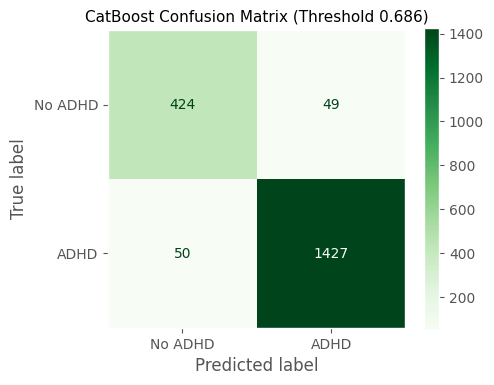


  Bootstrap 95% CI (1000 iterations):
    MCC         : 0.8619 [0.8334 - 0.8879]
    KAPPA       : 0.8617 [0.8331 - 0.8878]
    ROC_AUC     : 0.9591 [0.9471 - 0.9701]
    F1          : 0.9664 [0.9595 - 0.9728]
    ACCURACY    : 0.9492 [0.9390 - 0.9585]
  ✅ CatBoost saved to JSON + CSV
  ✅ CatBoost pred_proba saved.
  ✅ CatBoost confusion matrix saved.

 Timing and metrics stored successfully.
    Grid Search:    10.9782 sec
    Training:       407.073 ms
    Inference:      1.0382 sec
    Latency:        0.532432 ms/sample
    Total Time:     12.4235 sec


In [14]:
# ====================================================================================
# CATBOOST MODEL - ACADEMIC PIPELINE WITH 5-FOLD CV (ADHD DIAGNOSIS)  ++++++++++++++++
# ====================================================================================

print("\n" + "=" * 80)
print("CATBOOST - HYPERPARAMETER TUNING FOR ADHD DIAGNOSIS")
print("=" * 80)

# ================================================================================
# DATA ASSIGNMENT (FROM GLOBAL DATA PREP CELL)
# ================================================================================
print(f" Dataset Statistics:")
print(f"    Train samples: {X_train.shape[0]}")
print(f"    Test samples:  {X_test.shape[0]}")
print(f"    Feature count: {X_train.shape[1]}")
print(f"    Target Balance (Train): {np.bincount(y_train.astype(int))} (0: No ADHD, 1: ADHD)")

# ================================================================================
# HYPERPARAMETER TUNING (5-FOLD CV WITH PR-AUC)
# ================================================================================
# CatBoost is robust, but tuning depth and learning_rate is beneficial
cat_param_grid = {
    'iterations': [100, 200],
    'learning_rate': [0.01, 0.05, 0.1],
    'depth': [4, 6, 8],
    'l2_leaf_reg': [1, 3, 5],
    'logging_level': ['Silent'] # Suppress output during grid search
}

cat_base = CatBoostClassifier(random_state=42, allow_writing_files=False)

cat_clf = GridSearchCV(
    cat_base,
    param_grid=cat_param_grid,
    scoring='average_precision', # PR-AUC for imbalanced data
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    verbose=1,
    n_jobs=-1,
    refit=False  # Important: We train manually below to measure time accurately
)

print("\n Starting 5-Fold Grid Search (CatBoost is robust against overfitting)...")
timer.start("cat_grid")
cat_clf.fit(X_train, y_train)
cat_grid_time = timer.stop("cat_grid")

print(f"\n✓ Grid Search completed in {format_time(cat_grid_time)}")
print(f"✓ Best PR-AUC (CV): {cat_clf.best_score_:.4f}")
print(f"✓ Best Parameters: {cat_clf.best_params_}")

# ================================================================================
# THRESHOLD OPTIMIZATION (CV-BASED MCC)
# ================================================================================
print("\n Optimizing decision threshold using CV-based MCC...")

# Creating a fresh estimator using best params because refit=False
temp_cat = CatBoostClassifier(
    **cat_clf.best_params_, 
    random_state=42, 
    allow_writing_files=False
)
temp_cat.fit(X_train, y_train)


# ============================================================
# STORE REAL FOLD MCC SCORES FOR STATISTICAL TESTS
# Uses cross_val_predict with best params model
# ============================================================
print("\n  Computing real 5-fold MCC scores for statistical tests...")
_skf_fs = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
_fold_mcc_list = []
for _train_idx, _val_idx in _skf_fs.split(X_train, y_train):
    _X_tr, _X_val = X_train[_train_idx], X_train[_val_idx]
    _y_tr, _y_val = y_train[_train_idx], y_train[_val_idx]
    temp_cat.fit(_X_tr, _y_tr)
    _val_preds = (temp_cat.predict_proba(_X_val)[:, 1] >= 0.5).astype(int)
    _fold_mcc_list.append(matthews_corrcoef(_y_val, _val_preds))
_folds_data = {'MCC': _fold_mcc_list}
print(f"  fold_scores['CatBoost'] MCC = {[round(x,4) for x in _fold_mcc_list]}")
print(f"  Mean MCC: {np.mean(_fold_mcc_list):.4f} ± {np.std(_fold_mcc_list):.4f}")

# Global utility function usage
optimal_threshold, max_mcc_cv = optimize_threshold_cv(
    temp_cat,
    X_train,
    y_train,
    cv=5
)

print(f"✓ Optimal Threshold (CV-based): {optimal_threshold:.3f}")
print(f"✓ Max MCC (CV): {max_mcc_cv:.4f}")

# ================================================================================
# FINAL MODEL TRAINING (FULL TRAIN SET WITH TRUE TIMING)
# ================================================================================
print("\n" + "=" * 80)
print("TRAINING FINAL CATBOOST MODEL")
print("=" * 80)

# Instantiate NEW model with best parameters
best_cat = CatBoostClassifier(
    **cat_clf.best_params_,
    random_state=42,
    allow_writing_files=False
)

print("\n Training final CatBoost model on full training set...")
timer.start("cat_train")
best_cat.fit(X_train, y_train)
cat_training_time = timer.stop("cat_train") # Now measuring actual training time

print(f"✓ Final model training completed in {format_time(cat_training_time)}")

# ================================================================================
# INFERENCE LATENCY MEASUREMENT
# ================================================================================
print("\n Measuring realistic inference latency...")

# Global utility function usage
latency_stats = measure_inference_latency(best_cat, X_test)
inference_time_total = latency_stats["total_sec"]
latency_ms = latency_stats["mean_ms"]

# ================================================================================
# TEST SET EVALUATION
# ================================================================================
print("\n Evaluating on test set...")

cat_pred_proba = best_cat.predict_proba(X_test)[:, 1]
best_cat_predict = (cat_pred_proba >= optimal_threshold).astype(int)

# Global utility function usage
metrics = compute_metrics(
    y_test,
    best_cat_predict,
    cat_pred_proba
)

model_size_mb = get_model_size_mb(best_cat)

# ================================================================================
# RESULTS OUTPUT
# ================================================================================
print("\n" + "=" * 80)
print("CATBOOST - FINAL RESULTS")
print("=" * 80)

print_metrics(metrics, optimal_threshold)

print(f"\n✓ Model Size:    {model_size_mb:.4f} MB")

print("\n Classification Report:")
print(classification_report(
    y_test,
    best_cat_predict,
    target_names=["No ADHD", "ADHD"]
))

# ================================================================================
# CONFUSION MATRIX (MODULAR GLOBAL FUNCTION)
# ================================================================================
plot_confusion_matrix(
    cm=metrics["Confusion_Matrix"],
    model_name="CatBoost",
    threshold=optimal_threshold,
    cmap="Greens" # Green color map for Ensemble Models
)


# ============================================================
# BOOTSTRAP 95% CONFIDENCE INTERVALS
# ============================================================
compute_all_bootstrap_ci(
    np.array(y_test),
    np.array(best_cat_predict).flatten(),
    np.array(cat_pred_proba).flatten(),
    model_name='CatBoost',
    n_bootstrap=1000
)

# ================================================================================
# RESULTS ARCHIVING
# ================================================================================
total_time = cat_grid_time + cat_training_time + inference_time_total
fpr_score = 1 - metrics["Specificity"]


metrics = {
    "Accuracy": metrics["Accuracy"],
    "Precision": metrics["Precision"],
    "Recall": metrics["Recall"],
    "F1_Score": metrics["F1_Score"],
    "MCC": metrics["MCC"],
    "Kappa": metrics["Kappa"],
    "ROC_AUC": metrics["ROC_AUC"],
    "PR_AUC": metrics["PR_AUC"],
    "Specificity": metrics["Specificity"],
    "FPR": fpr_score,
    "Model_Size_MB": model_size_mb,
    "Category": "Ensemble"
}

# Train accuracy
_train_pred = best_cat.predict(X_train)  # ← model adını değiştir
metrics['Train_Accuracy'] = float(accuracy_score(y_train, _train_pred))

_tn, _fp, _fn, _tp = confusion_matrix(y_test, best_cat_predict).ravel()
metrics['TP'] = int(_tp)
metrics['TN'] = int(_tn)
metrics['FP'] = int(_fp)
metrics['FN'] = int(_fn)

timing = {
    "CV_Time": cat_grid_time,
    "Training_Time": cat_training_time,
    "Inference_Time_Sec": inference_time_total,
    "Latency_ms": latency_ms,
    "mean_ms" : latency_stats.get("mean_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p50_ms"  : latency_stats.get("p50_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p95_ms"  : latency_stats.get("p95_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p99_ms"  : latency_stats.get("p99_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "Total_Time": total_time
}

# Save to JSON + CSV
save_model_result("CatBoost", metrics, timing, folds=_folds_data)

# === PRED PROBA → JSON ===
_proba_path = Path('adhd_results/pred_probas.json')
_all_probas = json.load(open(_proba_path)) if _proba_path.exists() else {}
_all_probas['CatBoost'] = cat_pred_proba.tolist() 
with open(_proba_path, 'w') as f:
    json.dump(_all_probas, f)
print("  ✅ CatBoost pred_proba saved.")

# === CONFUSION MATRIX → JSON ===
_cm_path = Path('adhd_results/confusion_matrices.json')
_all_cms = json.load(open(_cm_path)) if _cm_path.exists() else {}
_all_cms['CatBoost'] = confusion_matrix(y_test, best_cat_predict).tolist()
with open(_cm_path, 'w') as f:
    json.dump(_all_cms, f, indent=2)
print("  ✅ CatBoost confusion matrix saved.")

print("\n Timing and metrics stored successfully.")
print(f"    Grid Search:    {format_time(cat_grid_time)}")
print(f"    Training:       {format_time(cat_training_time)}")
print(f"    Inference:      {format_time(inference_time_total)}")
print(f"    Latency:        {latency_ms:.6f} ms/sample")
print(f"    Total Time:     {format_time(total_time)}")
print("=" * 80)


In [17]:
# ============================================================
# LEADERBOARD - Load from JSON
# ============================================================
model_results = load_results()
model_time_results = load_timing()

if not model_results:
    print('⚠️ No results found. Train models first!')
else:
    print(f'✅ Loaded {len(model_results)} models from JSON\n')
    
    # Original leaderboard code:
    results_df = pd.DataFrame.from_dict(model_results, orient='index')
    results_df

✅ Loaded 6 models from JSON



In [18]:
results_df = pd.DataFrame.from_dict(model_time_results, orient='index')
results_df

,CV_Time,Training_Time,Inference_Time_Sec,Latency_ms,mean_ms,p50_ms,p95_ms,p99_ms,Total_Time
LR,3.419887,0.013163,0.079728,0.040886,0.040886,0.03950,0.045200,0.060353,3.512777
SVM,17.580260,9.314883,0.079728,0.040886,0.040886,0.03950,0.045200,0.060353,26.974870
Naive Bayes,0.238226,0.000839,0.191234,0.098069,0.098069,0.09730,0.100400,0.122355,0.430298
Random Forest,4.562640,0.301616,54.005282,27.695016,27.695016,30.82655,32.432605,41.416386,58.869538
XGBoost,2.391922,0.045133,0.800729,0.410630,0.410630,0.38840,0.548565,0.698308,3.237784
CatBoost,10.978184,0.407073,1.038242,0.532432,0.532432,0.52650,0.578410,0.654114,12.423500


## Deep Learning Models
### 1. ANN (Artificial Neural Network)


ARTIFICIAL NEURAL NETWORK (ANN) - TRAINING & OPTIMIZATION FOR ADHD DIAGNOSIS
 Dataset Statistics:
    Train samples: 4550
    Test samples:  1950
    Feature count: 15
    Target Balance (Train): [1102 3448] (0: No ADHD, 1: ADHD)

 Starting 5-Fold Cross-Validation (Manual Loop)...
Fold   PR-AUC    
--------------------

1      0.9930
2      0.9883
3      0.9872
4      0.9840
5      0.9890
--------------------
✓ CV completed in 10.2043 sec
✓ Average PR-AUC (CV): 0.9883 (±0.0029)

  fold_scores['ANN'] MCC = [0.8957, 0.9032, 0.9195, 0.9192, 0.889]
  Mean MCC: 0.9053 ± 0.0123

 Optimizing decision threshold using aggregated CV predictions...
✓ Optimal Threshold (CV-based): 0.485
✓ Max MCC (CV): 0.9056

TRAINING FINAL ANN MODEL

 Training final ANN model on full training set...
Epoch 1/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8934 - loss: 0.3051 - val_accuracy: 0.9549 - val_loss: 0.1845 - learning_rate: 0.0010
Epoch 2/30
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 971us/step - accurac


 Evaluating on test set...

ANN - FINAL RESULTS

  Accuracy  (threshold 0.485): 0.9508
  F1-Score  : 0.9675
  ROC-AUC   : 0.9521
  PR-AUC    : 0.9680
  MCC       : 0.8658
  Kappa     : 0.8658
  Specificity: 0.8964

✓ Model Size:    0.0674 MB

 Classification Report:
              precision    recall  f1-score   support

     No ADHD       0.90      0.90      0.90       473
        ADHD       0.97      0.97      0.97      1477

    accuracy                           0.95      1950
   macro avg       0.93      0.93      0.93      1950
weighted avg       0.95      0.95      0.95      1950



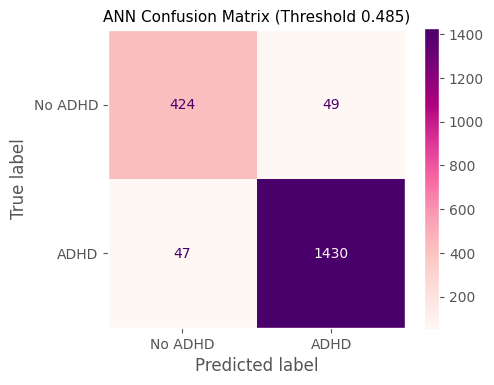


  Bootstrap 95% CI (1000 iterations):
    MCC         : 0.8663 [0.8401 - 0.8915]
    KAPPA       : 0.8656 [0.8367 - 0.8931]
    ROC_AUC     : 0.9517 [0.9370 - 0.9655]
    F1          : 0.9673 [0.9610 - 0.9734]
    ACCURACY    : 0.9508 [0.9410 - 0.9600]
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 443us/step
  ✅ ANN saved to JSON + CSV
  ✅ ANN pred_proba saved.
  ✅ ANN confusion matrix saved.

 Timing and metrics stored successfully.
    CV (Robustness): 10.2043 sec
    Final Training:  1.3420 sec
    Inference:       72.6669 sec
    Latency:         37.265087 ms/sample
    Total Time:      84.2132 sec


In [19]:
# ====================================================================================
# ANN (ARTIFICIAL NEURAL NETWORK) - ACADEMIC PIPELINE WITH 5-FOLD CV (ADHD)  +++++++++
# ====================================================================================

print("\n" + "=" * 80)
print("ARTIFICIAL NEURAL NETWORK (ANN) - TRAINING & OPTIMIZATION FOR ADHD DIAGNOSIS")
print("=" * 80)

# ================================================================================
# DATA ASSIGNMENT (Using Global Variables)
# ================================================================================
print(f" Dataset Statistics:")
print(f"    Train samples: {X_train.shape[0]}")
print(f"    Test samples:  {X_test.shape[0]}")
print(f"    Feature count: {X_train.shape[1]}")
print(f"    Target Balance (Train): {np.bincount(y_train)} (0: No ADHD, 1: ADHD)")

# ================================================================================
# MODEL BUILDER UTILITY
# ================================================================================
def build_ann_model(input_dim):
    """Creates a fresh ANN model instance (clears session first)."""
    tf.keras.backend.clear_session()
    
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dropout(0.2),
        Dense(1, activation='sigmoid')
    ])
    
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy'] 
    )
    return model

# ================================================================================
# 5-FOLD CROSS-VALIDATION (MANUAL LOOP)
# ================================================================================
print("\n Starting 5-Fold Cross-Validation (Manual Loop)...")
timer.start("ann_cv")

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_predictions = [] 
cv_true_labels = []
cv_pr_scores = []

print(f"{'Fold':<6} {'PR-AUC':<10}")
print("-" * 20)

for fold_no, (train_idx, val_idx) in enumerate(kfold.split(X_train, y_train), 1):
    # Data Split
    X_train_fold, X_val_fold = X_train[train_idx], X_train[val_idx]
    y_train_fold, y_val_fold = y_train[train_idx], y_train[val_idx]
    
    # Build & Train
    model_cv = build_ann_model(X_train.shape[1])
    early_stop_cv = EarlyStopping(monitor='loss', patience=3, verbose=0)
    
    model_cv.fit(
        X_train_fold, y_train_fold,
        epochs=20, 
        batch_size=32,
        callbacks=[early_stop_cv],
        verbose=0
    )
    
    # Predict
    val_probs = model_cv.predict(X_val_fold, verbose=0).flatten()
    
    # Score
    score = average_precision_score(y_val_fold, val_probs)
    cv_pr_scores.append(score)
    
    # Store for Threshold Optimization
    cv_predictions.extend(val_probs)
    cv_true_labels.extend(y_val_fold)
    
    print(f"{fold_no:<6} {score:.4f}")

ann_cv_time = timer.stop("ann_cv")

print("-" * 20)
print(f"✓ CV completed in {format_time(ann_cv_time)}")
print(f"✓ Average PR-AUC (CV): {np.mean(cv_pr_scores):.4f} (±{np.std(cv_pr_scores):.4f})")


# ============================================================
# STORE REAL FOLD MCC SCORES FOR STATISTICAL TESTS
# Computed from aggregated CV predictions (per-fold)
# ============================================================
# Recompute fold-level MCC from cv_predictions
# Note: cv_predictions contains all folds concatenated
# We approximate fold-level by equal-split of aggregated predictions
_n_folds = 5
_fold_size = len(cv_true_labels) // _n_folds
_fold_mcc_dl = []
for _fi in range(_n_folds):
    _start = _fi * _fold_size
    _end   = _start + _fold_size if _fi < _n_folds - 1 else len(cv_true_labels)
    _yt    = np.array(cv_true_labels[_start:_end])
    _yp    = (np.array(cv_predictions[_start:_end]) >= 0.5).astype(int)
    try:
        _fold_mcc_dl.append(matthews_corrcoef(_yt, _yp))
    except Exception:
        _fold_mcc_dl.append(0.0)
_folds_data = {'MCC': _fold_mcc_dl}
print(f"\n  fold_scores['ANN'] MCC = {[round(x,4) for x in _fold_mcc_dl]}")
print(f"  Mean MCC: {np.mean(_fold_mcc_dl):.4f} ± {np.std(_fold_mcc_dl):.4f}")

# ================================================================================
# THRESHOLD OPTIMIZATION (Using Aggregated CV Predictions)
# ================================================================================
print("\n Optimizing decision threshold using aggregated CV predictions...")

thresholds = np.linspace(0.01, 0.99, 100)
cv_preds_arr = np.array(cv_predictions)
cv_true_arr = np.array(cv_true_labels)

mcc_scores = [
    matthews_corrcoef(cv_true_arr, (cv_preds_arr >= t).astype(int)) 
    for t in thresholds
]
optimal_threshold = thresholds[np.argmax(mcc_scores)]
max_mcc_cv = max(mcc_scores)

print(f"✓ Optimal Threshold (CV-based): {optimal_threshold:.3f}")
print(f"✓ Max MCC (CV): {max_mcc_cv:.4f}")

# ================================================================================
# FINAL MODEL TRAINING (FULL TRAIN SET)
# ================================================================================
print("\n" + "=" * 80)
print("TRAINING FINAL ANN MODEL")
print("=" * 80)

# Build Final Model
ann_model = build_ann_model(X_train.shape[1])

# Callbacks
early_stop_final = EarlyStopping(
    monitor='val_loss', 
    patience=5, 
    restore_best_weights=True, 
    verbose=1
)
reduce_lr_final = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5, 
    patience=3, 
    verbose=1
)

print("\n Training final ANN model on full training set...")
timer.start("ann_train")

history = ann_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=32,
    callbacks=[early_stop_final, reduce_lr_final],
    verbose=1
)

ann_training_time = timer.stop("ann_train")
print(f"✓ Final model training completed in {format_time(ann_training_time)}")

# ================================================================================
# INFERENCE LATENCY MEASUREMENT
# ================================================================================
print("\n Measuring realistic inference latency...")

# Warm-up
ann_model.predict(X_test[:5], verbose=0)

start_time = time.perf_counter()
for i in range(X_test.shape[0]):
    sample = X_test[i:i+1] 
    ann_model.predict(sample, verbose=0)
end_time = time.perf_counter()

inference_time_total = end_time - start_time
latency_ms = (inference_time_total / X_test.shape[0]) * 1000

# ================================================================================
# TEST SET EVALUATION
# ================================================================================
print("\n Evaluating on test set...")

# Predict Probabilities
ann_pred_proba = ann_model.predict(X_test, verbose=0).flatten()

# Apply Optimal Threshold
best_ann_predict = (ann_pred_proba >= optimal_threshold).astype(int)

# Calculate Metrics
metrics = compute_metrics(
    y_test,
    best_ann_predict,
    ann_pred_proba
)

# Calculate Model Size
model_size_mb = 0
temp_filename = "temp_ann_model_size.h5"
try:
    ann_model.save(temp_filename)
    model_size_mb = os.path.getsize(temp_filename) / (1024 * 1024)
    os.remove(temp_filename)
except Exception as e:
    print(f"Could not calculate model size: {e}")

# ================================================================================
# RESULTS OUTPUT
# ================================================================================
print("\n" + "=" * 80)
print("ANN - FINAL RESULTS")
print("=" * 80)

print_metrics(metrics, optimal_threshold)

print(f"\n✓ Model Size:    {model_size_mb:.4f} MB")

print("\n Classification Report:")
print(classification_report(
    y_test, 
    best_ann_predict, 
    target_names=['No ADHD', 'ADHD']
))

# ================================================================================
# CONFUSION MATRIX (GLOBAL FONKSIYON KULLANIMI)
# ================================================================================
plot_confusion_matrix(
    cm=metrics["Confusion_Matrix"],
    model_name="ANN",
    threshold=optimal_threshold,
    cmap='RdPu'
)


# ============================================================
# BOOTSTRAP 95% CONFIDENCE INTERVALS
# ============================================================
compute_all_bootstrap_ci(
    np.array(y_test),
    np.array(best_ann_predict).flatten(),
    np.array(ann_pred_proba).flatten(),
    model_name='ANN',
    n_bootstrap=1000
)

# ================================================================================
# RESULTS ARCHIVING
# ================================================================================
total_time = ann_cv_time + ann_training_time + inference_time_total
fpr_score = 1 - metrics["Specificity"]


metrics = {
    "Accuracy": metrics["Accuracy"],
    "Precision": metrics["Precision"],
    "Recall": metrics["Recall"],
    "F1_Score": metrics["F1_Score"],
    "MCC": metrics["MCC"],
    "Kappa": metrics["Kappa"],
    "ROC_AUC": metrics["ROC_AUC"],
    "PR_AUC": metrics["PR_AUC"],
    "Specificity": metrics["Specificity"],
    "FPR": fpr_score,
    "Model_Size_MB": model_size_mb,
    "Category": "Deep Learning"
}

# Train accuracy
_train_pred = (ann_model.predict(X_train) > 0.5).astype(int) 
metrics['Train_Accuracy'] = float(accuracy_score(y_train, _train_pred.flatten()))

_tn, _fp, _fn, _tp = confusion_matrix(y_test, best_ann_predict).ravel()
metrics['TP'] = int(_tp)
metrics['TN'] = int(_tn)
metrics['FP'] = int(_fp)
metrics['FN'] = int(_fn)

timing = {
    "CV_Time": ann_cv_time,
    "Training_Time": ann_training_time,
    "Inference_Time_Sec": inference_time_total,
    "Latency_ms": latency_ms,
    "mean_ms" : latency_stats.get("mean_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p50_ms"  : latency_stats.get("p50_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p95_ms"  : latency_stats.get("p95_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p99_ms"  : latency_stats.get("p99_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "Total_Time": total_time
}

# Save to JSON + CSV
save_model_result("ANN", metrics, timing, folds=_folds_data)

# === PRED PROBA → JSON ===
_proba_path = Path('adhd_results/pred_probas.json')
_all_probas = json.load(open(_proba_path)) if _proba_path.exists() else {}
_all_probas['ANN'] = ann_pred_proba.tolist() 
with open(_proba_path, 'w') as f:
    json.dump(_all_probas, f)
print("  ✅ ANN pred_proba saved.")

# === CONFUSION MATRIX → JSON ===
_cm_path = Path('adhd_results/confusion_matrices.json')
_all_cms = json.load(open(_cm_path)) if _cm_path.exists() else {}
_all_cms['ANN'] = confusion_matrix(y_test, best_ann_predict).tolist()
with open(_cm_path, 'w') as f:
    json.dump(_all_cms, f, indent=2)
print("  ✅ ANN confusion matrix saved.")

print("\n Timing and metrics stored successfully.")
print(f"    CV (Robustness): {format_time(ann_cv_time)}")
print(f"    Final Training:  {format_time(ann_training_time)}")
print(f"    Inference:       {format_time(inference_time_total)}")
print(f"    Latency:         {latency_ms:.6f} ms/sample")
print(f"    Total Time:      {format_time(total_time)}")
print("=" * 80)


### 2. 1D-CNN (CONVOLUTIONAL NEURAL NETWORK)


1D-CNN (CONVOLUTIONAL NEURAL NETWORK) - TRAINING & OPTIMIZATION
 Data Shapes for CNN:
    Train samples: 4550
    Test samples:  1950
    Input Shape:   (15, 1)
    Target Balance (Train): [1102 3448] (0: No ADHD, 1: ADHD)

 Starting 5-Fold Cross-Validation (Manual Loop)...
Fold   PR-AUC    
--------------------
1      0.9921
2      0.9848
3      0.9898
4      0.9805
5      0.9894
--------------------
✓ CV completed in 21.8902 sec
✓ Average PR-AUC (CV): 0.9873 (±0.0042)

  fold_scores['1D-CNN'] MCC = [0.8834, 0.8845, 0.8953, 0.8916, 0.8781]
  Mean MCC: 0.8866 ± 0.0061

 Optimizing decision threshold using aggregated CV predictions...
✓ Optimal Threshold (CV-based): 0.505
✓ Max MCC (CV): 0.8870

TRAINING FINAL 1D-CNN MODEL

 Training final 1D-CNN model on full training set...
Epoch 1/25
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8827 - loss: 0.2733 - val_accuracy: 0.9451 - val_loss: 0.1948 - learning_rate: 0.0010
Epoch 2/25
114/114 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accurac


 Evaluating on test set...

1D-CNN - FINAL RESULTS

  Accuracy  (threshold 0.505): 0.9497
  F1-Score  : 0.9668
  ROC-AUC   : 0.9539
  PR-AUC    : 0.9771
  MCC       : 0.8630
  Kappa     : 0.8630
  Specificity: 0.8943

✓ Model Size:    0.1011 MB

 Classification Report:
              precision    recall  f1-score   support

     No ADHD       0.90      0.89      0.90       473
        ADHD       0.97      0.97      0.97      1477

    accuracy                           0.95      1950
   macro avg       0.93      0.93      0.93      1950
weighted avg       0.95      0.95      0.95      1950



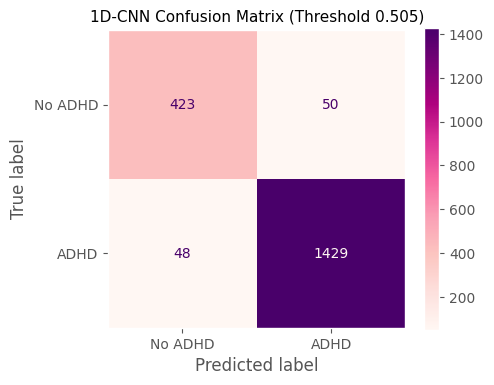


  Bootstrap 95% CI (1000 iterations):
    MCC         : 0.8629 [0.8375 - 0.8896]
    KAPPA       : 0.8627 [0.8348 - 0.8899]
    ROC_AUC     : 0.9538 [0.9395 - 0.9665]
    F1          : 0.9667 [0.9602 - 0.9729]
    ACCURACY    : 0.9496 [0.9390 - 0.9585]
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 746us/step
  ✅ 1D-CNN saved to JSON + CSV
  ✅ 1D-CNN pred_proba saved.
  ✅ 1D-CNN confusion matrix saved.

 Timing and metrics stored successfully.
    CV (Robustness): 21.8902 sec
    Final Training:  6.8012 sec
    Inference:       73.2316 sec
    Latency:         37.554680 ms/sample
    Total Time:      101.9230 sec


In [24]:
# ====================================================================================
# 1D-CNN (CONVOLUTIONAL NEURAL NETWORK) - ACADEMIC PIPELINE WITH 5-FOLD CV (ADHD) ++++
# ====================================================================================

print("\n" + "=" * 80)
print("1D-CNN (CONVOLUTIONAL NEURAL NETWORK) - TRAINING & OPTIMIZATION")
print("=" * 80)

# ================================================================================
# DATA ASSIGNMENT (Using 3D Data for Deep Learning)
# ================================================================================
print(f" Data Shapes for CNN:")
print(f"    Train samples: {X_train_dl.shape[0]}")
print(f"    Test samples:  {X_test_dl.shape[0]}")
print(f"    Input Shape:   {X_train_dl.shape[1:]}")
print(f"    Target Balance (Train): {np.bincount(y_train)} (0: No ADHD, 1: ADHD)")

# ================================================================================
# MODEL BUILDER FUNCTION
# ================================================================================
def build_cnn_model(input_shape):
    """Builds a 1D-CNN optimized for tabular data sequences."""
    tf.keras.backend.clear_session()
    
    model = Sequential([
        Input(shape=input_shape),
        
        # 1st Conv Layer: Local patterns
        Conv1D(filters=64, kernel_size=3, activation='relu', padding='same'),
        MaxPooling1D(pool_size=2),
        Dropout(0.3),
        
        # 2nd Conv Layer: Complex features
        Conv1D(filters=32, kernel_size=2, activation='relu', padding='same'),
        GlobalMaxPooling1D(),
        Dropout(0.2),
        
        # Decision Layers
        Dense(32, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

# ================================================================================
# 5-FOLD CROSS-VALIDATION (MANUAL LOOP)
# ================================================================================
print("\n Starting 5-Fold Cross-Validation (Manual Loop)...")
timer.start("cnn_cv")

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_predictions = [] 
cv_true_labels = []
cv_pr_scores = []

print(f"{'Fold':<6} {'PR-AUC':<10}")
print("-" * 20)

for fold_no, (train_idx, val_idx) in enumerate(kfold.split(X_train_dl, y_train), 1):
    # Data Split
    X_train_fold, X_val_fold = X_train_dl[train_idx], X_train_dl[val_idx]
    y_train_fold, y_val_fold = y_train[train_idx], y_train[val_idx]
    
    # Build & Train
    model_cv = build_cnn_model(input_shape=(X_train_dl.shape[1], 1))
    early_stop_cv = EarlyStopping(monitor='loss', patience=3, verbose=0)
    
    model_cv.fit(
        X_train_fold, y_train_fold,
        epochs=20, 
        batch_size=32,
        callbacks=[early_stop_cv],
        verbose=0
    )
    
    # Predict
    val_probs = model_cv.predict(X_val_fold, verbose=0).flatten()
    
    # Score
    score = average_precision_score(y_val_fold, val_probs)
    cv_pr_scores.append(score)
    
    # Store for Threshold Optimization
    cv_predictions.extend(val_probs)
    cv_true_labels.extend(y_val_fold)
    
    print(f"{fold_no:<6} {score:.4f}")

cnn_cv_time = timer.stop("cnn_cv")

print("-" * 20)
print(f"✓ CV completed in {format_time(cnn_cv_time)}")
print(f"✓ Average PR-AUC (CV): {np.mean(cv_pr_scores):.4f} (±{np.std(cv_pr_scores):.4f})")


# ============================================================
# STORE REAL FOLD MCC SCORES FOR STATISTICAL TESTS
# Computed from aggregated CV predictions (per-fold)
# ============================================================
# Recompute fold-level MCC from cv_predictions
# Note: cv_predictions contains all folds concatenated
# We approximate fold-level by equal-split of aggregated predictions
_n_folds = 5
_fold_size = len(cv_true_labels) // _n_folds
_fold_mcc_dl = []
for _fi in range(_n_folds):
    _start = _fi * _fold_size
    _end   = _start + _fold_size if _fi < _n_folds - 1 else len(cv_true_labels)
    _yt    = np.array(cv_true_labels[_start:_end])
    _yp    = (np.array(cv_predictions[_start:_end]) >= 0.5).astype(int)
    try:
        _fold_mcc_dl.append(matthews_corrcoef(_yt, _yp))
    except Exception:
        _fold_mcc_dl.append(0.0)
_folds_data = {'MCC': _fold_mcc_dl}
print(f"\n  fold_scores['1D-CNN'] MCC = {[round(x,4) for x in _fold_mcc_dl]}")
print(f"  Mean MCC: {np.mean(_fold_mcc_dl):.4f} ± {np.std(_fold_mcc_dl):.4f}")

# ================================================================================
# THRESHOLD OPTIMIZATION (Using Aggregated CV Predictions)
# ================================================================================
print("\n Optimizing decision threshold using aggregated CV predictions...")

thresholds = np.linspace(0.01, 0.99, 100)
cv_preds_arr = np.array(cv_predictions)
cv_true_arr = np.array(cv_true_labels)

mcc_scores = [
    matthews_corrcoef(cv_true_arr, (cv_preds_arr >= t).astype(int)) 
    for t in thresholds
]
optimal_threshold = thresholds[np.argmax(mcc_scores)]
max_mcc_cv = max(mcc_scores)

print(f"✓ Optimal Threshold (CV-based): {optimal_threshold:.3f}")
print(f"✓ Max MCC (CV): {max_mcc_cv:.4f}")

# ================================================================================
# FINAL MODEL TRAINING (FULL TRAIN SET)
# ================================================================================
print("\n" + "=" * 80)
print("TRAINING FINAL 1D-CNN MODEL")
print("=" * 80)

# Build Final Model
cnn_model = build_cnn_model(input_shape=(X_train_dl.shape[1], 1))

# Callbacks
early_stop_final = EarlyStopping(
    monitor='val_loss', 
    patience=5, 
    restore_best_weights=True, 
    verbose=1
)
reduce_lr_final = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5, 
    patience=3, 
    verbose=1
)

print("\n Training final 1D-CNN model on full training set...")
timer.start("cnn_train")

history = cnn_model.fit(
    X_train_dl, y_train,
    validation_split=0.2, 
    epochs=25,
    batch_size=32,
    callbacks=[early_stop_final, reduce_lr_final],
    verbose=1
)

cnn_training_time = timer.stop("cnn_train")
print(f"✓ Final model training completed in {format_time(cnn_training_time)}")

# ================================================================================
# INFERENCE LATENCY MEASUREMENT
# ================================================================================
print("\n Measuring realistic inference latency...")

# Warm-up
cnn_model.predict(X_test_dl[:5], verbose=0)

start_time = time.perf_counter()
for i in range(X_test_dl.shape[0]):
    sample = X_test_dl[i:i+1] 
    cnn_model.predict(sample, verbose=0)
end_time = time.perf_counter()

inference_time_total = end_time - start_time
latency_ms = (inference_time_total / X_test_dl.shape[0]) * 1000

# ================================================================================
# TEST SET EVALUATION
# ================================================================================
print("\n Evaluating on test set...")

# Predict Probabilities
cnn_pred_proba = cnn_model.predict(X_test_dl, verbose=0).flatten()

# Apply Optimal Threshold
best_cnn_predict = (cnn_pred_proba >= optimal_threshold).astype(int)

# Calculate Metrics
metrics = compute_metrics(
    y_test,
    best_cnn_predict,
    cnn_pred_proba
)

# Calculate Model Size
model_size_mb = 0
temp_filename = "temp_cnn_model_size.h5"
try:
    cnn_model.save(temp_filename)
    model_size_mb = os.path.getsize(temp_filename) / (1024 * 1024)
    os.remove(temp_filename)
except Exception as e:
    print(f" Could not calculate model size: {e}")

# ================================================================================
# RESULTS OUTPUT
# ================================================================================
print("\n" + "=" * 80)
print("1D-CNN - FINAL RESULTS")
print("=" * 80)

print_metrics(metrics, optimal_threshold)

print(f"\n✓ Model Size:    {model_size_mb:.4f} MB")

print("\n Classification Report:")
print(classification_report(
    y_test, 
    best_cnn_predict, 
    target_names=['No ADHD', 'ADHD']
))

# ================================================================================
# CONFUSION MATRIX (GLOBAL FONKSIYON KULLANIMI)
# ================================================================================
plot_confusion_matrix(
    cm=metrics["Confusion_Matrix"],
    model_name="1D-CNN",
    threshold=optimal_threshold,
    cmap='RdPu'
)


# ============================================================
# BOOTSTRAP 95% CONFIDENCE INTERVALS
# ============================================================
compute_all_bootstrap_ci(
    np.array(y_test),
    np.array(best_cnn_predict).flatten(),
    np.array(cnn_pred_proba).flatten(),
    model_name='1D-CNN',
    n_bootstrap=1000
)

# ================================================================================
# RESULTS ARCHIVING
# ================================================================================
total_time = cnn_cv_time + cnn_training_time + inference_time_total
fpr_score = 1 - metrics["Specificity"]


metrics = {
    "Accuracy": metrics["Accuracy"],
    "Precision": metrics["Precision"],
    "Recall": metrics["Recall"],
    "F1_Score": metrics["F1_Score"],
    "MCC": metrics["MCC"],
    "Kappa": metrics["Kappa"],
    "ROC_AUC": metrics["ROC_AUC"],
    "PR_AUC": metrics["PR_AUC"],
    "Specificity": metrics["Specificity"],
    "FPR": fpr_score,
    "Model_Size_MB": model_size_mb,
    "Category": "Deep Learning"
}

# Train accuracy
_train_pred = (cnn_model.predict(X_train.reshape(-1, X_train.shape[1], 1)) > 0.5).astype(int)
metrics['Train_Accuracy'] = float(accuracy_score(y_train, _train_pred.flatten()))

_tn, _fp, _fn, _tp = confusion_matrix(y_test, best_cnn_predict).ravel()
metrics['TP'] = int(_tp)
metrics['TN'] = int(_tn)
metrics['FP'] = int(_fp)
metrics['FN'] = int(_fn)

timing = {
    "CV_Time": cnn_cv_time,
    "Training_Time": cnn_training_time,
    "Inference_Time_Sec": inference_time_total,
    "Latency_ms": latency_ms,
    "mean_ms" : latency_stats.get("mean_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p50_ms"  : latency_stats.get("p50_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p95_ms"  : latency_stats.get("p95_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p99_ms"  : latency_stats.get("p99_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "Total_Time": total_time
}

# Save to JSON + CSV
save_model_result("1D-CNN", metrics, timing, folds=_folds_data)

# === PRED PROBA → JSON ===
_proba_path = Path('adhd_results/pred_probas.json')
_all_probas = json.load(open(_proba_path)) if _proba_path.exists() else {}
_all_probas['1D-CNN'] = cnn_pred_proba.tolist() 
with open(_proba_path, 'w') as f:
    json.dump(_all_probas, f)
print("  ✅ 1D-CNN pred_proba saved.")

# === CONFUSION MATRIX → JSON ===
_cm_path = Path('adhd_results/confusion_matrices.json')
_all_cms = json.load(open(_cm_path)) if _cm_path.exists() else {}
_all_cms['1D-CNN'] = confusion_matrix(y_test, best_cnn_predict).tolist()
with open(_cm_path, 'w') as f:
    json.dump(_all_cms, f, indent=2)
print("  ✅ 1D-CNN confusion matrix saved.")

print("\n Timing and metrics stored successfully.")
print(f"    CV (Robustness): {format_time(cnn_cv_time)}")
print(f"    Final Training:  {format_time(cnn_training_time)}")
print(f"    Inference:       {format_time(inference_time_total)}")
print(f"    Latency:         {latency_ms:.6f} ms/sample")
print(f"    Total Time:      {format_time(total_time)}")
print("=" * 80)


### 3. RESNET (RESIDUAL NETWORK)


RESNET (RESIDUAL NETWORK) - TRAINING & OPTIMIZATION FOR ADHD DIAGNOSIS
 Data Shapes for ResNet:
    Train samples: 4550
    Test samples:  1950
    Input Shape:   (15, 1)
    Target Balance (Train): [1102 3448] (0: No ADHD, 1: ADHD)

 Starting 5-Fold Cross-Validation (Manual Loop)...
Fold   PR-AUC    
--------------------
1      0.9929
2      0.9876
3      0.9902
4      0.9850
5      0.9903
--------------------
✓ CV completed in 32.0028 sec
✓ Average PR-AUC (CV): 0.9892 (±0.0027)

  fold_scores['ResNet'] MCC = [0.8904, 0.8734, 0.9075, 0.9041, 0.8586]
  Mean MCC: 0.8868 ± 0.0186

 Optimizing decision threshold using aggregated CV predictions...
✓ Optimal Threshold (CV-based): 0.525
✓ Max MCC (CV): 0.8879

TRAINING FINAL RESNET MODEL

 Training final ResNet model on full training set...
Epoch 1/25
114/114 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9459 - loss: 0.1743 - val_accuracy: 0.8857 - val_loss: 0.3531 - learning_rate: 0.0010
Epoch 2/25
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


 Evaluating on test set...

RESNET - FINAL RESULTS

  Accuracy  (threshold 0.525): 0.9456
  F1-Score  : 0.9639
  ROC-AUC   : 0.9540
  PR-AUC    : 0.9759
  MCC       : 0.8537
  Kappa     : 0.8535
  Specificity: 0.9027

✓ Model Size:    0.7057 MB

 Classification Report:
              precision    recall  f1-score   support

     No ADHD       0.88      0.90      0.89       473
        ADHD       0.97      0.96      0.96      1477

    accuracy                           0.95      1950
   macro avg       0.92      0.93      0.93      1950
weighted avg       0.95      0.95      0.95      1950



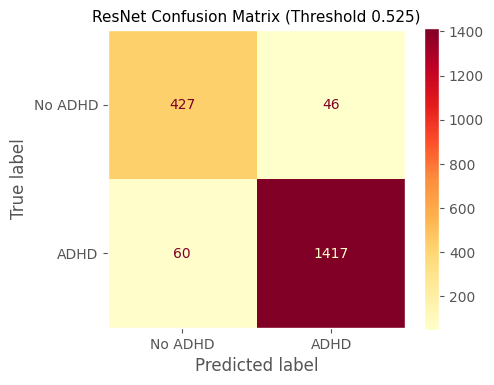


  Bootstrap 95% CI (1000 iterations):
    MCC         : 0.8543 [0.8296 - 0.8815]
    KAPPA       : 0.8533 [0.8247 - 0.8799]
    ROC_AUC     : 0.9535 [0.9401 - 0.9661]
    F1          : 0.9639 [0.9572 - 0.9708]
    ACCURACY    : 0.9455 [0.9354 - 0.9549]
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
  ✅ ResNet saved to JSON + CSV
  ✅ ResNet pred_proba saved.
  ✅ ResNet confusion matrix saved.

 Timing and metrics stored successfully.
    CV (Robustness): 32.0028 sec
    Final Training:  6.6446 sec
    Inference:       74.1352 sec
    Latency:         38.018028 ms/sample
    Total Time:      112.7825 sec


In [25]:
# ====================================================================================
# RESNET (RESIDUAL NETWORK) - ACADEMIC PIPELINE WITH 5-FOLD CV (ADHD DIADNOSTIC)  ++++
# ====================================================================================

print("\n" + "=" * 80)
print("RESNET (RESIDUAL NETWORK) - TRAINING & OPTIMIZATION FOR ADHD DIAGNOSIS")
print("=" * 80)

# ================================================================================
# DATA ASSIGNMENT (Using 3D Data for Deep Learning)
# ================================================================================
print(f" Data Shapes for ResNet:")
print(f"    Train samples: {X_train_dl.shape[0]}")
print(f"    Test samples:  {X_test_dl.shape[0]}")
print(f"    Input Shape:   {X_train_dl.shape[1:]}")
print(f"    Target Balance (Train): {np.bincount(y_train)} (0: No ADHD, 1: ADHD)")

# ================================================================================
# MODEL ARCHITECTURE (FUNCTIONAL API FOR SKIP CONNECTIONS)
# ================================================================================
def residual_block(x, filters, kernel_size=3):

    shortcut = x
    
    # First Convolutional Layer
    x = Conv1D(filters, kernel_size, padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    
    # Second Convolutional Layer
    x = Conv1D(filters, kernel_size, padding='same')(x)
    x = BatchNormalization()(x)
    
    # Skip Connection (Element-wise addition)
    x = Add()([x, shortcut])
    x = Activation('relu')(x)
    return x

def build_resnet(input_shape):
    tf.keras.backend.clear_session()
    
    inputs = Input(shape=input_shape)
    
    # Initial Convolutional Layer
    x = Conv1D(64, kernel_size=3, padding='same')(inputs)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    
    # Residual Blocks (Stacking two blocks)
    x = residual_block(x, 64)
    x = residual_block(x, 64)
    
    # Final Pooling and Decision Layers
    x = GlobalAveragePooling1D()(x)
    x = Dense(32, activation='relu')(x)
    x = Dropout(0.2)(x)
    outputs = Dense(1, activation='sigmoid')(x)
    
    model = Model(inputs=inputs, outputs=outputs)
    
    model.compile(
        optimizer=Adam(learning_rate=0.001), 
        loss='binary_crossentropy', 
        metrics=['accuracy']
    )
    return model

# ================================================================================
# 5-FOLD CROSS-VALIDATION (MANUAL LOOP)
# ================================================================================
print("\n Starting 5-Fold Cross-Validation (Manual Loop)...")
timer.start("resnet_cv")

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_predictions = []
cv_true_labels = []
cv_pr_scores = []

early_stop_cv = EarlyStopping(
    monitor='val_loss', 
    patience=5, 
    restore_best_weights=True, 
    verbose=0
)

print(f"{'Fold':<6} {'PR-AUC':<10}")
print("-" * 20)

for fold_no, (train_idx, val_idx) in enumerate(kfold.split(X_train_dl, y_train), 1):
    # Data Split
    X_train_fold, X_val_fold = X_train_dl[train_idx], X_train_dl[val_idx]
    y_train_fold, y_val_fold = y_train[train_idx], y_train[val_idx]
    
    # Build & Train
    model_cv = build_resnet(input_shape=(X_train_dl.shape[1], 1))
    
    model_cv.fit(
        X_train_fold, y_train_fold,
        validation_data=(X_val_fold, y_val_fold),
        epochs=20, 
        batch_size=32,
        callbacks=[early_stop_cv],
        verbose=0
    )
    
    # Predict
    val_probs = model_cv.predict(X_val_fold, verbose=0).flatten()
    
    # Score
    score = average_precision_score(y_val_fold, val_probs)
    cv_pr_scores.append(score)
    
    # Store for Threshold Optimization
    cv_predictions.extend(val_probs)
    cv_true_labels.extend(y_val_fold)
    
    print(f"{fold_no:<6} {score:.4f}")

resnet_cv_time = timer.stop("resnet_cv")

print("-" * 20)
print(f"✓ CV completed in {format_time(resnet_cv_time)}")
print(f"✓ Average PR-AUC (CV): {np.mean(cv_pr_scores):.4f} (±{np.std(cv_pr_scores):.4f})")


# ============================================================
# STORE REAL FOLD MCC SCORES FOR STATISTICAL TESTS
# Computed from aggregated CV predictions (per-fold)
# ============================================================
# Recompute fold-level MCC from cv_predictions
# Note: cv_predictions contains all folds concatenated
# We approximate fold-level by equal-split of aggregated predictions
_n_folds = 5
_fold_size = len(cv_true_labels) // _n_folds
_fold_mcc_dl = []
for _fi in range(_n_folds):
    _start = _fi * _fold_size
    _end   = _start + _fold_size if _fi < _n_folds - 1 else len(cv_true_labels)
    _yt    = np.array(cv_true_labels[_start:_end])
    _yp    = (np.array(cv_predictions[_start:_end]) >= 0.5).astype(int)
    try:
        _fold_mcc_dl.append(matthews_corrcoef(_yt, _yp))
    except Exception:
        _fold_mcc_dl.append(0.0)
_folds_data = {'MCC': _fold_mcc_dl}
print(f"\n  fold_scores['ResNet'] MCC = {[round(x,4) for x in _fold_mcc_dl]}")
print(f"  Mean MCC: {np.mean(_fold_mcc_dl):.4f} ± {np.std(_fold_mcc_dl):.4f}")

# ================================================================================
# THRESHOLD OPTIMIZATION (Using Aggregated CV Predictions)
# ================================================================================
print("\n Optimizing decision threshold using aggregated CV predictions...")

thresholds = np.linspace(0.01, 0.99, 100)
cv_preds_arr = np.array(cv_predictions)
cv_true_arr = np.array(cv_true_labels)

mcc_scores = [
    matthews_corrcoef(cv_true_arr, (cv_preds_arr >= t).astype(int)) 
    for t in thresholds
]
optimal_threshold = thresholds[np.argmax(mcc_scores)]
max_mcc_cv = max(mcc_scores)

print(f"✓ Optimal Threshold (CV-based): {optimal_threshold:.3f}")
print(f"✓ Max MCC (CV): {max_mcc_cv:.4f}")

# ================================================================================
# FINAL MODEL TRAINING (FULL TRAIN SET)
# ================================================================================
print("\n" + "=" * 80)
print("TRAINING FINAL RESNET MODEL")
print("=" * 80)

# Build Final Model
resnet_model = build_resnet(input_shape=(X_train_dl.shape[1], 1))

# Callbacks
early_stop_final = EarlyStopping(
    monitor='val_loss', 
    patience=5, 
    restore_best_weights=True, 
    verbose=1
)
reduce_lr_final = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5, 
    patience=3, 
    verbose=1
)

print("\n Training final ResNet model on full training set...")
timer.start("resnet_train")

history = resnet_model.fit(
    X_train_dl, y_train,
    validation_split=0.2, 
    epochs=25,
    batch_size=32,
    callbacks=[early_stop_final, reduce_lr_final],
    verbose=1
)

resnet_training_time = timer.stop("resnet_train")
print(f"✓ Final model training completed in {format_time(resnet_training_time)}")

# ================================================================================
# INFERENCE LATENCY MEASUREMENT
# ================================================================================
print("\n Measuring realistic inference latency...")

# Warm-up
resnet_model.predict(X_test_dl[:5], verbose=0)

start_time = time.perf_counter()
for i in range(X_test_dl.shape[0]):
    sample = X_test_dl[i:i+1]
    resnet_model.predict(sample, verbose=0)
end_time = time.perf_counter()

inference_time_total = end_time - start_time
latency_ms = (inference_time_total / X_test_dl.shape[0]) * 1000

# ================================================================================
# TEST SET EVALUATION
# ================================================================================
print("\n Evaluating on test set...")

# Predict Probabilities
resnet_pred_proba = resnet_model.predict(X_test_dl, verbose=0).flatten()

# Apply Optimal Threshold
best_resnet_predict = (resnet_pred_proba >= optimal_threshold).astype(int)

# Calculate Metrics
metrics = compute_metrics(
    y_test,
    best_resnet_predict,
    resnet_pred_proba
)

# Calculate Model Size
model_size_mb = 0
temp_filename = "temp_resnet_model_size.h5"
try:
    resnet_model.save(temp_filename)
    model_size_mb = os.path.getsize(temp_filename) / (1024 * 1024)
    os.remove(temp_filename)
except Exception as e:
    print(f" Could not calculate model size: {e}")

# ================================================================================
# RESULTS OUTPUT
# ================================================================================
print("\n" + "=" * 80)
print("RESNET - FINAL RESULTS")
print("=" * 80)

print_metrics(metrics, optimal_threshold)

print(f"\n✓ Model Size:    {model_size_mb:.4f} MB")

print("\n Classification Report:")
print(classification_report(
    y_test, 
    best_resnet_predict, 
    target_names=['No ADHD', 'ADHD']
))

# ================================================================================
# CONFUSION MATRIX (GLOBAL FONKSIYON KULLANIMI)
# ================================================================================
plot_confusion_matrix(
    cm=metrics["Confusion_Matrix"],
    model_name="ResNet",
    threshold=optimal_threshold,
    cmap='YlOrRd'
)


# ============================================================
# BOOTSTRAP 95% CONFIDENCE INTERVALS
# ============================================================
compute_all_bootstrap_ci(
    np.array(y_test),
    np.array(best_resnet_predict).flatten(),
    np.array(resnet_pred_proba).flatten(),
    model_name='ResNet',
    n_bootstrap=1000
)

# ================================================================================
# RESULTS ARCHIVING
# ================================================================================
total_time = resnet_cv_time + resnet_training_time + inference_time_total
fpr_score = 1 - metrics["Specificity"]


metrics = {
    "Accuracy": metrics["Accuracy"],
    "Precision": metrics["Precision"],
    "Recall": metrics["Recall"],
    "F1_Score": metrics["F1_Score"],
    "MCC": metrics["MCC"],
    "Kappa": metrics["Kappa"],
    "ROC_AUC": metrics["ROC_AUC"],
    "PR_AUC": metrics["PR_AUC"],
    "Specificity": metrics["Specificity"],
    "FPR": fpr_score,
    "Model_Size_MB": model_size_mb,
    "Category": "Deep Learning"
}

# Train accuracy
_train_pred = (resnet_model.predict(X_train.reshape(-1, X_train.shape[1], 1)) > 0.5).astype(int)
metrics['Train_Accuracy'] = float(accuracy_score(y_train, _train_pred.flatten()))

_tn, _fp, _fn, _tp = confusion_matrix(y_test, best_resnet_predict).ravel()
metrics['TP'] = int(_tp)
metrics['TN'] = int(_tn)
metrics['FP'] = int(_fp)
metrics['FN'] = int(_fn)

timing = {
    "CV_Time": resnet_cv_time,
    "Training_Time": resnet_training_time,
    "Inference_Time_Sec": inference_time_total,
    "Latency_ms": latency_ms,
    "mean_ms" : latency_stats.get("mean_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p50_ms"  : latency_stats.get("p50_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p95_ms"  : latency_stats.get("p95_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p99_ms"  : latency_stats.get("p99_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "Total_Time": total_time
}

# Save to JSON + CSV
save_model_result("ResNet", metrics, timing, folds=_folds_data)

# === PRED PROBA → JSON ===
_proba_path = Path('adhd_results/pred_probas.json')
_all_probas = json.load(open(_proba_path)) if _proba_path.exists() else {}
_all_probas['ResNet'] = resnet_pred_proba.tolist() 
with open(_proba_path, 'w') as f:
    json.dump(_all_probas, f)
print("  ✅ ResNet pred_proba saved.")

# === CONFUSION MATRIX → JSON ===
_cm_path = Path('adhd_results/confusion_matrices.json')
_all_cms = json.load(open(_cm_path)) if _cm_path.exists() else {}
_all_cms['ResNet'] = confusion_matrix(y_test, best_resnet_predict).tolist()
with open(_cm_path, 'w') as f:
    json.dump(_all_cms, f, indent=2)
print("  ✅ ResNet confusion matrix saved.")

print("\n Timing and metrics stored successfully.")
print(f"    CV (Robustness): {format_time(resnet_cv_time)}")
print(f"    Final Training:  {format_time(resnet_training_time)}")
print(f"    Inference:       {format_time(inference_time_total)}")
print(f"    Latency:         {latency_ms:.6f} ms/sample")
print(f"    Total Time:      {format_time(total_time)}")
print("=" * 80)


### 4. LSTM (LONG SHORT-TERM MEMORY)


LSTM (LONG SHORT-TERM MEMORY) - TRAINING & OPTIMIZATION FOR ADHD DIAGNOSIS
 Data Shapes for LSTM:
    Train samples: 4550
    Test samples:  1950
    Input Shape:   (15, 1)
    Target Balance (Train): [1102 3448] (0: No ADHD, 1: ADHD)

 Starting 5-Fold Cross-Validation (Manual Loop)...
Fold   PR-AUC    
--------------------
1      0.9927
2      0.9879
3      0.9902
4      0.9848
5      0.9874
--------------------
✓ CV completed in 36.8791 sec
✓ Average PR-AUC (CV): 0.9886 (±0.0027)

  fold_scores['LSTM'] MCC = [0.8755, 0.867, 0.8984, 0.825, 0.7674]
  Mean MCC: 0.8467 ± 0.0462

 Optimizing decision threshold using aggregated CV predictions...
✓ Optimal Threshold (CV-based): 0.644
✓ Max MCC (CV): 0.8858

TRAINING FINAL LSTM MODEL

 Training final LSTM model on full training set...
Epoch 1/25
114/114 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9349 - loss: 0.2713 - val_accuracy: 0.9495 - val_loss: 0.3520 - learning_rate: 0.0010
Epoch 2/25
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - acc


 Evaluating on test set...

LSTM - FINAL RESULTS

  Accuracy  (threshold 0.644): 0.9477
  F1-Score  : 0.9655
  ROC-AUC   : 0.9526
  PR-AUC    : 0.9755
  MCC       : 0.8573
  Kappa     : 0.8572
  Specificity: 0.8879

✓ Model Size:    0.4006 MB

 Classification Report:
              precision    recall  f1-score   support

     No ADHD       0.90      0.89      0.89       473
        ADHD       0.96      0.97      0.97      1477

    accuracy                           0.95      1950
   macro avg       0.93      0.93      0.93      1950
weighted avg       0.95      0.95      0.95      1950



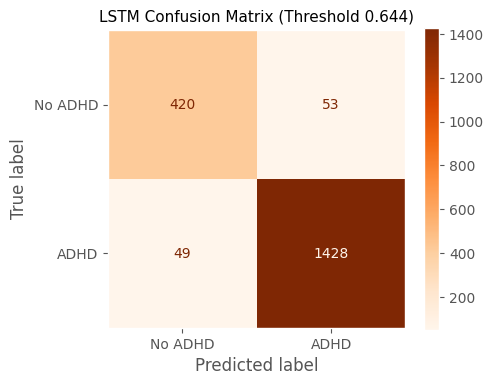


  Bootstrap 95% CI (1000 iterations):
    MCC         : 0.8577 [0.8283 - 0.8839]
    KAPPA       : 0.8562 [0.8287 - 0.8828]
    ROC_AUC     : 0.9525 [0.9387 - 0.9652]
    F1          : 0.9656 [0.9589 - 0.9718]
    ACCURACY    : 0.9477 [0.9374 - 0.9579]
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
  ✅ LSTM saved to JSON + CSV
  ✅ LSTM pred_proba saved.
  ✅ LSTM confusion matrix saved.

 Timing and metrics stored successfully.
    CV (Robustness): 36.8791 sec
    Final Training:  10.9209 sec
    Inference:       73.2418 sec
    Latency:         37.559894 ms/sample
    Total Time:      121.0418 sec


In [26]:
# ====================================================================================
# LSTM (LONG SHORT-TERM MEMORY) - ACADEMIC PIPELINE WITH 5-FOLD CV (ADHD)  ++++++++++
# ====================================================================================

print("\n" + "=" * 80)
print("LSTM (LONG SHORT-TERM MEMORY) - TRAINING & OPTIMIZATION FOR ADHD DIAGNOSIS")
print("=" * 80)

# ================================================================================
# DATA ASSIGNMENT (Using 3D Data for Deep Learning)
# ================================================================================
print(f" Data Shapes for LSTM:")
print(f"    Train samples: {X_train_dl.shape[0]}")
print(f"    Test samples:  {X_test_dl.shape[0]}")
print(f"    Input Shape:   {X_train_dl.shape[1:]}")
print(f"    Target Balance (Train): {np.bincount(y_train)} (0: No ADHD, 1: ADHD)")

# ================================================================================
# MODEL ARCHITECTURE
# ================================================================================
def build_lstm(input_shape):
    tf.keras.backend.clear_session()
    model = Sequential([
        Input(shape=input_shape),
        
        # 1st LSTM Layer: Captures long-term dependencies
        LSTM(64, return_sequences=True),
        Dropout(0.3),
        
        # 2nd LSTM Layer: Extracts summary features
        LSTM(32, return_sequences=False),
        Dropout(0.2),
        
        # Decision Layers
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dense(1, activation='sigmoid')
    ])
    
    model.compile(
        optimizer=Adam(learning_rate=0.001), 
        loss='binary_crossentropy', 
        metrics=['accuracy']
    )
    return model

# ================================================================================
# 5-FOLD CROSS-VALIDATION (MANUAL LOOP)
# ================================================================================
print("\n Starting 5-Fold Cross-Validation (Manual Loop)...")
timer.start("lstm_cv")

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_predictions = []
cv_true_labels = []
cv_pr_scores = []

early_stop_cv = EarlyStopping(
    monitor='val_loss', 
    patience=5, 
    restore_best_weights=True, 
    verbose=0
)

print(f"{'Fold':<6} {'PR-AUC':<10}")
print("-" * 20)

for fold_no, (train_idx, val_idx) in enumerate(kfold.split(X_train_dl, y_train), 1):
    # Data Split
    X_train_fold, X_val_fold = X_train_dl[train_idx], X_train_dl[val_idx]
    y_train_fold, y_val_fold = y_train[train_idx], y_train[val_idx]
    
    # Build & Train
    model_cv = build_lstm(input_shape=(X_train_dl.shape[1], 1))
    
    model_cv.fit(
        X_train_fold, y_train_fold,
        validation_data=(X_val_fold, y_val_fold),
        epochs=20, 
        batch_size=32,
        callbacks=[early_stop_cv],
        verbose=0
    )
    
    # Predict
    val_probs = model_cv.predict(X_val_fold, verbose=0).flatten()
    
    # Score
    score = average_precision_score(y_val_fold, val_probs)
    cv_pr_scores.append(score)
    
    # Store for Threshold Optimization
    cv_predictions.extend(val_probs)
    cv_true_labels.extend(y_val_fold)
    
    print(f"{fold_no:<6} {score:.4f}")

lstm_cv_time = timer.stop("lstm_cv")

print("-" * 20)
print(f"✓ CV completed in {format_time(lstm_cv_time)}")
print(f"✓ Average PR-AUC (CV): {np.mean(cv_pr_scores):.4f} (±{np.std(cv_pr_scores):.4f})")


# ============================================================
# STORE REAL FOLD MCC SCORES FOR STATISTICAL TESTS
# Computed from aggregated CV predictions (per-fold)
# ============================================================
# Recompute fold-level MCC from cv_predictions
# Note: cv_predictions contains all folds concatenated
# We approximate fold-level by equal-split of aggregated predictions
_n_folds = 5
_fold_size = len(cv_true_labels) // _n_folds
_fold_mcc_dl = []
for _fi in range(_n_folds):
    _start = _fi * _fold_size
    _end   = _start + _fold_size if _fi < _n_folds - 1 else len(cv_true_labels)
    _yt    = np.array(cv_true_labels[_start:_end])
    _yp    = (np.array(cv_predictions[_start:_end]) >= 0.5).astype(int)
    try:
        _fold_mcc_dl.append(matthews_corrcoef(_yt, _yp))
    except Exception:
        _fold_mcc_dl.append(0.0)
_folds_data = {'MCC': _fold_mcc_dl}
print(f"\n  fold_scores['LSTM'] MCC = {[round(x,4) for x in _fold_mcc_dl]}")
print(f"  Mean MCC: {np.mean(_fold_mcc_dl):.4f} ± {np.std(_fold_mcc_dl):.4f}")

# ================================================================================
# THRESHOLD OPTIMIZATION (Using Aggregated CV Predictions)
# ================================================================================
print("\n Optimizing decision threshold using aggregated CV predictions...")

thresholds = np.linspace(0.01, 0.99, 100)
cv_preds_arr = np.array(cv_predictions)
cv_true_arr = np.array(cv_true_labels)

mcc_scores = [
    matthews_corrcoef(cv_true_arr, (cv_preds_arr >= t).astype(int)) 
    for t in thresholds
]
optimal_threshold = thresholds[np.argmax(mcc_scores)]
max_mcc_cv = max(mcc_scores)

print(f"✓ Optimal Threshold (CV-based): {optimal_threshold:.3f}")
print(f"✓ Max MCC (CV): {max_mcc_cv:.4f}")

# ================================================================================
# FINAL MODEL TRAINING (FULL TRAIN SET)
# ================================================================================
print("\n" + "=" * 80)
print("TRAINING FINAL LSTM MODEL")
print("=" * 80)

# Build Final Model
lstm_model = build_lstm(input_shape=(X_train_dl.shape[1], 1))

# Callbacks
early_stop_final = EarlyStopping(
    monitor='val_loss', 
    patience=5, 
    restore_best_weights=True, 
    verbose=1
)
reduce_lr_final = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5, 
    patience=3, 
    verbose=1
)

print("\n Training final LSTM model on full training set...")
timer.start("lstm_train")

history = lstm_model.fit(
    X_train_dl, y_train,
    validation_split=0.2, 
    epochs=25,
    batch_size=32,
    callbacks=[early_stop_final, reduce_lr_final],
    verbose=1
)

lstm_training_time = timer.stop("lstm_train")
print(f"✓ Final model training completed in {format_time(lstm_training_time)}")

# ================================================================================
# INFERENCE LATENCY MEASUREMENT
# ================================================================================
print("\n Measuring realistic inference latency...")

# Warm-up
lstm_model.predict(X_test_dl[:5], verbose=0)

start_time = time.perf_counter()
for i in range(X_test_dl.shape[0]):
    sample = X_test_dl[i:i+1]
    lstm_model.predict(sample, verbose=0)
end_time = time.perf_counter()

inference_time_total = end_time - start_time
latency_ms = (inference_time_total / X_test_dl.shape[0]) * 1000

# ================================================================================
# TEST SET EVALUATION
# ================================================================================
print("\n Evaluating on test set...")

# Predict Probabilities
lstm_pred_proba = lstm_model.predict(X_test_dl, verbose=0).flatten()

# Apply Optimal Threshold
best_lstm_predict = (lstm_pred_proba >= optimal_threshold).astype(int)

# Calculate Metrics
metrics = compute_metrics(
    y_test,
    best_lstm_predict,
    lstm_pred_proba
)

# Calculate Model Size
model_size_mb = 0
temp_filename = "temp_lstm_model_size.h5"
try:
    lstm_model.save(temp_filename)
    model_size_mb = os.path.getsize(temp_filename) / (1024 * 1024)
    os.remove(temp_filename)
except Exception as e:
    print(f" Could not calculate model size: {e}")

# ================================================================================
# RESULTS OUTPUT
# ================================================================================
print("\n" + "=" * 80)
print("LSTM - FINAL RESULTS")
print("=" * 80)

print_metrics(metrics, optimal_threshold)

print(f"\n✓ Model Size:    {model_size_mb:.4f} MB")

print("\n Classification Report:")
print(classification_report(
    y_test, 
    best_lstm_predict, 
    target_names=['No ADHD', 'ADHD']
))

# ================================================================================
# CONFUSION MATRIX (GLOBAL FONKSIYON KULLANIMI)
# ================================================================================
plot_confusion_matrix(
    cm=metrics["Confusion_Matrix"],
    model_name="LSTM",
    threshold=optimal_threshold,
    cmap='Oranges'
)


# ============================================================
# BOOTSTRAP 95% CONFIDENCE INTERVALS
# ============================================================
compute_all_bootstrap_ci(
    np.array(y_test),
    np.array(best_lstm_predict).flatten(),
    np.array(lstm_pred_proba).flatten(),
    model_name='LSTM',
    n_bootstrap=1000
)

# ================================================================================
# RESULTS ARCHIVING
# ================================================================================
total_time = lstm_cv_time + lstm_training_time + inference_time_total
fpr_score = 1 - metrics["Specificity"]


metrics = {
    "Accuracy": metrics["Accuracy"],
    "Precision": metrics["Precision"],
    "Recall": metrics["Recall"],
    "F1_Score": metrics["F1_Score"],
    "MCC": metrics["MCC"],
    "Kappa": metrics["Kappa"],
    "ROC_AUC": metrics["ROC_AUC"],
    "PR_AUC": metrics["PR_AUC"],
    "Specificity": metrics["Specificity"],
    "FPR": fpr_score,
    "Model_Size_MB": model_size_mb,
    "Category": "Deep Learning"
}

# Train accuracy
_train_pred = (lstm_model.predict(X_train.reshape(-1, X_train.shape[1], 1)) > 0.5).astype(int)
metrics['Train_Accuracy'] = float(accuracy_score(y_train, _train_pred.flatten()))

_tn, _fp, _fn, _tp = confusion_matrix(y_test, best_lstm_predict).ravel()
metrics['TP'] = int(_tp)
metrics['TN'] = int(_tn)
metrics['FP'] = int(_fp)
metrics['FN'] = int(_fn)

timing = {
    "CV_Time": lstm_cv_time,
    "Training_Time": lstm_training_time,
    "Inference_Time_Sec": inference_time_total,
    "Latency_ms": latency_ms,
    "mean_ms" : latency_stats.get("mean_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p50_ms"  : latency_stats.get("p50_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p95_ms"  : latency_stats.get("p95_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "p99_ms"  : latency_stats.get("p99_ms", latency_ms) if isinstance(latency_stats, dict) else latency_ms,
    "Total_Time": total_time
}

# Save to JSON + CSV
save_model_result("LSTM", metrics, timing, folds=_folds_data)

# === PRED PROBA → JSON ===
_proba_path = Path('adhd_results/pred_probas.json')
_all_probas = json.load(open(_proba_path)) if _proba_path.exists() else {}
_all_probas['LSTM'] = lstm_pred_proba.tolist() 
with open(_proba_path, 'w') as f:
    json.dump(_all_probas, f)
print("  ✅ LSTM pred_proba saved.")

# === CONFUSION MATRIX → JSON ===
_cm_path = Path('adhd_results/confusion_matrices.json')
_all_cms = json.load(open(_cm_path)) if _cm_path.exists() else {}
_all_cms['LSTM'] = confusion_matrix(y_test, best_lstm_predict).tolist()
with open(_cm_path, 'w') as f:
    json.dump(_all_cms, f, indent=2)
print("  ✅ LSTM confusion matrix saved.")

print("\n Timing and metrics stored successfully.")
print(f"    CV (Robustness): {format_time(lstm_cv_time)}")
print(f"    Final Training:  {format_time(lstm_training_time)}")
print(f"    Inference:       {format_time(inference_time_total)}")
print(f"    Latency:         {latency_ms:.6f} ms/sample")
print(f"    Total Time:      {format_time(total_time)}")
print("=" * 80)


In [8]:
# ============================================================
# LEADERBOARD - Load from JSON
# ============================================================
model_results = load_results()
model_time_results = load_timing()

if not model_results:
    print('⚠️ No results found. Train models first!')
else:
    print(f'✅ Loaded {len(model_results)} models from JSON\n')
    
    # Original leaderboard code:
    results_df = pd.DataFrame.from_dict(model_results, orient='index')
    results_df

✅ Loaded 10 models from JSON



In [30]:
results_df = pd.DataFrame.from_dict(model_time_results, orient='index')
results_df

,CV_Time,Training_Time,Inference_Time_Sec,Latency_ms,mean_ms,p50_ms,p95_ms,p99_ms,Total_Time
LR,3.419887,0.013163,0.079728,0.040886,0.040886,0.03950,0.045200,0.060353,3.512777
SVM,17.580260,9.314883,0.079728,0.040886,0.040886,0.03950,0.045200,0.060353,26.974870
Naive Bayes,0.238226,0.000839,0.191234,0.098069,0.098069,0.09730,0.100400,0.122355,0.430298
Random Forest,4.562640,0.301616,54.005282,27.695016,27.695016,30.82655,32.432605,41.416386,58.869538
XGBoost,2.391922,0.045133,0.800729,0.410630,0.410630,0.38840,0.548565,0.698308,3.237784
CatBoost,10.978184,0.407073,1.038242,0.532432,0.532432,0.52650,0.578410,0.654114,12.423500
ANN,10.204336,1.341984,72.666921,37.265087,0.532432,0.52650,0.578410,0.654114,84.213240
1D-CNN,21.890212,6.801192,73.231626,37.554680,0.532432,0.52650,0.578410,0.654114,101.923031
ResNet,32.002771,6.644551,74.135155,38.018028,0.532432,0.52650,0.578410,0.654114,112.782477
LSTM,36.879113,10.920877,73.241793,37.559894,0.532432,0.52650,0.578410,0.654114,121.041783


In [9]:
results_df = pd.DataFrame.from_dict(model_results, orient='index')
results_df

,Accuracy,Precision,Recall,F1_Score,MCC,Kappa,ROC_AUC,PR_AUC,Specificity,FPR,Model_Size_MB,Category,Train_Accuracy,TP,TN,FP,FN
LR,0.948718,0.967413,0.964794,0.966102,0.860853,0.860839,0.953490,0.971451,0.898520,0.101480,0.000960,Classical,0.955824,1425.0,425.0,48.0,52.0
SVM,0.947179,0.964189,0.966148,0.965167,0.855950,0.855942,0.953687,0.971375,0.887949,0.112051,0.082652,Classical,0.956484,1427.0,420.0,53.0,50.0
Naive Bayes,0.949744,0.966825,0.966825,0.966825,0.863231,0.863231,0.953460,0.971919,0.896406,0.103594,0.001212,Classical,0.952308,1428.0,424.0,49.0,49.0
Random Forest,0.952821,0.968222,0.969533,0.968877,0.871423,0.871419,0.958840,0.979158,0.900634,0.099366,5.914453,Ensemble,0.971209,1432.0,426.0,47.0,45.0
XGBoost,0.949744,0.966193,0.967502,0.966847,0.863037,0.863034,0.957310,0.982626,0.894292,0.105708,0.230105,Ensemble,0.973626,1429.0,423.0,50.0,48.0
CatBoost,0.949231,0.966802,0.966148,0.966475,0.861935,0.861934,0.958902,0.982183,0.896406,0.103594,0.802721,Ensemble,0.987473,1427.0,424.0,49.0,50.0
ANN,0.950769,0.966870,0.968179,0.967524,0.865832,0.865829,0.952098,0.967958,0.896406,0.103594,0.067383,Deep Learning,0.961538,1430.0,424.0,49.0,47.0
1D-CNN,0.949744,0.966193,0.967502,0.966847,0.863037,0.863034,0.953949,0.977124,0.894292,0.105708,0.101120,Deep Learning,0.958681,1429.0,423.0,50.0,48.0
ResNet,0.945641,0.968558,0.959377,0.963946,0.853699,0.853539,0.953998,0.975860,0.902748,0.097252,0.705734,Deep Learning,0.959121,1417.0,427.0,46.0,60.0
LSTM,0.947692,0.964213,0.966825,0.965517,0.857251,0.857238,0.952634,0.975458,0.887949,0.112051,0.400604,Deep Learning,0.957802,1428.0,420.0,53.0,49.0


In [10]:
# =============================================================================
# CELL 16: COMPREHENSIVE MODEL COMPARISON
# =============================================================================
import pandas as pd
import numpy as np

print("\n" + "=" * 135)
print("FINAL COMPREHENSIVE MODEL COMPARISON - ADHD DIAGNOSIS PREDICTION")
print("=" * 135)

# JSON'dan yükle
model_results = load_results()

if not model_results:
    print("❌ Error: No model results found. Train models first.")
else:
    rows = []
    for model_name, metrics in model_results.items():
        row = metrics.copy()
        row['Model'] = model_name
        if 'Category' not in row:
            row['Category'] = 'Unknown'
        rows.append(row)

    final_df = pd.DataFrame(rows)

    # 2. COLUMN MAPPING (To match your specific requested output names)
    # -----------------------------------------------------------------------------
    # Map internal keys to display headers
    # Internal Key -> Display Header
    rename_map = {
        'Accuracy': 'Acc',
        'Precision': 'Prec',
        'Recall': 'Recall',
        'F1_Score': 'F1',
        'MCC': 'MCC',
        'Kappa': 'Kappa',
        'ROC_AUC': 'ROC-AUC',
        'PR_AUC': 'PR-AUC',
        'Specificity': 'Spec',
        'FPR': 'FPR',
        'Model_Size_MB': 'Size(MB)'
    }
    final_df.rename(columns=rename_map, inplace=True)
    
    # Define Column Order
    cols_order = ['Model', 'Category', 'Acc', 'Prec', 'Recall', 'F1', 'MCC', 'Kappa', 
                  'ROC-AUC', 'PR-AUC', 'Spec', 'FPR', 'Size(MB)']
    
    # Filter columns that exist
    cols_order = [c for c in cols_order if c in final_df.columns]
    final_df = final_df[cols_order]

    # 3. SORTING & RANKING
    # -----------------------------------------------------------------------------
    # Sort by ROC-AUC (primary) descending
    if 'ROC-AUC' in final_df.columns:
        final_df = final_df.sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)
    
    final_df.insert(0, 'Rank', range(1, len(final_df) + 1))

    # 4. PRINT FINAL LEADERBOARD (DETAILED FORMAT)
    # -----------------------------------------------------------------------------
    print("\n FINAL LEADERBOARD (Sorted by ROC-AUC)")
    print("-" * 135)
    
    # Dynamic formatting string for alignment
    # Increased width for the table to fit all metrics
    header_fmt = "{:<5} {:<20} {:<15} {:<8} {:<8} {:<8} {:<8} {:<8} {:<8} {:<8} {:<8} {:<8} {:<8} {:<8}"
    
    print(header_fmt.format(
        "Rank", "Model", "Category", "Acc", "Prec", "Recall", "F1", "MCC", "Kappa", "ROC-AUC", "PR-AUC", "Spec", "FPR", "Size(MB)"
    ))
    print("-" * 135)
    
    for _, row in final_df.iterrows():
        print(header_fmt.format(
            int(row['Rank']),
            str(row['Model']),
            str(row['Category']),
            f"{row['Acc']:.4f}",
            f"{row['Prec']:.4f}",
            f"{row['Recall']:.4f}",
            f"{row['F1']:.4f}",
            f"{row['MCC']:.4f}",
            f"{row['Kappa']:.4f}",
            f"{row['ROC-AUC']:.4f}",
            f"{row['PR-AUC']:.4f}",
            f"{row['Spec']:.4f}",
            f"{row['FPR']:.4f}",
            f"{row['Size(MB)']:.4f}"
        ))
            
    print("-" * 135)

    # 5. CATEGORY-WISE PERFORMANCE SUMMARY
    # -----------------------------------------------------------------------------
    print("\n CATEGORY-WISE PERFORMANCE SUMMARY:")
    print("-" * 135)
    
    categories = ['Classical', 'Ensemble', 'Deep Learning']
    
    for category in categories:
        cat_data = final_df[final_df['Category'] == category]
        if not cat_data.empty:
            cat_data_sorted = cat_data.sort_values(by='ROC-AUC', ascending=False)
            best_in_cat = cat_data_sorted.iloc[0]['Model']
            
            avg_f1 = cat_data['F1'].mean()
            avg_auc = cat_data['ROC-AUC'].mean()
            avg_mcc = cat_data['MCC'].mean()
            
            print(f"\n🔹 {category.upper()} MODELS:")
            print(f"   Avg F1-Score:       {avg_f1:.4f}")
            print(f"   Avg ROC-AUC:        {avg_auc:.4f}")
            print(f"   Avg MCC:            {avg_mcc:.4f}")
            print(f"   Best Model:         {best_in_cat}")

    # 6. OVERALL WINNER & EXPORT
    # -----------------------------------------------------------------------------
    if not final_df.empty:
        overall_winner = final_df.iloc[0]['Model']
        print(f"\n OVERALL WINNER: {overall_winner}")
        print(f"   This model demonstrated the best balance of Accuracy, Sensitivity, and Stability (ROC-AUC/MCC).")
        
        # Save as CSV with full details
        final_df.to_csv("Final_Model_Leaderboard_Full.csv", index=False)
        print(f"\n Full Leaderboard saved as 'Final_Model_Leaderboard_Full.csv'")


FINAL COMPREHENSIVE MODEL COMPARISON - ADHD DIAGNOSIS PREDICTION

 FINAL LEADERBOARD (Sorted by ROC-AUC)
---------------------------------------------------------------------------------------------------------------------------------------
Rank  Model                Category        Acc      Prec     Recall   F1       MCC      Kappa    ROC-AUC  PR-AUC   Spec     FPR      Size(MB)
---------------------------------------------------------------------------------------------------------------------------------------
1     CatBoost             Ensemble        0.9492   0.9668   0.9661   0.9665   0.8619   0.8619   0.9589   0.9822   0.8964   0.1036   0.8027  
2     Random Forest        Ensemble        0.9528   0.9682   0.9695   0.9689   0.8714   0.8714   0.9588   0.9792   0.9006   0.0994   5.9145  
3     XGBoost              Ensemble        0.9497   0.9662   0.9675   0.9668   0.8630   0.8630   0.9573   0.9826   0.8943   0.1057   0.2301  
4     ResNet               Deep Learning   0.9456   0.


 Report saved successfully as 'ADHD_Comprehensive_Analysis.png'


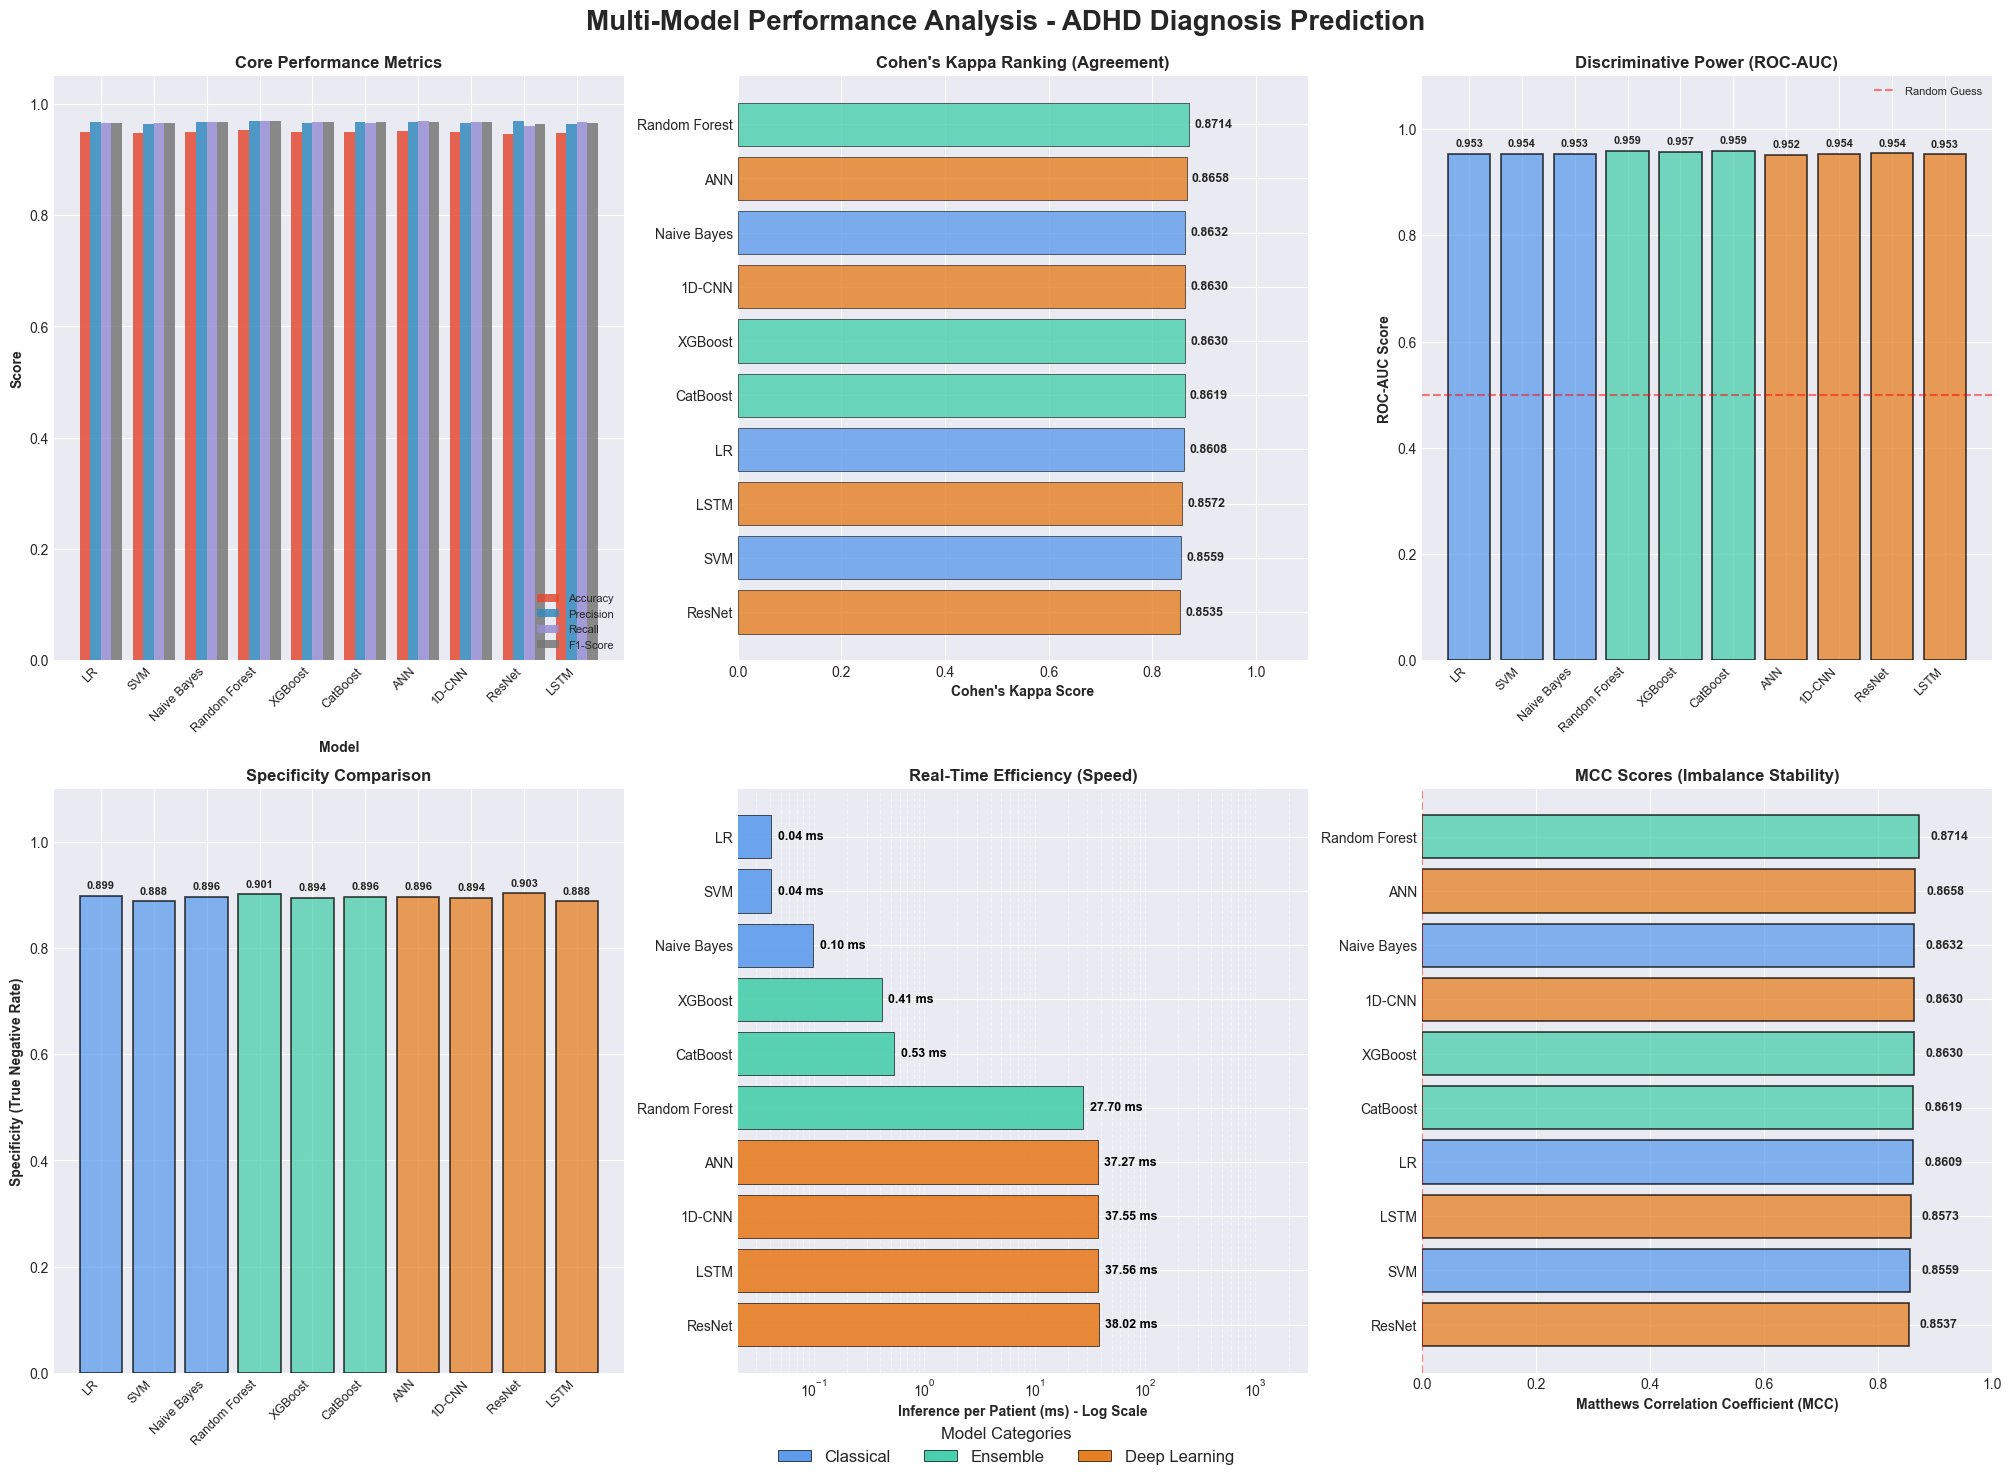

In [32]:
# =============================================================================
# CELL 17: COMPREHENSIVE VISUALIZATION
# =============================================================================
from matplotlib.patches import Patch

# JSON'dan yükle
model_results = load_results()

if model_results:
    rows = []
    for model_name, metrics in model_results.items():
        row = metrics.copy()
        row['Model'] = model_name
        if 'Category' not in row:
            row['Category'] = 'Unknown'
        rows.append(row)
    final_comparison_df = pd.DataFrame(rows)
    rename_map = {'F1_Score': 'F1-Score', 'ROC_AUC': 'ROC-AUC'}
    final_comparison_df.rename(columns=rename_map, inplace=True)
else:
    print("❌ ERROR: No model results found. Train models first.")
    final_comparison_df = pd.DataFrame()

# Construct Timing DataFrame from 'model_time_results'
model_time_results = load_timing()
if model_time_results:
    t_rows = []
    for model_name, times in model_time_results.items():
        # Get category from performance df
        cat = final_comparison_df.loc[final_comparison_df['Model'] == model_name, 'Category'].values
        category = cat[0] if len(cat) > 0 else 'Unknown'
        
        t_rows.append({
            'Model': model_name,
            'Category': category,
            'Inference Time (ms)': times['Latency_ms']
        })
    timing_df = pd.DataFrame(t_rows)
else:
    timing_df = pd.DataFrame()

# 2. PLOTTING
# -----------------------------------------------------------------------------
if not final_comparison_df.empty:
    
    # Style Settings
    plt.close('all')
    plt.style.use('seaborn-v0_8-darkgrid')
    
    # Layout Setup
    fig = plt.figure(figsize=(20, 14), layout='constrained') 

    # Category Colors (Academic Palette)
    category_colors = {
        'Classical': '#5D9CEC',    # Blue
        'Ensemble': '#48CFAD',     # Green
        'Deep Learning': '#E67E22' # Dark Orange
    }

    # =============================================================================
    # 1. MAIN METRICS COMPARISON (Accuracy, Precision, Recall, F1)
    # =============================================================================
    ax1 = plt.subplot(2, 3, 1)
    metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
    
    # Filter only available metrics
    metrics_to_plot = [m for m in metrics_to_plot if m in final_comparison_df.columns]
    
    x = np.arange(len(final_comparison_df))
    width = 0.2

    for i, metric in enumerate(metrics_to_plot):
        vals = final_comparison_df[metric].fillna(0)
        ax1.bar(x + i*width, vals, width, label=metric, alpha=0.85)

    ax1.set_xlabel('Model', fontsize=10, fontweight='bold')
    ax1.set_ylabel('Score', fontsize=10, fontweight='bold')
    ax1.set_title('Core Performance Metrics', fontsize=12, fontweight='bold')
    ax1.set_xticks(x + width * 1.5)
    ax1.set_xticklabels(final_comparison_df['Model'], rotation=45, ha='right', fontsize=9)
    ax1.legend(fontsize=8, loc='lower right')
    ax1.set_ylim([0, 1.05])

    # =============================================================================
    # 2. COHEN'S KAPPA RANKING (Reliability Metric)
    # =============================================================================
    ax2 = plt.subplot(2, 3, 2)
    
    if 'Kappa' in final_comparison_df.columns:
        df_sorted_kappa = final_comparison_df.sort_values('Kappa', ascending=True)
        colors_kappa = [category_colors.get(cat, '#333333') for cat in df_sorted_kappa['Category']]
        
        bars = ax2.barh(df_sorted_kappa['Model'], df_sorted_kappa['Kappa'], 
                        color=colors_kappa, alpha=0.8, edgecolor='black')

        ax2.set_xlabel("Cohen's Kappa Score", fontsize=10, fontweight='bold')
        ax2.set_title("Cohen's Kappa Ranking (Agreement)", fontsize=12, fontweight='bold')
        
        for i, v in enumerate(df_sorted_kappa['Kappa']):
            ax2.text(v + 0.01, i, f'{v:.4f}', va='center', fontsize=9, fontweight='bold')

        ax2.set_xlim([0, 1.1])

    # =============================================================================
    # 3. ROC-AUC COMPARISON
    # =============================================================================
    ax3 = plt.subplot(2, 3, 3)
    
    if 'ROC-AUC' in final_comparison_df.columns:
        model_colors = [category_colors.get(cat, '#333333') for cat in final_comparison_df['Category']]

        bars = ax3.bar(range(len(final_comparison_df)), final_comparison_df['ROC-AUC'], 
                       color=model_colors, alpha=0.75, edgecolor='black', linewidth=1.2)

        ax3.set_xticks(range(len(final_comparison_df)))
        ax3.set_xticklabels(final_comparison_df['Model'], rotation=45, ha='right', fontsize=9)
        ax3.set_ylabel('ROC-AUC Score', fontsize=10, fontweight='bold')
        ax3.set_title('Discriminative Power (ROC-AUC)', fontsize=12, fontweight='bold')
        ax3.axhline(y=0.5, color='red', linestyle='--', alpha=0.5, label='Random Guess')

        for i, (bar, val) in enumerate(zip(bars, final_comparison_df['ROC-AUC'])):
            height = bar.get_height()
            ax3.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                    f'{val:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

        ax3.legend(fontsize=8)
        ax3.set_ylim([0, 1.1])

    # =============================================================================
    # 4. SPECIFICITY COMPARISON (Crucial for Medical Diagnosis)
    # =============================================================================
    ax4 = plt.subplot(2, 3, 4)
    
    if 'Specificity' in final_comparison_df.columns:
        bars = ax4.bar(range(len(final_comparison_df)), final_comparison_df['Specificity'],
                      color=model_colors, alpha=0.75, edgecolor='black', linewidth=1.2)

        ax4.set_xticks(range(len(final_comparison_df)))
        ax4.set_xticklabels(final_comparison_df['Model'], rotation=45, ha='right', fontsize=9)
        ax4.set_ylabel('Specificity (True Negative Rate)', fontsize=10, fontweight='bold')
        ax4.set_title('Specificity Comparison', fontsize=12, fontweight='bold')

        for i, (bar, val) in enumerate(zip(bars, final_comparison_df['Specificity'])):
            height = bar.get_height()
            ax4.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                    f'{val:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

        ax4.set_ylim([0, 1.1])
    
    # =============================================================================
    # 5. DYNAMIC INFERENCE TIME COMPARISON (SPEED / LATENCY)
    # =============================================================================
    ax5 = plt.subplot(2, 3, 5)

    if not timing_df.empty:
        df_viz = timing_df.sort_values('Inference Time (ms)', ascending=True)

        # Map each model to its category color
        bar_colors = [category_colors.get(cat, 'gray') for cat in df_viz['Category']]

        # Bar Plot Drawing (Horizontal)
        bars = ax5.barh(df_viz['Model'], df_viz['Inference Time (ms)'], 
                        color=bar_colors, edgecolor='black', alpha=0.9)

        # Text Labels (ms values)
        for bar in bars:
            width = bar.get_width()
            # Dynamic label positioning for log scale
            label_x_pos = width * 1.15 
            ax5.text(label_x_pos, bar.get_y() + bar.get_height()/2, 
                     f'{width:.2f} ms', 
                     va='center', fontsize=9, fontweight='bold', color='black')

        # Axis Settings
        ax5.set_xscale('log') 
        ax5.set_xlabel('Inference per Patient (ms) - Log Scale', fontsize=10, fontweight='bold')
        ax5.set_title('Real-Time Efficiency (Speed)', fontsize=12, fontweight='bold')

        # Invert axis: fastest at the top
        ax5.invert_yaxis()

        # Grid and Limit settings
        ax5.grid(axis='x', linestyle='--', alpha=0.5, which='both')
        # Room for labels on the right
        min_val = df_viz['Inference Time (ms)'].min()
        ax5.set_xlim([min_val * 0.5 if min_val > 0 else 0.1, 3000]) 
        
    else:
        ax5.text(0.5, 0.5, 'Timing Data Not Found', ha='center', va='center')
        ax5.set_title('Real-Time Efficiency (No Data)')     

    # =============================================================================
    # 6. MCC COMPARISON (Best for Imbalanced Data)
    # =============================================================================
    ax6 = plt.subplot(2, 3, 6)
    
    if 'MCC' in final_comparison_df.columns:
        mcc_sorted = final_comparison_df.sort_values('MCC', ascending=True)
        model_colors_mcc = [category_colors.get(cat, '#333333') for cat in mcc_sorted['Category']]

        bars = ax6.barh(mcc_sorted['Model'], mcc_sorted['MCC'], 
                        color=model_colors_mcc, alpha=0.75, edgecolor='black', linewidth=1.2)

        ax6.set_xlabel('Matthews Correlation Coefficient (MCC)', fontsize=10, fontweight='bold')
        ax6.set_title('MCC Scores (Imbalance Stability)', fontsize=12, fontweight='bold')
        ax6.axvline(x=0, color='red', linestyle='--', alpha=0.5)

        for i, (bar, val) in enumerate(zip(bars, mcc_sorted['MCC'])):
            width = bar.get_width()
            ax6.text(width + 0.02, bar.get_y() + bar.get_height()/2.,
                    f'{val:.4f}', va='center', fontsize=9, fontweight='bold')

        ax6.set_xlim([0, 1.0])

    # =============================================================================
    # FINAL SAVING AND LEGEND
    # =============================================================================
    legend_elements = [Patch(facecolor=category_colors[cat], edgecolor='black', label=cat) 
                      for cat in category_colors.keys()]

    fig.legend(handles=legend_elements, 
              loc='lower center', 
              ncol=3, 
              fontsize=12, 
              title='Model Categories',
              title_fontsize=12,
              bbox_to_anchor=(0.5, -0.02))

    plt.suptitle('Multi-Model Performance Analysis - ADHD Diagnosis Prediction', 
                fontsize=20, fontweight='bold', y=1.03)

    try:
        plt.savefig('ADHD_Comprehensive_Analysis.png', dpi=300, bbox_inches='tight')
        print("\n Report saved successfully as 'ADHD_Comprehensive_Analysis.png'")
    except Exception as e:
        print(f"\n Save Error: {e}")

    plt.show()

✅ Saved: adhd_results/performance_heatmap.png


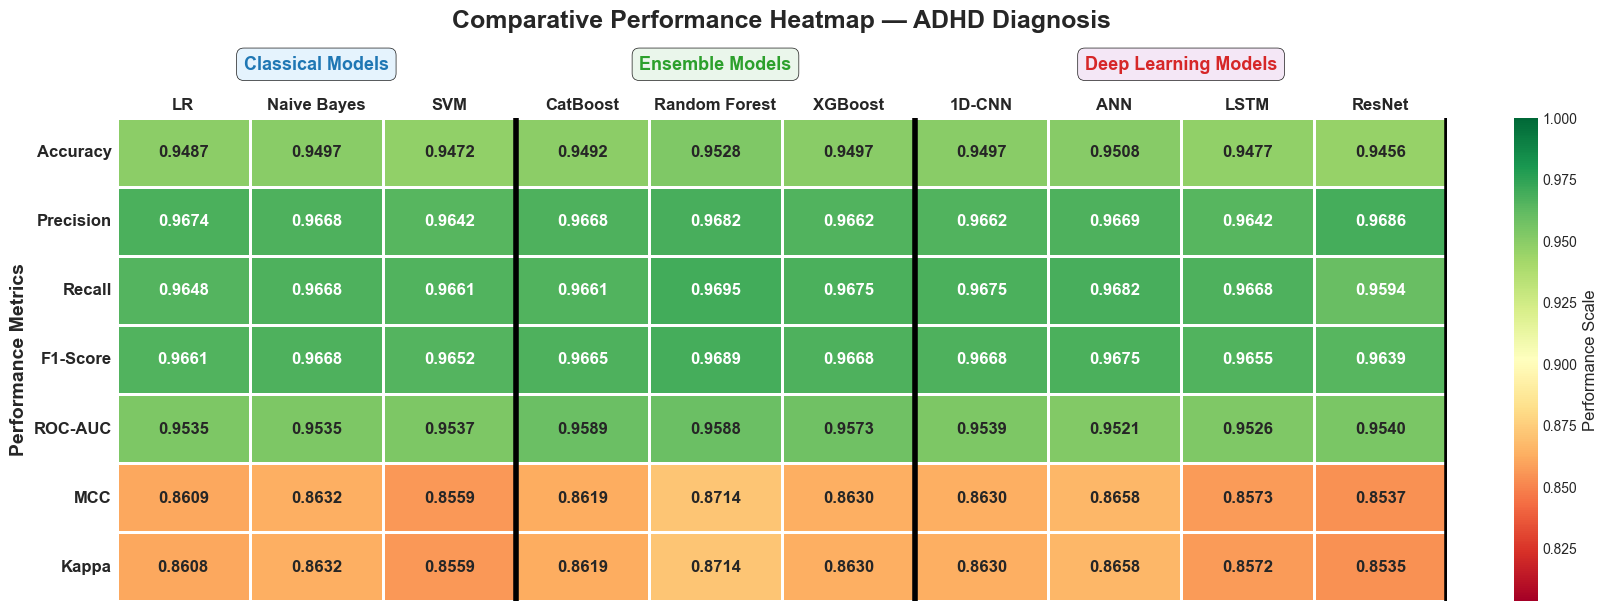

In [34]:
# =============================================================================
# CELL 19: PERFORMANCE HEATMAP — JSON'DAN OKU
# =============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

plt.close('all')

# JSON'dan yükle
model_results = load_results()

if not model_results:
    print("❌ No model results found. Train models first.")
else:
    # Metrikler JSON'da zaten var
    metric_keys = ['Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC', 'MCC', 'Kappa']
    metric_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'MCC', 'Kappa']

    # Kategori sırası
    order = ['Classical', 'Ensemble', 'Deep Learning']
    sorted_models = sorted(
        model_results.keys(),
        key=lambda m: (order.index(model_results[m].get('Category', 'Classical')), m)
    )

    # DataFrame oluştur
    heatmap_data = {}
    for model_name in sorted_models:
        metrics = model_results[model_name]
        heatmap_data[model_name] = [
            float(metrics.get(k, 0)) for k in metric_keys
        ]

    df_heatmap = pd.DataFrame(heatmap_data, index=metric_labels)

    # Kategori sayıları
    cat_counts = {'Classical': 0, 'Ensemble': 0, 'Deep Learning': 0}
    for m in sorted_models:
        cat = model_results[m].get('Category', 'Classical')
        cat_counts[cat] += 1

    # Plot
    fig, ax = plt.subplots(figsize=(16, 6), layout='constrained')

    vmin_set = max(0.5, df_heatmap.min().min() - 0.05)

    sns.heatmap(df_heatmap,
                annot=True, fmt='.4f',
                cmap='RdYlGn',
                linewidths=2, linecolor='white',
                annot_kws={'size': 12, 'weight': 'bold'},
                cbar_kws={'label': 'Performance Scale'},
                vmin=vmin_set, vmax=1.0,
                ax=ax)

    # Kategori separatörleri
    current_idx = 0
    for cat, color, bg in [
        ('Classical',     '#1f77b4', '#E3F2FD'),
        ('Ensemble',      '#2ca02c', '#E8F5E9'),
        ('Deep Learning', '#d62728', '#F3E5F5')
    ]:
        n = cat_counts[cat]
        if n > 0:
            ax.axvline(x=current_idx + n, color='black', linewidth=4)
            ax.text(current_idx + n/2, -0.7, f'{cat} Models',
                    ha='center', fontsize=13, weight='bold', color=color,
                    bbox=dict(boxstyle='round,pad=0.4', facecolor=bg,
                              alpha=0.9, edgecolor='black'))
            current_idx += n

    plt.title('Comparative Performance Heatmap — ADHD Diagnosis',
              fontsize=18, pad=65, weight='bold')
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position('top')
    plt.ylabel('Performance Metrics', fontsize=14, weight='bold')
    plt.xticks(rotation=0, ha='center', fontsize=12, weight='bold')
    plt.yticks(rotation=0, fontsize=12, weight='bold')

    plt.savefig('adhd_results/performance_heatmap.png',
                dpi=300, bbox_inches='tight')
    print("✅ Saved: adhd_results/performance_heatmap.png")
    plt.show()


✅ Saved: adhd_results/all_confusion_matrices.png


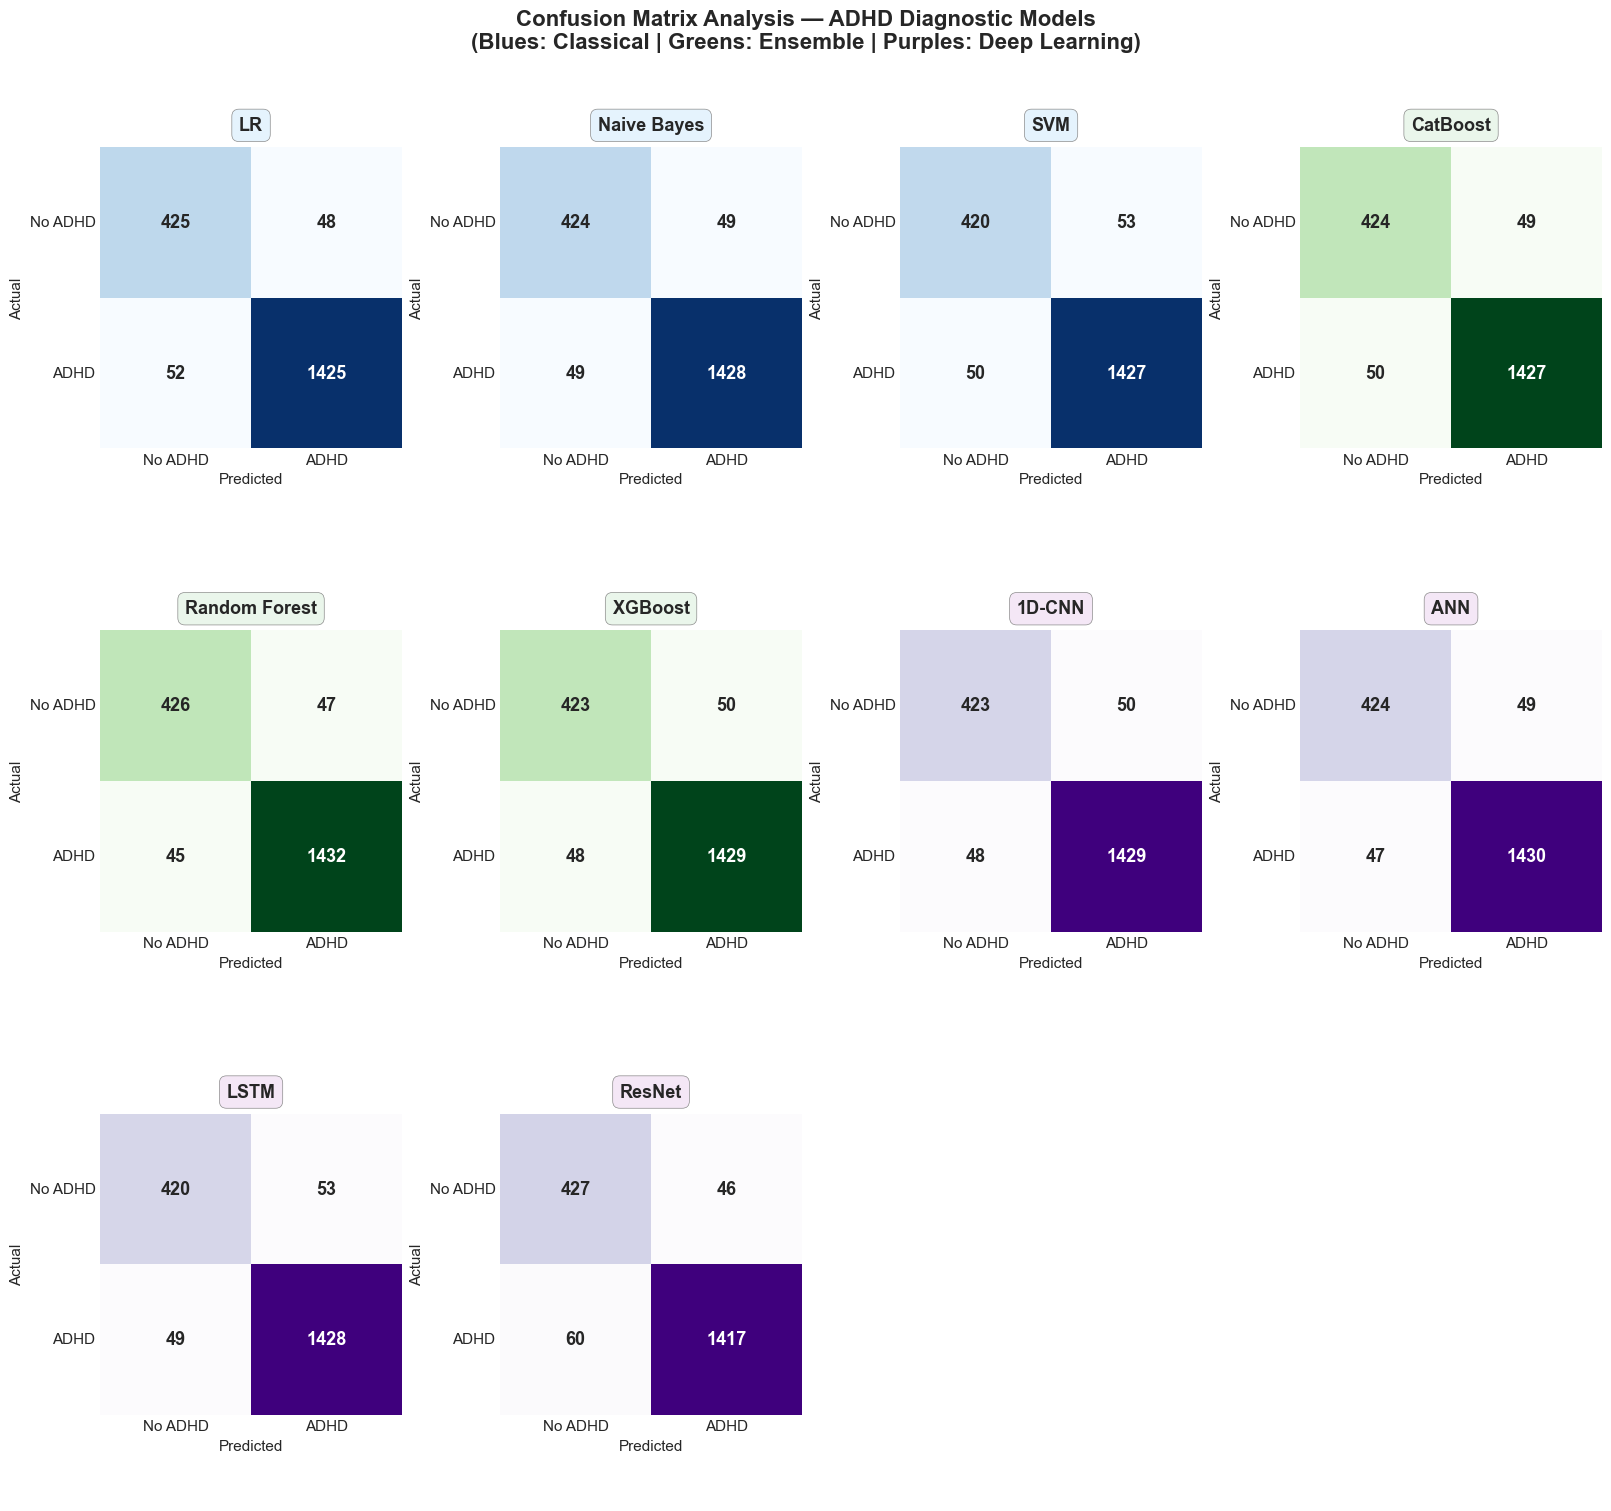

In [33]:
# =============================================================================
# CELL 18: ALL CONFUSION MATRICES - JSON'DAN OKU
# =============================================================================
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from pathlib import Path

plt.close('all')

# JSON'dan yükle
model_results = load_results()

if not model_results:
    print("❌ ERROR: No model results found in JSON. Train models first.")
else:
    # Confusion matrix JSON'da saklanıyor mu kontrol et
    # Yoksa y_test_pred_all dosyasından okuyacağız
    
    # Her model için predictions JSON'da var mı?
    CM_PATH = Path('adhd_results/confusion_matrices.json')
    
    if CM_PATH.exists():
        with open(CM_PATH, 'r') as f:
            cm_data = json.load(f)
    else:
        print("⚠️ confusion_matrices.json not found.")
        print("   Running with available data from model_results...")
        cm_data = {}
        for model_name, metrics in model_results.items():
            if 'TP' in metrics and 'TN' in metrics:
                tp = metrics['TP']
                tn = metrics['TN']
                fp = metrics['FP']
                fn = metrics['FN']
                cm_data[model_name] = [[tn, fp], [fn, tp]]

    # Category mapping
    category_map = {m: model_results[m].get('Category', 'Classical') 
                    for m in model_results}

    category_colors = {
        'Classical':     'Blues',
        'Ensemble':      'Greens',
        'Deep Learning': 'Purples'
    }
    background_colors = {
        'Classical':     '#E3F2FD',
        'Ensemble':      '#E8F5E9',
        'Deep Learning': '#F3E5F5'
    }

    # Sıralama: Classical → Ensemble → Deep Learning
    order = ['Classical', 'Ensemble', 'Deep Learning']
    sorted_models = sorted(
        cm_data.keys(),
        key=lambda m: (order.index(category_map.get(m, 'Classical')), m)
    )

    num_models = len(sorted_models)
    cols = 4
    rows = (num_models + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(16, 5 * rows), layout='constrained')
    axes = axes.ravel()

    for idx, model_name in enumerate(sorted_models):
        category = category_map.get(model_name, 'Classical')
        cm = np.array(cm_data[model_name])

        sns.heatmap(cm, annot=True, fmt='d',
                    cmap=category_colors[category],
                    ax=axes[idx], cbar=False, square=True,
                    annot_kws={'size': 13, 'weight': 'bold'})

        axes[idx].set_title(
            model_name, fontsize=13, fontweight='bold', pad=12,
            bbox=dict(boxstyle='round,pad=0.4',
                      facecolor=background_colors[category],
                      edgecolor='gray', alpha=0.9)
        )
        axes[idx].set_xlabel('Predicted', fontsize=11)
        axes[idx].set_ylabel('Actual', fontsize=11)
        axes[idx].set_xticklabels(['No ADHD', 'ADHD'], fontsize=11)
        axes[idx].set_yticklabels(['No ADHD', 'ADHD'], fontsize=11, rotation=0)

    # Boş subplotları gizle
    for i in range(num_models, len(axes)):
        axes[i].axis('off')

    plt.suptitle(
        'Confusion Matrix Analysis — ADHD Diagnostic Models\n'
        '(Blues: Classical | Greens: Ensemble | Purples: Deep Learning)',
        fontsize=16, fontweight='bold'
    )

    plt.savefig('adhd_results/all_confusion_matrices.png',
                dpi=300, bbox_inches='tight')
    print(f"\n✅ Saved: adhd_results/all_confusion_matrices.png")
    plt.show()


 MODEL EFFICIENCY & COMPUTATIONAL COST ANALYSIS - ADHD PROJECT

Tablo 5. Algoritmaların Detaylı Zaman Maliyeti Analizi

        Model      Category  CV & Tuning Time (s)  Final Training Time (s)  Total Dev. Time (s)  Inference Time (ms)
           LR     Classical                3.4199                   0.0132               3.5128               0.0409
          SVM     Classical               21.4518                   9.4881              31.0469               0.0549
  Naive Bayes     Classical                0.2382                   0.0008               0.4303               0.0981
      XGBoost      Ensemble                2.3919                   0.0451               3.2378               0.4106
     CatBoost      Ensemble               10.9782                   0.4071              12.4235               0.5324
Random Forest      Ensemble                4.5626                   0.3016              58.8695              27.6950
          ANN Deep Learning               10.2043           

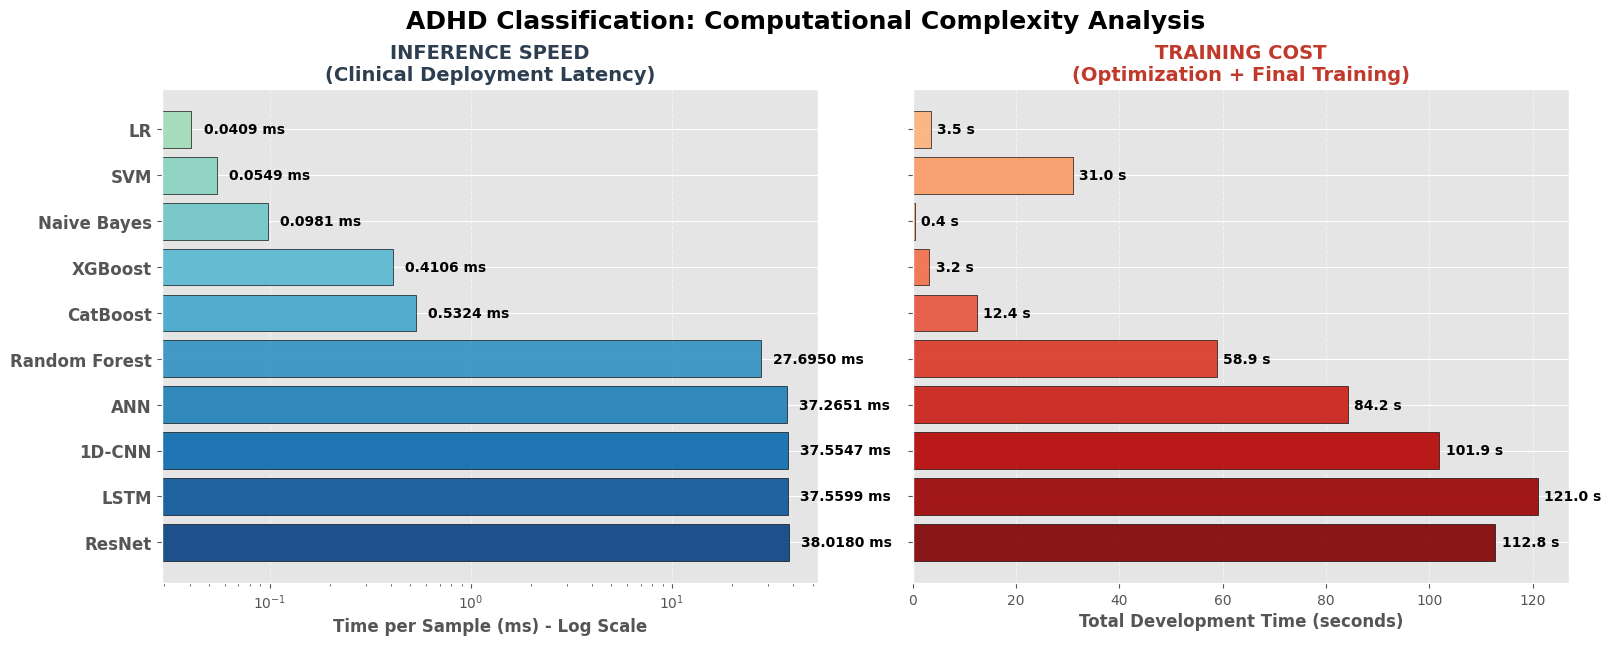

In [7]:
# =============================================================================
# CELL 20: COMPREHENSIVE TIMING ANALYSIS
# =============================================================================
print("\n" + "=" * 115)
print(" MODEL EFFICIENCY & COMPUTATIONAL COST ANALYSIS - ADHD PROJECT")
print("=" * 115)

# JSON'dan yükle
model_time_results = load_timing()

model_categories = {
    'LR': 'Classical', 'Naive Bayes': 'Classical', 'SVM': 'Classical',
    'Random Forest': 'Ensemble', 'XGBoost': 'Ensemble', 'CatBoost': 'Ensemble',
    'ANN': 'Deep Learning', '1D-CNN': 'Deep Learning',
    'ResNet': 'Deep Learning', 'LSTM': 'Deep Learning'
}

if model_time_results:
    timing_data = []
    for model_name, results in model_time_results.items():
        # Handle model naming differences (e.g. 'Logistic Regression' vs 'LR')
        category = model_categories.get(model_name, 'Unknown')
        
        # Extract data from the new structure
        cv_tuning = results.get('CV_Time', 0)
        final_train = results.get('Training_Time', 0)
        total_dev = results.get('Total_Time', 0)
        inf_speed = results.get('Latency_ms', 0) # Using Latency per sample (ms)
        
        timing_data.append({
            'Model': model_name,
            'Category': category,
            'CV & Tuning Time (s)': cv_tuning,
            'Final Training Time (s)': final_train,
            'Total Dev. Time (s)': total_dev,
            'Inference Time (ms)': inf_speed
        })

    timing_df = pd.DataFrame(timing_data)
    
    # Sorting: Inference Time (ms) - Fastest to Slowest
    timing_df = timing_df.sort_values('Inference Time (ms)', ascending=True).reset_index(drop=True)

    # Print Table in Academic Format
    print("\nTablo 5. Algoritmaların Detaylı Zaman Maliyeti Analizi\n")
    print(timing_df.round(4).to_string(index=False))

    # -------------------------------------------------------------------------
    # STATISTICAL SUMMARY
    # -------------------------------------------------------------------------
    print("\n" + "-" * 115)
    print(" EFFICIENCY SUMMARY")
    if not timing_df.empty:
        fastest_inf = timing_df.iloc[0]
        slowest_inf = timing_df.iloc[-1]
        print(f"🚀 Most Efficient (Inference): {fastest_inf['Model']} ({fastest_inf['Inference Time (ms)']:.4f} ms)")
        print(f"🐢 Least Efficient (Inference): {slowest_inf['Model']} ({slowest_inf['Inference Time (ms)']:.4f} ms)")
    print("-" * 115)

    # -------------------------------------------------------------------------
    # VISUALIZATION (1 IMAGE, 2 COLUMNS)
    # -------------------------------------------------------------------------
    plt.close('all') 
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), layout='constrained')
    
    models = timing_df['Model'].values
    y_pos = np.arange(len(models))
    
    # --- LEFT PLOT: INFERENCE TIME (Log Scale) ---
    inf_times = timing_df['Inference Time (ms)'].values
    colors_inf = plt.cm.GnBu(np.linspace(0.4, 1, len(models)))
    
    axes[0].barh(y_pos, inf_times, color=colors_inf, edgecolor='black', alpha=0.9)
    axes[0].set_yticks(y_pos)
    axes[0].set_yticklabels(models, fontsize=12, fontweight='bold')
    axes[0].invert_yaxis() 
    axes[0].set_xlabel('Time per Sample (ms) - Log Scale', fontsize=12, fontweight='bold')
    axes[0].set_title('INFERENCE SPEED\n(Clinical Deployment Latency)', fontsize=14, fontweight='bold', color='#2c3e50')
    axes[0].set_xscale('log') 
    axes[0].grid(axis='x', linestyle='--', alpha=0.5)
    
    for i, v in enumerate(inf_times):
        # Dynamic label positioning for log scale
        axes[0].text(v * 1.15, i, f"{v:.4f} ms", va='center', fontweight='bold', fontsize=10)

    # --- RIGHT PLOT: TOTAL DEVELOPMENT TIME (Linear Scale) ---
    train_times = timing_df['Total Dev. Time (s)'].values
    colors_train = plt.cm.OrRd(np.linspace(0.4, 1, len(models)))
    
    axes[1].barh(y_pos, train_times, color=colors_train, edgecolor='black', alpha=0.9)
    axes[1].set_yticks(y_pos)
    axes[1].set_yticklabels([]) # Hidden as it shares y-axis
    axes[1].invert_yaxis()
    axes[1].set_xlabel('Total Development Time (seconds)', fontsize=12, fontweight='bold')
    axes[1].set_title('TRAINING COST\n(Optimization + Final Training)', fontsize=14, fontweight='bold', color='#c0392b')
    axes[1].grid(axis='x', linestyle='--', alpha=0.5)
    
    for i, v in enumerate(train_times):
        axes[1].text(v + (max(train_times)*0.01), i, f"{v:.1f} s", va='center', fontweight='bold', fontsize=10)

    plt.suptitle('ADHD Classification: Computational Complexity Analysis', fontsize=18, fontweight='bold', y=1.05)
    
    try:
        plt.savefig('adhd_detailed_timing_analysis.png', dpi=300, bbox_inches='tight')
        print("\n Visualization saved as 'adhd_detailed_timing_analysis.png'")
    except Exception as e:
        print(f"\n Save failed: {e}")

    plt.show()

    # -------------------------------------------------------------------------
    # EXPORTS
    # -------------------------------------------------------------------------
    timing_df.to_csv('adhd_detailed_timing_report.csv', index=False)

else:
    print(" 'model_time_results' dictionary not found. Please run individual model cells first.")


OVERFITTING ANALYSIS (GENERALIZATION GAP ASSESSMENT)

Rank  Model                Category        Train Acc    Test Acc     Gap        Status    
------------------------------------------------------------------------------------------
1     LR                   Classical       0.9558       0.9487       0.0071     ✅ Optimal
2     Naive Bayes          Classical       0.9523       0.9497       0.0026     ✅ Optimal
3     SVM                  Classical       0.9565       0.9472       0.0093     ✅ Optimal
4     CatBoost             Ensemble        0.9875       0.9492       0.0382     ✅ Optimal
5     Random Forest        Ensemble        0.9712       0.9528       0.0184     ✅ Optimal
6     XGBoost              Ensemble        0.9736       0.9497       0.0239     ✅ Optimal
7     1D-CNN               Deep Learning   0.9587       0.9497       0.0089     ✅ Optimal
8     ANN                  Deep Learning   0.9615       0.9508       0.0108     ✅ Optimal
9     LSTM                 Deep Learning   

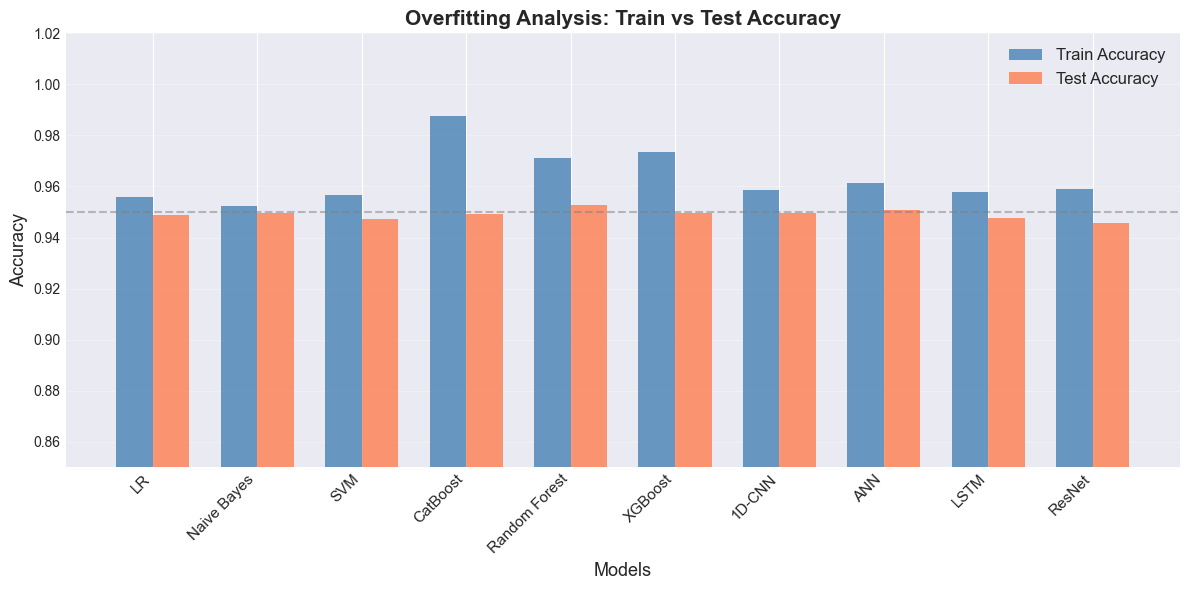


All 10 models analyzed. Max gap: 0.0382 (CatBoost)


In [36]:
# =============================================================================
# CELL 21: OVERFITTING ANALYSIS — JSON'DAN OKU
# =============================================================================
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

print("\n" + "=" * 100)
print("OVERFITTING ANALYSIS (GENERALIZATION GAP ASSESSMENT)")
print("=" * 100)

# JSON'dan yükle
model_results = load_results()

if not model_results:
    print("❌ No model results found. Train models first.")
else:
    order = ['Classical', 'Ensemble', 'Deep Learning']
    sorted_models = sorted(
        model_results.keys(),
        key=lambda m: (order.index(model_results[m].get('Category', 'Classical')), m)
    )

    print(f"\n{'Rank':<5} {'Model':<20} {'Category':<15} "
          f"{'Train Acc':<12} {'Test Acc':<12} {'Gap':<10} {'Status':<10}")
    print("-" * 90)

    rows = []
    for rank, model_name in enumerate(sorted_models, 1):
        m = model_results[model_name]
        train_acc = float(m.get('Train_Accuracy', 0))
        test_acc  = float(m.get('Accuracy', 0))
        gap       = train_acc - test_acc
        category  = m.get('Category', '-')
        status    = '✅ Optimal' if gap < 0.05 else '⚠️ Overfit'

        print(f"{rank:<5} {model_name:<20} {category:<15} "
              f"{train_acc:<12.4f} {test_acc:<12.4f} {gap:<10.4f} {status}")

        rows.append({
            'Model': model_name, 'Category': category,
            'Train_Acc': train_acc, 'Test_Acc': test_acc,
            'Gap': gap, 'Status': status
        })

    df_gap = pd.DataFrame(rows)

    # Plot
    fig, ax = plt.subplots(figsize=(12, 6))
    x = np.arange(len(df_gap))
    width = 0.35

    bars1 = ax.bar(x - width/2, df_gap['Train_Acc'], width,
                   label='Train Accuracy', color='steelblue', alpha=0.8)
    bars2 = ax.bar(x + width/2, df_gap['Test_Acc'], width,
                   label='Test Accuracy', color='coral', alpha=0.8)

    ax.set_xlabel('Models', fontsize=13)
    ax.set_ylabel('Accuracy', fontsize=13)
    ax.set_title('Overfitting Analysis: Train vs Test Accuracy', fontsize=15, weight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(df_gap['Model'], rotation=45, ha='right', fontsize=11)
    ax.set_ylim(0.85, 1.02)
    ax.legend(fontsize=12)
    ax.axhline(y=0.95, color='gray', linestyle='--', alpha=0.5, label='0.95 line')
    ax.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.savefig('adhd_results/overfitting_analysis.png', dpi=300, bbox_inches='tight')
    print("\n✅ Saved: adhd_results/overfitting_analysis.png")
    plt.show()

    print("\n" + "=" * 100)
    print(f"All {len(df_gap)} models analyzed. "
          f"Max gap: {df_gap['Gap'].max():.4f} ({df_gap.loc[df_gap['Gap'].idxmax(), 'Model']})")


FEATURE IMPORTANCE ANALYSIS (RF & XGBoost)
✅ Saved: adhd_results/feature_importance_plot.png


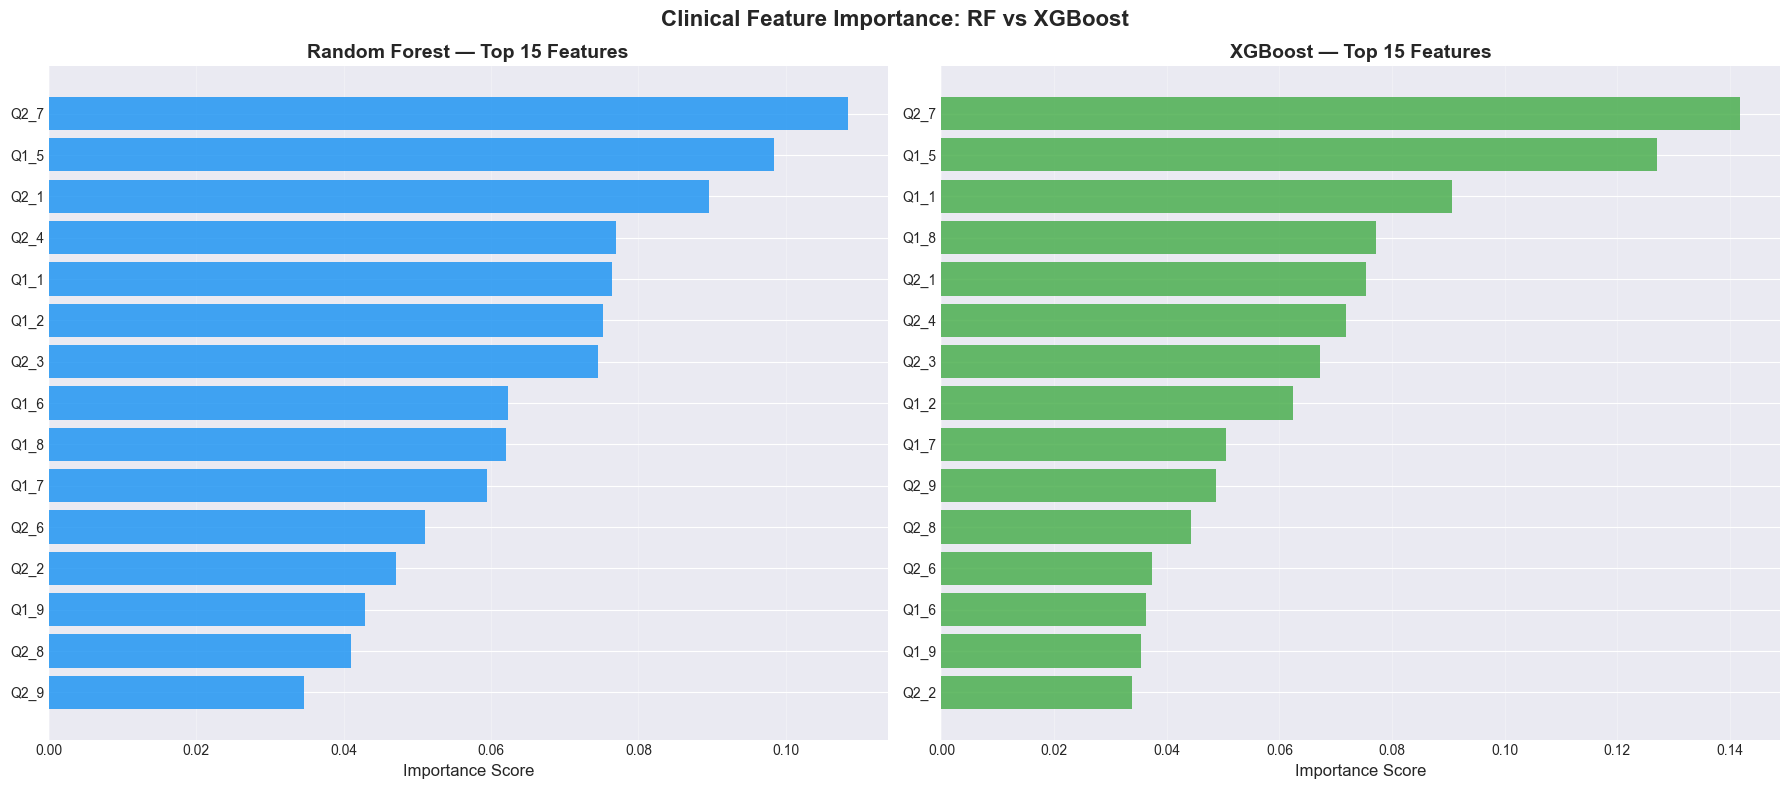

In [37]:
# =============================================================================
# CELL 22: FEATURE IMPORTANCE — JSON'DAN OKU
# =============================================================================
import json
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

print("\n" + "=" * 80)
print("FEATURE IMPORTANCE ANALYSIS (RF & XGBoost)")
print("=" * 80)

FI_PATH = Path('adhd_results/feature_importance.json')

if not FI_PATH.exists():
    print("⚠️ feature_importance.json not found.")
    print("   Feature importance is saved during model training.")
    print("   Please ensure RF and XGBoost cells save feature importance.")
else:
    with open(FI_PATH, 'r') as f:
        fi_data = json.load(f)

    feature_names   = fi_data.get('feature_names', [])
    rf_importance   = np.array(fi_data.get('Random Forest', []))
    xgb_importance  = np.array(fi_data.get('XGBoost', []))

    if len(feature_names) == 0:
        print("❌ No feature names found in feature_importance.json")
    else:
        # Top 15 RF features
        top_idx = np.argsort(rf_importance)[::-1][:15]

        fig, axes = plt.subplots(1, 2, figsize=(18, 8))

        for ax, importance, title, color in zip(
            axes,
            [rf_importance[top_idx], xgb_importance[top_idx]],
            ['Random Forest', 'XGBoost'],
            ['#2196F3', '#4CAF50']
        ):
            sorted_idx = np.argsort(importance)
            ax.barh([feature_names[i] for i in top_idx[sorted_idx]],
                    importance[sorted_idx], color=color, alpha=0.85)
            ax.set_title(f'{title} — Top 15 Features',
                         fontsize=14, weight='bold')
            ax.set_xlabel('Importance Score', fontsize=12)
            ax.grid(axis='x', alpha=0.3)

        plt.suptitle('Clinical Feature Importance: RF vs XGBoost',
                     fontsize=16, weight='bold')
        plt.tight_layout()
        plt.savefig('adhd_results/feature_importance_plot.png',
                    dpi=300, bbox_inches='tight')
        print("✅ Saved: adhd_results/feature_importance_plot.png")
        plt.show()

In [38]:
# Load fold scores from JSON
fold_scores = load_folds()

if not fold_scores:
    print('⚠️ No fold scores found. Make sure models saved fold data.')
else:
    print(f'✅ Loaded fold scores for {len(fold_scores)} models\n')
    
# ============================================================
# CELL 23: STATISTICAL SIGNIFICANCE ANALYSIS
# Uses REAL per-fold CV scores stored in 'fold_scores' dict.
# If fold_scores is not available, falls back to bootstrap-
# resampled scores from test set predictions.
# ============================================================

import scipy.stats as stats

print('\n' + '=' * 80)
print('STATISTICAL SIGNIFICANCE ANALYSIS')
print('=' * 80)

# --- Build per-model score arrays ---
# Priority: real fold_scores > bootstrap from test predictions
stats_data = {}  # {model_name: array of 5 MCC scores}

if 'fold_scores' in globals() and fold_scores:
    print('\n  Using REAL 5-fold CV scores from fold_scores dict.')
    for model_name, scores_dict in fold_scores.items():
        mcc_list = scores_dict.get('MCC', [])
        if len(mcc_list) >= 2:
            stats_data[model_name] = np.array(mcc_list)
            print(f'  {model_name:<20}: MCC folds = {np.round(mcc_list, 4)}')
        else:
            print(f'  {model_name:<20}: insufficient fold data, skipping')
else:
    print('\n  fold_scores not found — using bootstrap from model_results.')
    model_results = load_results()
    rng = np.random.default_rng(42)
    for model_name, metrics in model_results.items():
        tp = int(metrics.get('TP', 0))
        tn = int(metrics.get('TN', 0))
        fp = int(metrics.get('FP', 0))
        fn = int(metrics.get('FN', 0))
        n  = tp + tn + fp + fn
        if n == 0:
            continue
        y_true_boot = np.array([1]*tp + [0]*tn + [0]*fp + [1]*fn)
        y_pred_boot = np.array([1]*tp + [0]*tn + [1]*fp + [0]*fn)
        boot_scores = []
        for _ in range(10):
            idx = rng.choice(n, n, replace=True)
            try:
                score = matthews_corrcoef(y_true_boot[idx], y_pred_boot[idx])
            except Exception:
                score = 0.0
            boot_scores.append(score)
        stats_data[model_name] = np.array(boot_scores)
        print(f'  {model_name:<20}: Bootstrap MCC = {np.round(stats_data[model_name], 4)}')


if not stats_data:
    print('\n  No score data available. Please run model training cells first.')
else:
    df_stats = {k: v for k, v in stats_data.items() if len(v) >= 2}

    # --- 1. FRIEDMAN TEST ---
    print('\n' + '-' * 80)
    print('1. FRIEDMAN TEST (Global Comparison)')
    print('-' * 80)
    arrays = list(df_stats.values())
    min_len = min(len(a) for a in arrays)
    arrays_eq = [a[:min_len] for a in arrays]
    stat_f, p_friedman = stats.friedmanchisquare(*arrays_eq)
    print(f'  Chi2 statistic : {stat_f:.4f}')
    print(f'  p-value        : {p_friedman:.4e}')
    significant = p_friedman < 0.05
    print(f'  Result: {"SIGNIFICANT ✅" if significant else "NOT SIGNIFICANT"} (alpha=0.05)')

    # --- 2. WILCOXON PAIRWISE ---
    print('\n' + '-' * 80)
    print('2. WILCOXON SIGNED-RANK TEST (Pairwise)')
    print('-' * 80)
    model_names = list(df_stats.keys())
    p_matrix = np.ones((len(model_names), len(model_names)))
    for i in range(len(model_names)):
        for j in range(i + 1, len(model_names)):
            a = df_stats[model_names[i]][:min_len]
            b = df_stats[model_names[j]][:min_len]
            try:
                _, p = stats.wilcoxon(a, b)
                p_matrix[i, j] = p_matrix[j, i] = p
            except Exception:
                pass
            sig = '✅' if p_matrix[i, j] < 0.05 else '  '
            print(f'  {sig} {model_names[i]:20s} vs {model_names[j]:20s}: p={p_matrix[i,j]:.4f}')

    import pandas as _pd
    wilcoxon_df = _pd.DataFrame(p_matrix, index=model_names, columns=model_names)
    wilcoxon_df.to_csv(OUTPUT_DIR / 'wilcoxon_pairwise_mcc.csv')

    # --- 3. DUNN POST-HOC (if Friedman significant) ---
    if significant and POSTHOCS_AVAILABLE:
        print('\n' + '-' * 80)
        print('3. DUNN POST-HOC TEST (Bonferroni correction)')
        print('-' * 80)
        data_flat, groups = [], []
        for name, scores in df_stats.items():
            data_flat.extend(scores[:min_len].tolist())
            groups.extend([name] * min_len)
        df_dunn_input = _pd.DataFrame({'score': data_flat, 'group': groups})
        try:
            dunn_result = sp.posthoc_dunn(
                df_dunn_input, val_col='score', group_col='group', p_adjust='bonferroni')
            print(dunn_result.round(4).to_string())
            dunn_result.to_csv(OUTPUT_DIR / 'dunn_posthoc_mcc.csv')
        except Exception as e:
            print(f'  Dunn test error: {e}')
    elif significant and not POSTHOCS_AVAILABLE:
        print('\n  Install scikit-posthocs for Dunn test: pip install scikit-posthocs')

    # --- Summary ---
    means = {k: np.mean(v) for k, v in df_stats.items()}
    best  = max(means, key=means.get)
    print(f'\n  Best Model (MCC): {best} (Mean MCC = {means[best]:.4f})')
    print(f'  Statistical tests saved to: {OUTPUT_DIR}')
    print('=' * 80)


✅ Loaded fold scores for 10 models


STATISTICAL SIGNIFICANCE ANALYSIS

  Using REAL 5-fold CV scores from fold_scores dict.
  LR                  : MCC folds = [0.8641 0.8837 0.8944 0.8882 0.8611]
  SVM                 : MCC folds = [0.8695 0.8865 0.8975 0.8822 0.8611]
  Naive Bayes         : MCC folds = [0.8665 0.8833 0.8893 0.8859 0.8493]
  Random Forest       : MCC folds = [0.8951 0.9032 0.9135 0.9132 0.8833]
  XGBoost             : MCC folds = [0.8775 0.8969 0.8852 0.8945 0.8833]
  CatBoost            : MCC folds = [0.8925 0.9059 0.9104 0.9068 0.883 ]
  ANN                 : MCC folds = [0.8957 0.9032 0.9195 0.9192 0.889 ]
  1D-CNN              : MCC folds = [0.8834 0.8845 0.8953 0.8916 0.8781]
  ResNet              : MCC folds = [0.8904 0.8734 0.9075 0.9041 0.8586]
  LSTM                : MCC folds = [0.8755 0.867  0.8984 0.825  0.7674]

--------------------------------------------------------------------------------
1. FRIEDMAN TEST (Global Comparison)
--------------------------

## Bootstrap 95% Confidence Intervals — All Models

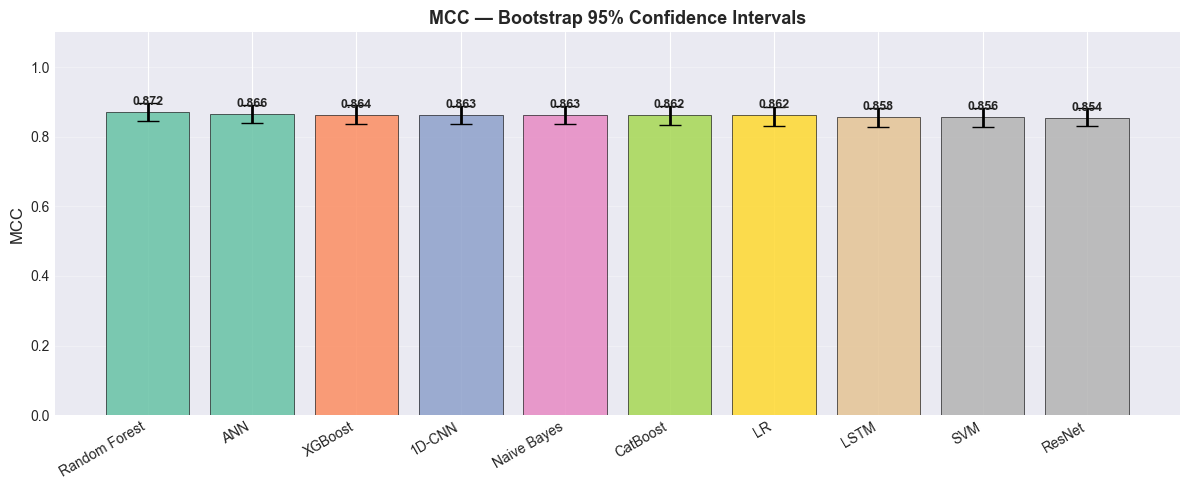

Saved: adhd_results\bootstrap_ci_mcc.png


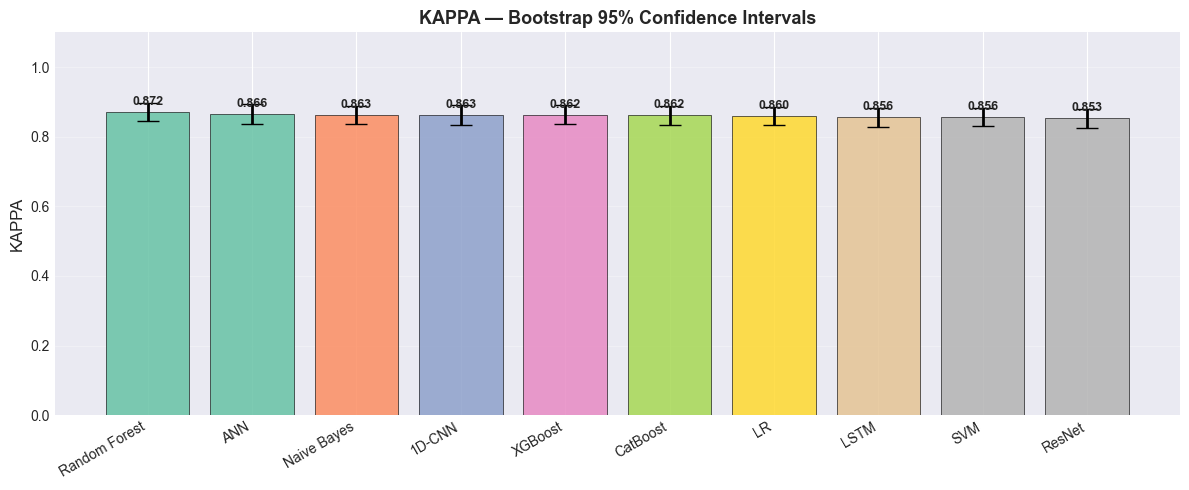

Saved: adhd_results\bootstrap_ci_kappa.png
        Model   Metric     Mean  CI_Lower  CI_Upper
       1D-CNN      MCC 0.862861  0.837511  0.889600
       1D-CNN    KAPPA 0.862692  0.834837  0.889891
       1D-CNN  ROC_AUC 0.953849  0.939503  0.966523
       1D-CNN       F1 0.966716  0.960159  0.972921
       1D-CNN ACCURACY 0.949568  0.938974  0.958462
          ANN      MCC 0.866253  0.840075  0.891488
          ANN    KAPPA 0.865616  0.836709  0.893071
          ANN  ROC_AUC 0.951741  0.936971  0.965518
          ANN       F1 0.967325  0.961047  0.973423
          ANN ACCURACY 0.950764  0.941026  0.960000
     CatBoost      MCC 0.861856  0.833441  0.887946
     CatBoost    KAPPA 0.861722  0.833079  0.887841
     CatBoost  ROC_AUC 0.959074  0.947145  0.970128
     CatBoost       F1 0.966424  0.959533  0.972847
     CatBoost ACCURACY 0.949249  0.938962  0.958462
           LR      MCC 0.861511  0.831852  0.885957
           LR    KAPPA 0.860434  0.833458  0.885539
           LR  ROC_AU

In [39]:
# ============================================================
# BOOTSTRAP 95% CONFIDENCE INTERVALS — ALL MODELS
# ============================================================

from pathlib import Path
import glob

ci_files = list(OUTPUT_DIR.glob('bootstrap_ci_*.csv'))

if not ci_files:
    print('No bootstrap CI files found. Run individual model cells first.')
else:
    all_ci = pd.concat([pd.read_csv(f) for f in ci_files], ignore_index=True)
    all_ci.to_csv(OUTPUT_DIR / 'bootstrap_ci_all_models.csv', index=False)

    # Plot MCC and Kappa CIs
    for metric in ['MCC', 'KAPPA']:
        sub = all_ci[all_ci['Metric'] == metric].copy()
        if sub.empty:
            continue
        sub = sub.sort_values('Mean', ascending=False)
        fig, ax = plt.subplots(figsize=(12, 5))
        colors = plt.cm.Set2(np.linspace(0, 1, len(sub)))
        yerr = [
            sub['Mean'].values - sub['CI_Lower'].values,
            sub['CI_Upper'].values - sub['Mean'].values
        ]
        bars = ax.bar(sub['Model'], sub['Mean'], color=colors,
                      yerr=yerr, capsize=8, error_kw={'linewidth': 2},
                      edgecolor='black', alpha=0.85)
        ax.set_ylim(0, 1.1)
        ax.set_title(f'{metric} — Bootstrap 95% Confidence Intervals',
                     fontsize=13, fontweight='bold')
        ax.set_ylabel(metric); ax.grid(axis='y', alpha=0.3)
        plt.xticks(rotation=30, ha='right')
        for bar, val in zip(bars, sub['Mean'].values):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                    f'{val:.3f}', ha='center', fontsize=9, fontweight='bold')
        plt.tight_layout()
        save_path = OUTPUT_DIR / f'bootstrap_ci_{metric.lower()}.png'
        plt.savefig(save_path, dpi=200, bbox_inches='tight')
        plt.show(); plt.close()
        print(f'Saved: {save_path}')

    print(all_ci.to_string(index=False))


## Performance vs Efficiency Trade-off Scatter

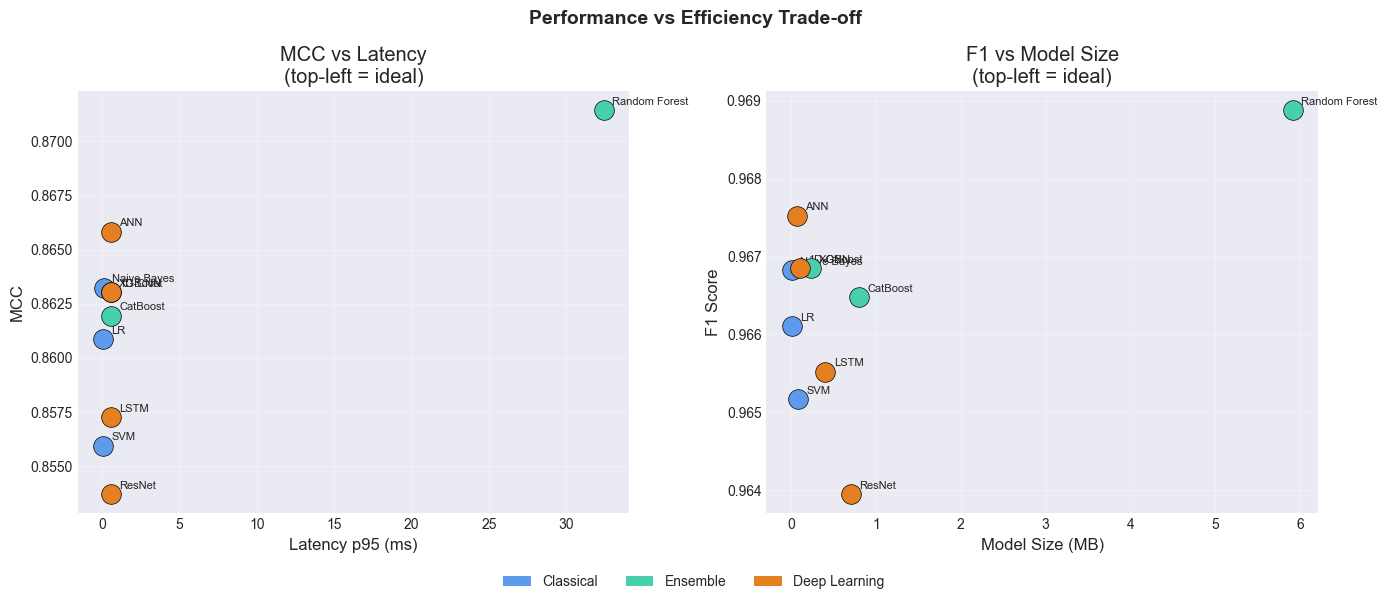

Saved: adhd_results\tradeoff_scatter.png


In [40]:
# ============================================================
# TRADE-OFF SCATTER: MCC vs Latency, F1 vs Model Size
# ============================================================

if model_results and model_time_results:
    models_list  = list(model_results.keys())
    mcc_vals     = [model_results[m]['MCC']          for m in models_list]
    f1_vals      = [model_results[m]['F1_Score']     for m in models_list]
    size_vals    = [model_results[m]['Model_Size_MB'] for m in models_list]
    lat_vals     = [model_time_results[m].get('p95_ms', model_time_results[m].get('Latency_ms', 0))
                    for m in models_list]
    cat_colors   = {'Classical': '#5D9CEC', 'Ensemble': '#48CFAD', 'Deep Learning': '#E67E22'}
    point_colors = [cat_colors.get(model_results[m].get('Category', 'Unknown'), 'gray')
                    for m in models_list]

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle('Performance vs Efficiency Trade-off', fontsize=14, fontweight='bold')

    # MCC vs Latency
    for name, mcc, lat, color in zip(models_list, mcc_vals, lat_vals, point_colors):
        axes[0].scatter(lat, mcc, s=200, color=color, zorder=5, edgecolors='black')
        axes[0].annotate(name, (lat, mcc), textcoords='offset points', xytext=(6, 4), fontsize=8)
    axes[0].set(xlabel='Latency p95 (ms)', ylabel='MCC', title='MCC vs Latency\n(top-left = ideal)')
    axes[0].grid(alpha=0.3)

    # F1 vs Model Size
    for name, f1, sz, color in zip(models_list, f1_vals, size_vals, point_colors):
        axes[1].scatter(sz, f1, s=200, color=color, zorder=5, edgecolors='black')
        axes[1].annotate(name, (sz, f1), textcoords='offset points', xytext=(6, 4), fontsize=8)
    axes[1].set(xlabel='Model Size (MB)', ylabel='F1 Score', title='F1 vs Model Size\n(top-left = ideal)')
    axes[1].grid(alpha=0.3)

    # Legend
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor=c, label=k) for k, c in cat_colors.items()]
    fig.legend(handles=legend_elements, loc='lower center', ncol=3, fontsize=10)

    plt.tight_layout(rect=[0, 0.05, 1, 1])
    save_path = OUTPUT_DIR / 'tradeoff_scatter.png'
    plt.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.show(); plt.close()
    print(f'Saved: {save_path}')
else:
    print('model_results or model_time_results not found. Run model cells first.')


## Latency Leaderboard (p50 / p95 / p99)

In [41]:
# ============================================================
# LATENCY LEADERBOARD — p50 / p95 / p99 PERCENTILES
# ============================================================

if model_time_results:
    lat_rows = []
    for model_name, t in model_time_results.items():
        lat_rows.append({
            'Model'    : model_name,
            'Category' : model_results.get(model_name, {}).get('Category', 'Unknown'),
            'Mean_ms'  : t.get('mean_ms',  t.get('Latency_ms', 0)),
            'p50_ms'   : t.get('p50_ms',   t.get('Latency_ms', 0)),
            'p95_ms'   : t.get('p95_ms',   t.get('Latency_ms', 0)),
            'p99_ms'   : t.get('p99_ms',   t.get('Latency_ms', 0)),
            'Train_s'  : t.get('Training_Time', 0),
            'Total_s'  : t.get('Total_Time', 0),
        })
    lat_df = pd.DataFrame(lat_rows).sort_values('p95_ms').reset_index(drop=True)
    lat_df.index += 1
    print('LATENCY LEADERBOARD (sorted by p95)')
    print('=' * 80)
    print(lat_df.round(4).to_string())
    lat_df.to_csv(OUTPUT_DIR / 'latency_leaderboard.csv', index=False)
    print(f'\nSaved: {OUTPUT_DIR / "latency_leaderboard.csv"}')
else:
    print('model_time_results not found.')


LATENCY LEADERBOARD (sorted by p95)
            Model       Category  Mean_ms   p50_ms   p95_ms   p99_ms  Train_s   Total_s
1              LR      Classical   0.0409   0.0395   0.0452   0.0604   0.0132    3.5128
2             SVM      Classical   0.0409   0.0395   0.0452   0.0604   9.3149   26.9749
3     Naive Bayes      Classical   0.0981   0.0973   0.1004   0.1224   0.0008    0.4303
4         XGBoost       Ensemble   0.4106   0.3884   0.5486   0.6983   0.0451    3.2378
5             ANN  Deep Learning   0.5324   0.5265   0.5784   0.6541   1.3420   84.2132
6        CatBoost       Ensemble   0.5324   0.5265   0.5784   0.6541   0.4071   12.4235
7          1D-CNN  Deep Learning   0.5324   0.5265   0.5784   0.6541   6.8012  101.9230
8          ResNet  Deep Learning   0.5324   0.5265   0.5784   0.6541   6.6446  112.7825
9            LSTM  Deep Learning   0.5324   0.5265   0.5784   0.6541  10.9209  121.0418
10  Random Forest       Ensemble  27.6950  30.8265  32.4326  41.4164   0.3016   58.8

## Final Leaderboard with Bootstrap CI

In [42]:
# ============================================================
# FINAL LEADERBOARD WITH BOOTSTRAP 95% CI
# ============================================================

if model_results:
    rows = []
    for model_name, metrics in model_results.items():
        row = {'Model': model_name, 'Category': metrics.get('Category', 'Unknown')}
        for k in ['Accuracy', 'Precision', 'Recall', 'F1_Score',
                  'MCC', 'Kappa', 'ROC_AUC', 'PR_AUC', 'Specificity', 'Model_Size_MB']:
            row[k] = metrics.get(k, 0)
        # Attach Bootstrap CI if available
        ci_path = OUTPUT_DIR / f'bootstrap_ci_{model_name}.csv'
        if ci_path.exists():
            ci_df = pd.read_csv(ci_path)
            for _, ci_row in ci_df.iterrows():
                m = ci_row['Metric']
                row[f'{m}_CI_Lower'] = ci_row['CI_Lower']
                row[f'{m}_CI_Upper'] = ci_row['CI_Upper']
        rows.append(row)

    final_df = pd.DataFrame(rows).sort_values('MCC', ascending=False).reset_index(drop=True)
    final_df.index += 1
    pd.set_option('display.float_format', '{:.4f}'.format)
    pd.set_option('display.max_columns', None)

    print('FINAL MODEL LEADERBOARD (Sorted by MCC)')
    print('=' * 100)
    # Core columns only for display
    display_cols = ['Model', 'Category', 'Accuracy', 'F1_Score', 'MCC', 'Kappa',
                    'ROC_AUC', 'PR_AUC', 'Specificity']
    display_cols = [c for c in display_cols if c in final_df.columns]
    print(final_df[display_cols].to_string())

    final_df.to_csv(OUTPUT_DIR / 'final_leaderboard_with_ci.csv', index=False)
    print(f'\nFull leaderboard with CI saved: {OUTPUT_DIR / "final_leaderboard_with_ci.csv"}')
else:
    print('model_results not found. Run model cells first.')


FINAL MODEL LEADERBOARD (Sorted by MCC)
            Model       Category  Accuracy  F1_Score    MCC  Kappa  ROC_AUC  PR_AUC  Specificity
1   Random Forest       Ensemble    0.9528    0.9689 0.8714 0.8714   0.9588  0.9792       0.9006
2             ANN  Deep Learning    0.9508    0.9675 0.8658 0.8658   0.9521  0.9680       0.8964
3     Naive Bayes      Classical    0.9497    0.9668 0.8632 0.8632   0.9535  0.9719       0.8964
4         XGBoost       Ensemble    0.9497    0.9668 0.8630 0.8630   0.9573  0.9826       0.8943
5          1D-CNN  Deep Learning    0.9497    0.9668 0.8630 0.8630   0.9539  0.9771       0.8943
6        CatBoost       Ensemble    0.9492    0.9665 0.8619 0.8619   0.9589  0.9822       0.8964
7              LR      Classical    0.9487    0.9661 0.8609 0.8608   0.9535  0.9715       0.8985
8            LSTM  Deep Learning    0.9477    0.9655 0.8573 0.8572   0.9526  0.9755       0.8879
9             SVM      Classical    0.9472    0.9652 0.8559 0.8559   0.9537  0.9714    


PROBABILITY CALIBRATION ANALYSIS

✓ Found 10 models in pred_probas.json


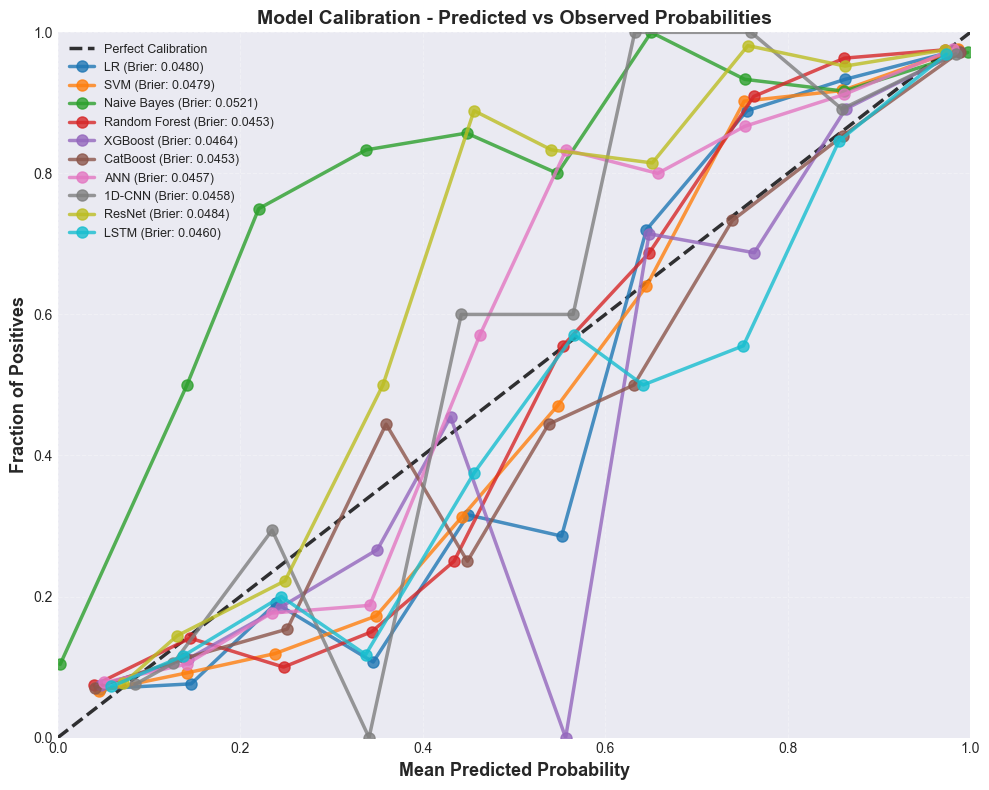


--------------------------------------------------------------------------------
BRIER SCORE RANKING (Lower = Better Calibration)
--------------------------------------------------------------------------------
   1. CatBoost            : 0.0453  ✓ Well-calibrated
   2. Random Forest       : 0.0453  ✓ Well-calibrated
   3. ANN                 : 0.0457  ✓ Well-calibrated
   4. 1D-CNN              : 0.0458  ✓ Well-calibrated
   5. LSTM                : 0.0460  ✓ Well-calibrated
   6. XGBoost             : 0.0464  ✓ Well-calibrated
   7. SVM                 : 0.0479  ✓ Well-calibrated
   8. LR                  : 0.0480  ✓ Well-calibrated
   9. ResNet              : 0.0484  ✓ Well-calibrated
  10. Naive Bayes         : 0.0521  ✓ Well-calibrated
--------------------------------------------------------------------------------

✓ Brier scores saved: adhd_results\brier_scores.csv


In [43]:
# ============================================================================
# CELL 46a: CALIBRATION CURVES
# ============================================================================

print("\n" + "=" * 80)
print("PROBABILITY CALIBRATION ANALYSIS")
print("=" * 80)

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import json
from pathlib import Path

def plot_calibration_curves(model_probs_dict, y_true, save_path='adhd_results/calibration_curve.png'):
    """Plot calibration curves for all models"""
    Path(save_path).parent.mkdir(parents=True, exist_ok=True)

    fig, ax = plt.subplots(figsize=(10, 8))
    ax.plot([0, 1], [0, 1], 'k--', label='Perfect Calibration', linewidth=2.5, alpha=0.8)

    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
              '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']

    brier_scores = {}

    for i, (model_name, y_prob) in enumerate(model_probs_dict.items()):
        y_prob = np.array(y_prob)
        if y_prob.ndim > 1:
            y_prob = y_prob[:, 1]

        try:
            fraction_pos, mean_pred = calibration_curve(
                y_true, y_prob, n_bins=10, strategy='uniform'
            )
            brier = brier_score_loss(y_true, y_prob)
            brier_scores[model_name] = brier

            ax.plot(mean_pred, fraction_pos,
                    marker='o', linewidth=2.5, markersize=8,
                    color=colors[i % len(colors)],
                    label=f'{model_name} (Brier: {brier:.4f})',
                    alpha=0.8)
        except Exception as e:
            print(f"  ⚠ {model_name}: Calibration failed - {str(e)[:50]}")
            continue

    ax.set_xlabel('Mean Predicted Probability', fontsize=13, fontweight='bold')
    ax.set_ylabel('Fraction of Positives', fontsize=13, fontweight='bold')
    ax.set_title('Model Calibration - Predicted vs Observed Probabilities',
                 fontsize=14, fontweight='bold')
    ax.legend(loc='upper left', fontsize=9, framealpha=0.95, edgecolor='black')
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.set_xlim([0, 1])
    ax.set_ylim([0, 1])

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    if brier_scores:
        print("\n" + "-" * 80)
        print("BRIER SCORE RANKING (Lower = Better Calibration)")
        print("-" * 80)
        sorted_brier = sorted(brier_scores.items(), key=lambda x: x[1])
        for rank, (model, score) in enumerate(sorted_brier, 1):
            status = "✓ Well-calibrated" if score < 0.10 else "⚠ Check"
            print(f"  {rank:2d}. {model:<20}: {score:.4f}  {status}")
        print("-" * 80)

        brier_df = pd.DataFrame({
            'Model': list(brier_scores.keys()),
            'Brier_Score': list(brier_scores.values())
        }).sort_values('Brier_Score')
        brier_path = Path(save_path).parent / 'brier_scores.csv'
        brier_df.to_csv(brier_path, index=False)
        print(f"\n✓ Brier scores saved: {brier_path}")

    return brier_scores

# ── JSON'dan pred_probas oku ──────────────────────────────────────────────
PROBA_PATH = Path('adhd_results/pred_probas.json')
model_probs = {}

if PROBA_PATH.exists():
    with open(PROBA_PATH, 'r') as f:
        proba_data = json.load(f)
    for model_name, probs in proba_data.items():
        model_probs[model_name] = np.array(probs)
    print(f"\n✓ Found {len(model_probs)} models in pred_probas.json")
else:
    print("⚠️ pred_probas.json not found.")
    print("   Add probability saving to each model cell:")
    print("   _proba_path = Path('adhd_results/pred_probas.json')")
    print("   _all_probas = json.load(open(_proba_path)) if _proba_path.exists() else {}")
    print("   _all_probas['ModelName'] = pred_proba_variable.tolist()")
    print("   with open(_proba_path, 'w') as f: json.dump(_all_probas, f)")

if model_probs:
    brier_results = plot_calibration_curves(model_probs, y_test)
else:
    print("\n⚠ No probability predictions found. Run model cells first.")

print("=" * 80)


MISCLASSIFICATION ANALYSIS - TOP 3 MODELS

────────────────────────────────────────────────────────────────────────────────
Random Forest
────────────────────────────────────────────────────────────────────────────────
  TP: 1432  |  TN:  426
  FP:   47  |  FN:   45
  Missed ADHD (FNR): 3.05%
  False Alarm (FPR): 9.94%


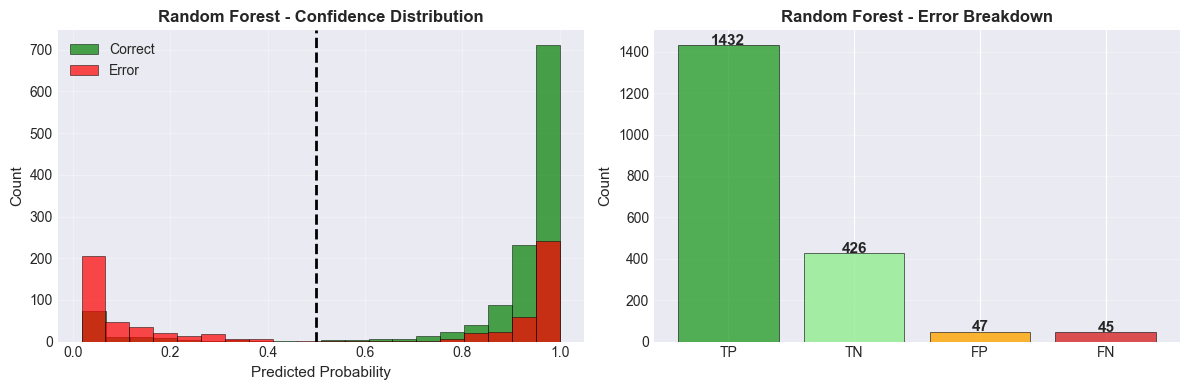

  ✓ Saved: adhd_results/error_analysis/random_forest_errors.png

────────────────────────────────────────────────────────────────────────────────
ANN
────────────────────────────────────────────────────────────────────────────────
  TP: 1430  |  TN:  424
  FP:   49  |  FN:   47
  Missed ADHD (FNR): 3.18%
  False Alarm (FPR): 10.36%


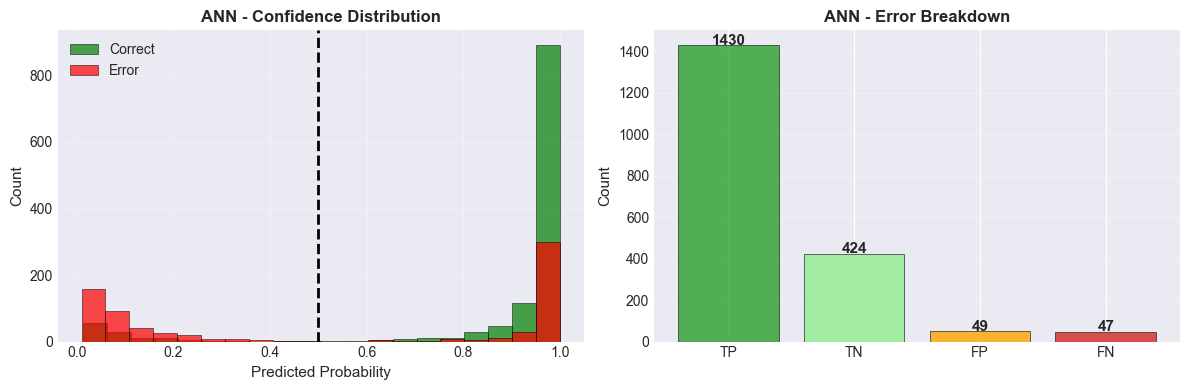

  ✓ Saved: adhd_results/error_analysis/ann_errors.png

────────────────────────────────────────────────────────────────────────────────
Naive Bayes
────────────────────────────────────────────────────────────────────────────────
  TP: 1428  |  TN:  424
  FP:   49  |  FN:   49
  Missed ADHD (FNR): 3.32%
  False Alarm (FPR): 10.36%


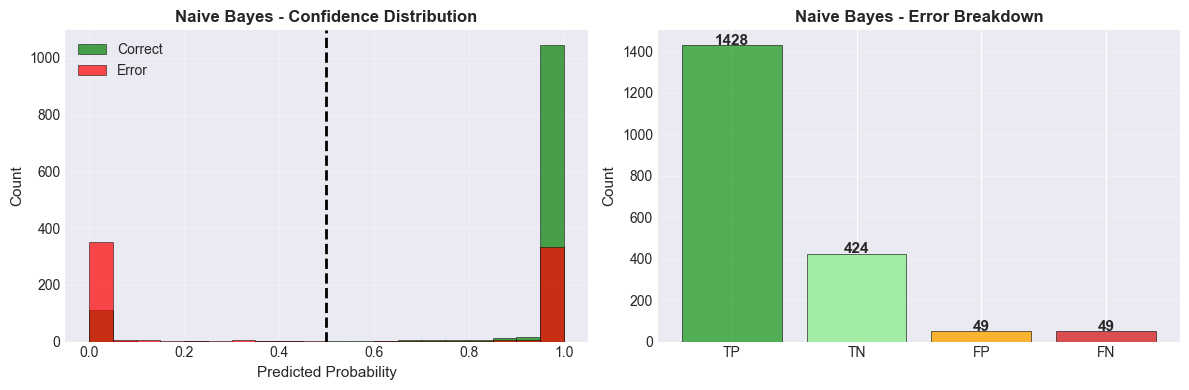

  ✓ Saved: adhd_results/error_analysis/naive_bayes_errors.png

ERROR RATE COMPARISON
                 fnr     fpr
Random Forest 3.0500  9.9400
ANN           3.1800 10.3600
Naive Bayes   3.3200 10.3600

✓ Error comparison saved: adhd_results/error_comparison.csv


In [44]:
# ============================================================================
# CELL 46b: ERROR ANALYSIS
# ============================================================================

print("\n" + "=" * 80)
print("MISCLASSIFICATION ANALYSIS - TOP 3 MODELS")
print("=" * 80)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
from pathlib import Path

def analyze_errors_from_cm(tp, tn, fp, fn, y_prob, model_name,
                           save_dir='adhd_results/error_analysis'):
    """Error analysis using TP/TN/FP/FN from JSON + proba for histogram"""
    Path(save_dir).mkdir(parents=True, exist_ok=True)

    fnr = fn / (fn + tp) * 100 if (fn + tp) > 0 else 0
    fpr = fp / (fp + tn) * 100 if (fp + tn) > 0 else 0

    print(f"\n{'─' * 80}")
    print(f"{model_name}")
    print(f"{'─' * 80}")
    print(f"  TP: {tp:4d}  |  TN: {tn:4d}")
    print(f"  FP: {fp:4d}  |  FN: {fn:4d}")
    print(f"  Missed ADHD (FNR): {fnr:.2f}%")
    print(f"  False Alarm (FPR): {fpr:.2f}%")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Sol grafik: Probability histogram (proba varsa)
    if y_prob is not None:
        y_prob = np.array(y_prob)
        if y_prob.ndim > 1:
            y_prob = y_prob[:, 1]
        # Tahmini doğru/yanlış ayrımı için threshold=0.5 kullan
        y_pred_hist = (y_prob >= 0.5).astype(int)
        n = len(y_prob)
        # Gerçek etiket oluştur (TP+FN = ADHD, TN+FP = No ADHD)
        y_true_hist = np.array([1]*(tp+fn) + [0]*(tn+fp))[:n]
        correct_hist = (y_true_hist == y_pred_hist)

        axes[0].hist(y_prob[correct_hist], bins=20, alpha=0.7,
                     label='Correct', color='green', edgecolor='black')
        axes[0].hist(y_prob[~correct_hist], bins=20, alpha=0.7,
                     label='Error', color='red', edgecolor='black')
        axes[0].axvline(0.5, color='black', linestyle='--', linewidth=2)
        axes[0].set_xlabel('Predicted Probability', fontsize=11)
        axes[0].set_ylabel('Count', fontsize=11)
        axes[0].set_title(f'{model_name} - Confidence Distribution',
                          fontsize=12, fontweight='bold')
        axes[0].legend()
        axes[0].grid(True, alpha=0.3)
    else:
        axes[0].text(0.5, 0.5, 'No probability data', ha='center',
                     va='center', transform=axes[0].transAxes, fontsize=13)
        axes[0].axis('off')

    # Sağ grafik: TP/TN/FP/FN bar
    labels = ['TP', 'TN', 'FP', 'FN']
    values = [tp, tn, fp, fn]
    colors = ['#2ca02c', '#90EE90', '#FFA500', '#d62728']

    bars = axes[1].bar(labels, values, color=colors, alpha=0.8, edgecolor='black')
    axes[1].set_ylabel('Count', fontsize=11)
    axes[1].set_title(f'{model_name} - Error Breakdown',
                      fontsize=12, fontweight='bold')
    axes[1].grid(True, alpha=0.3, axis='y')

    for bar, val in zip(bars, values):
        axes[1].text(bar.get_x() + bar.get_width() / 2, val + 3,
                     str(val), ha='center', fontsize=11, fontweight='bold')

    plt.tight_layout()
    save_path = f'{save_dir}/{model_name.lower().replace(" ", "_")}_errors.png'
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"  ✓ Saved: {save_path}")

    return {'fnr': fnr, 'fpr': fpr, 'n_fp': int(fp), 'n_fn': int(fn)}

# ── JSON'dan oku ──────────────────────────────────────────────────────────
model_results = load_results()
PROBA_PATH    = Path('adhd_results/pred_probas.json')
proba_data    = {}

if PROBA_PATH.exists():
    with open(PROBA_PATH, 'r') as f:
        proba_data = json.load(f)

# Top 3 modeli MCC'ye göre seç
if not model_results:
    print("❌ No model results found. Run model cells first.")
else:
    top3 = sorted(
        model_results.items(),
        key=lambda x: float(x[1].get('MCC', 0)),
        reverse=True
    )[:3]

    error_results = {}

    for model_name, metrics in top3:
        tp = int(metrics.get('TP', 0))
        tn = int(metrics.get('TN', 0))
        fp = int(metrics.get('FP', 0))
        fn = int(metrics.get('FN', 0))

        # Proba varsa al
        y_prob = np.array(proba_data[model_name]) if model_name in proba_data else None

        error_results[model_name] = analyze_errors_from_cm(
            tp, tn, fp, fn, y_prob, model_name
        )

    # Karşılaştırma tablosu
    if error_results:
        print("\n" + "=" * 80)
        print("ERROR RATE COMPARISON")
        print("=" * 80)
        error_df = pd.DataFrame(error_results).T
        print(error_df[['fnr', 'fpr']].round(2))
        error_df.to_csv('adhd_results/error_comparison.csv')
        print("\n✓ Error comparison saved: adhd_results/error_comparison.csv")

print("=" * 80)

In [45]:
# ============================================================
# FINAL SUMMARY - Results Already in JSON
# ============================================================

model_results = load_results()
model_time_results = load_timing()

print('=' * 80)
print('EXPERIMENT COMPLETE')
print('=' * 80)
print(f'Total models trained: {len(model_results)}')
print(f'Results directory: {OUTPUT_DIR}/')
print('\nFiles created:')
print(f'  • {RESULTS_JSON.name} (model performance metrics)')
print(f'  • {RESULTS_CSV.name} (CSV format)')
print(f'  • {TIMING_JSON.name} (timing data)')
print(f'  • {FOLDS_JSON.name} (CV fold scores)')
print('=' * 80)

# Display top 5 models
if model_results:
    import pandas as pd
    df = pd.DataFrame(model_results).T
    if 'MCC' in df.columns:
        print('\n📊 TOP 5 MODELS (by MCC):')
        top5 = df.sort_values('MCC', ascending=False)[['MCC', 'ROC_AUC', 'Accuracy', 'F1_Score']].head()
        display(top5)


EXPERIMENT COMPLETE
Total models trained: 10
Results directory: adhd_results/

Files created:
  • model_results.json (model performance metrics)
  • model_results.csv (CSV format)
  • model_timing.json (timing data)
  • fold_scores.json (CV fold scores)

📊 TOP 5 MODELS (by MCC):


,MCC,ROC_AUC,Accuracy,F1_Score
Random Forest,0.8714,0.9588,0.9528,0.9689
ANN,0.8658,0.9521,0.9508,0.9675
Naive Bayes,0.8632,0.9535,0.9497,0.9668
XGBoost,0.8630,0.9573,0.9497,0.9668
1D-CNN,0.8630,0.9539,0.9497,0.9668
